In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import matplotlib.font_manager as fm
from pandas.plotting import register_matplotlib_converters
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
from sklearn.preprocessing import MultiLabelBinarizer
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import acf
from scipy.stats.contingency import association
from scipy.stats import kruskal
import scipy.stats as stats



In [3]:
# some global styling prep

font_properties = fm.FontProperties(family="Times New Roman", size=14)
plt.rcParams["font.family"] = "Times New Roman"
register_matplotlib_converters()
sns.set_style("darkgrid")
plt.rc("figure", figsize=(16, 12))

<h3>Read-in Data</h3>

In [4]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32'
}

In [5]:
campd_tx = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned_Operating.csv", dtype=campd_type_dict, parse_dates=["Date"])

In [ ]:
# create a small df with all hours (fill non-operating hours with 0)

# define full hourly time range
full_time_range = pd.date_range(start="2019-01-01 00:00:00", end="2024-12-31 23:00:00", freq="h")

# get all unique combinations of Facility ID and Unit ID
facility_unit_combinations = campd_tx[["Facility ID", "Unit ID"]].drop_duplicates()

# create cartesian product of all combinations with the full time range (df with all unit and hour combos)
full_index = (
    facility_unit_combinations.assign(dummy=1)
    .merge(pd.DataFrame({"datetime": full_time_range, "dummy": 1}), on="dummy")
    .drop(columns=["dummy"])
)

# merge with original data
campd_tx_all_hours = full_index.merge(campd_tx[["Facility ID", "Unit ID", "datetime", "NOx Mass (lbs)", "CO2 Mass (short tons)", "SO2 Mass (lbs)"]], on=["Facility ID", "Unit ID", "datetime"], how="left")

# fill missing emission values with 0
campd_tx_all_hours["NOx Mass (lbs)"] = campd_tx_all_hours["NOx Mass (lbs)"].fillna(0)
campd_tx_all_hours["CO2 Mass (short tons)"] = campd_tx_all_hours["CO2 Mass (short tons)"].fillna(0)
campd_tx_all_hours["SO2 Mass (lbs)"] = campd_tx_all_hours["SO2 Mass (lbs)"].fillna(0)

campd_tx_all_hours.to_csv("TX/Hourly/Concatted File/tx_2019_2024_all_hours_emissions_only.csv", index=False)

In [4]:
campd_tx_all_hours = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_all_hours_emissions_only.csv", dtype=campd_type_dict)
campd_tx_all_hours["datetime"] = pd.to_datetime(campd_tx_all_hours["datetime"])

In [62]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Operating.csv", dtype=campd_type_dict, parse_dates=["Date"])

In [7]:
# create full datetime column (date + hour)
campd_ny["datetime"] = pd.to_datetime(campd_ny["Date"].astype(str) + ' ' + campd_ny["Hour"].astype(str).str.zfill(2) + ":00:00")

In [ ]:
# create a small df with all hours (fill non-operating hours with 0)

# define the full hourly time range
full_time_range = pd.date_range(start="2019-01-01 00:00:00", end="2024-12-31 23:00:00", freq="h")

# get all unique combinations of Facility ID and Unit ID
facility_unit_combinations = campd_ny[["Facility ID", "Unit ID"]].drop_duplicates()

# create cartesian product of all combinations with the full time range (df with all unit and hour combos)
full_index = (
    facility_unit_combinations.assign(dummy=1)
    .merge(pd.DataFrame({"datetime": full_time_range, "dummy": 1}), on="dummy")
    .drop(columns=["dummy"])
)

# merge with original data
campd_ny_all_hours = full_index.merge(campd_ny[["Facility ID", "Unit ID", "datetime", "NOx Mass (lbs)", "CO2 Mass (short tons)", "SO2 Mass (lbs)"]], on=["Facility ID", "Unit ID", "datetime"], how="left")

# fill missing emission values with 0
campd_ny_all_hours["NOx Mass (lbs)"] = campd_ny_all_hours["NOx Mass (lbs)"].fillna(0)
campd_ny_all_hours["CO2 Mass (short tons)"] = campd_ny_all_hours["CO2 Mass (short tons)"].fillna(0)
campd_ny_all_hours["SO2 Mass (lbs)"] = campd_ny_all_hours["SO2 Mass (lbs)"].fillna(0)

campd_ny_all_hours.to_csv("NY/Hourly/Concatted File/ny_2019_2024_all_hours_emissions_only.csv", index=False)

In [66]:
campd_ny_all_hours = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_all_hours_emissions_only.csv", dtype=campd_type_dict)
campd_ny_all_hours["datetime"] = pd.to_datetime(campd_ny_all_hours["datetime"])

In [72]:
campd_wy = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_complete_cleaned_Operating.csv", dtype=campd_type_dict, parse_dates=["Date"])

In [10]:
# create full datetime column (date + hour)
campd_wy["datetime"] = pd.to_datetime(campd_wy["Date"].astype(str) + ' ' + campd_wy["Hour"].astype(str).str.zfill(2) + ":00:00")

In [ ]:
# create a small df with all hours (fill non-operating hours with 0)

# define the full hourly time range
full_time_range = pd.date_range(start="2019-01-01 00:00:00", end="2024-12-31 23:00:00", freq="h")

# get all unique combinations of Facility ID and Unit ID
facility_unit_combinations = campd_wy[["Facility ID", "Unit ID"]].drop_duplicates()

# create cartesian product of all combinations with the full time range (df with all unit and hour combos)
full_index = (
    facility_unit_combinations.assign(dummy=1)
    .merge(pd.DataFrame({"datetime": full_time_range, "dummy": 1}), on="dummy")
    .drop(columns=["dummy"])
)

# merge with original data
campd_wy_all_hours = full_index.merge(campd_wy[["Facility ID", "Unit ID", "datetime", "NOx Mass (lbs)", "CO2 Mass (short tons)", "SO2 Mass (lbs)"]], on=["Facility ID", "Unit ID", "datetime"], how="left")

# fill missing emission values with 0
campd_wy_all_hours["NOx Mass (lbs)"] = campd_wy_all_hours["NOx Mass (lbs)"].fillna(0)
campd_wy_all_hours["CO2 Mass (short tons)"] = campd_wy_all_hours["CO2 Mass (short tons)"].fillna(0)
campd_wy_all_hours["SO2 Mass (lbs)"] = campd_wy_all_hours["SO2 Mass (lbs)"].fillna(0)

campd_wy_all_hours.to_csv("WY/Hourly/Concatted File/wy_2019_2024_all_hours_emissions_only.csv", index=False)

In [67]:
campd_wy_all_hours = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_all_hours_emissions_only.csv", dtype=campd_type_dict)
campd_wy_all_hours["datetime"] = pd.to_datetime(campd_wy_all_hours["datetime"])

In [8]:
print("WY Data Shape:", campd_wy.shape)
print("NY Data Shape:", campd_ny.shape)
print("TX Data Shape:", campd_tx.shape)

WY Data Shape: (993428, 52)
NY Data Shape: (2400701, 53)
TX Data Shape: (9262325, 53)


In [ ]:
# get daily emission data

# Concat all daily csv files into a single df each

# Wyoming
wy_folder = Path('WY/Daily')
df_list_wy = []
for file in wy_folder.iterdir():
    if file.is_file() and file.name.endswith('.csv'):
        df = pd.read_csv(file)
        df_list_wy.append(df)

campd_daily_wy = pd.concat(df_list_wy, ignore_index=True)

# Filter out rows with NaN values in emission columns
campd_daily_wy = campd_daily_wy[
    ~(campd_daily_wy["SO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_wy["CO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_wy["NOx Mass (short tons)"].isna())
]

# Texas
tx_folder = Path('TX/Daily')
df_list_tx = []
for file in tx_folder.iterdir():
    if file.is_file() and file.name.endswith('.csv'):
        df = pd.read_csv(file)
        df_list_tx.append(df)

campd_daily_tx = pd.concat(df_list_tx, ignore_index=True)

# Filter out rows with NaN values in emission columns
campd_daily_tx = campd_daily_tx[
    ~(campd_daily_tx["SO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_tx["CO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_tx["NOx Mass (short tons)"].isna())
]

# New York
ny_folder = Path('NY/Daily')
df_list_ny = []
for file in ny_folder.iterdir():
    if file.is_file() and file.name.endswith('.csv'):
        df = pd.read_csv(file)
        df_list_ny.append(df)

campd_daily_ny = pd.concat(df_list_ny, ignore_index=True)

# Filter out rows with NaN values in emission columns
campd_daily_ny = campd_daily_ny[
    ~(campd_daily_ny["SO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_ny["CO2 Mass (short tons)"].isna()) & 
    ~(campd_daily_ny["NOx Mass (short tons)"].isna())
]

In [32]:
# daily data for new york is missing in 2010 so we aggregate the hourly data from that year and add it to the daily data
campd_2010_ny = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2010-ny.csv", dtype=campd_type_dict, parse_dates=["Date"])

# convert from lbs to short tons (daily data has short tons)
campd_2010_ny["NOx Mass (short tons)"] = campd_2010_ny["NOx Mass (lbs)"] / 2000
campd_2010_ny["SO2 Mass (short tons)"] = campd_2010_ny["SO2 Mass (lbs)"] / 2000

# narrow columns
campd_2010_ny = campd_2010_ny[["State","Facility ID", "Unit ID", "Date", "Hour", "CO2 Mass (short tons)", "NOx Mass (short tons)", "SO2 Mass (short tons)"]]

# group by Date, Facility ID, and Unit ID, then sum CO2, NOx, and SO2 mass
daily_mass_2010 = campd_2010_ny.groupby(["State", "Facility ID", "Unit ID", "Date"])[["CO2 Mass (short tons)", "NOx Mass (short tons)", "SO2 Mass (short tons)"]].sum().reset_index()

display(daily_mass_2010)

C:\Users\marce\AppData\Local\Temp\ipykernel_42216\151159377.py:2: DtypeWarning: Columns (4,29,30) have mixed types. Specify dtype option on import or set low_memory=False.
  campd_2010_ny = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2010-ny.csv", dtype=campd_type_dict, parse_dates=["Date"])


,State,Facility ID,Unit ID,Date,CO2 Mass (short tons),NOx Mass (short tons),SO2 Mass (short tons)
0,NY,2480,1,2010-01-01,0.0,0.000000,0.0
1,NY,2480,1,2010-01-02,0.0,0.000000,0.0
2,NY,2480,1,2010-01-03,0.0,0.000000,0.0
3,NY,2480,1,2010-01-04,0.0,0.000000,0.0
4,NY,2480,1,2010-01-05,0.0,0.000000,0.0
...,...,...,...,...,...,...,...
107070,NY,880100,BLR004,2010-12-27,0.0,0.153850,0.0
107071,NY,880100,BLR004,2010-12-28,0.0,0.000000,0.0
107072,NY,880100,BLR004,2010-12-29,0.0,0.086375,0.0
107073,NY,880100,BLR004,2010-12-30,0.0,0.000000,0.0


In [33]:
# add aggregated data to the daily df
campd_daily_ny = pd.concat([campd_daily_ny, campd_2010_ny], ignore_index=True)

<h3>Emission Trends, Seasonality, Cycles</h3>

<h4>Last 5Y (using hourly data)</h4>

In [ ]:
# Set date as index for resampling
campd_ny.set_index('Date', inplace=True)
campd_tx.set_index('Date', inplace=True)
campd_wy.set_index('Date', inplace=True)

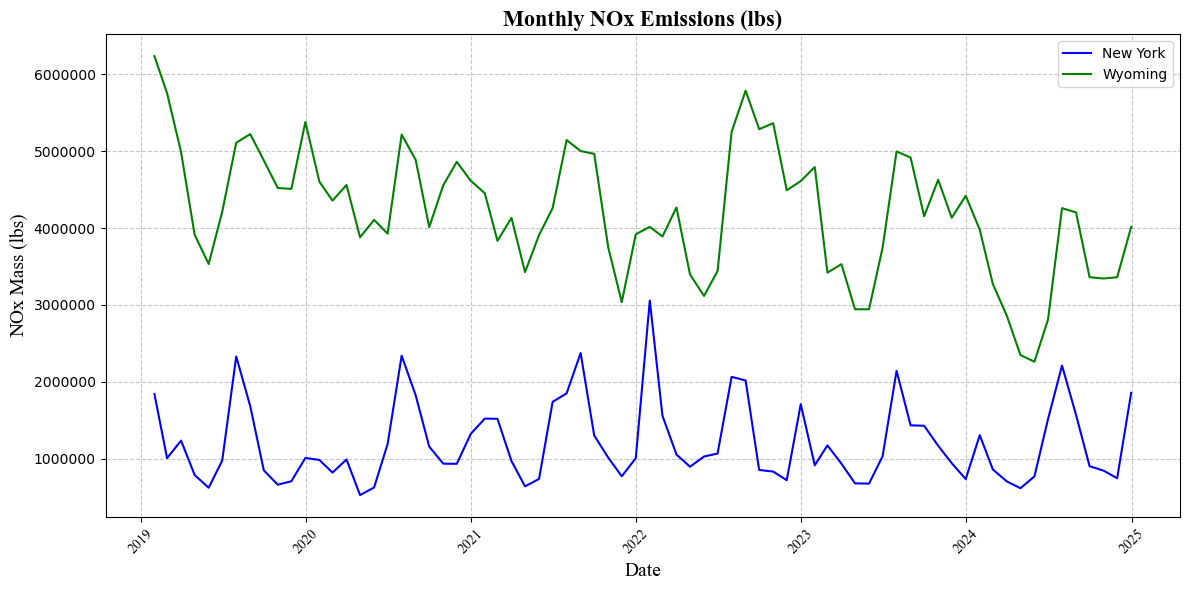

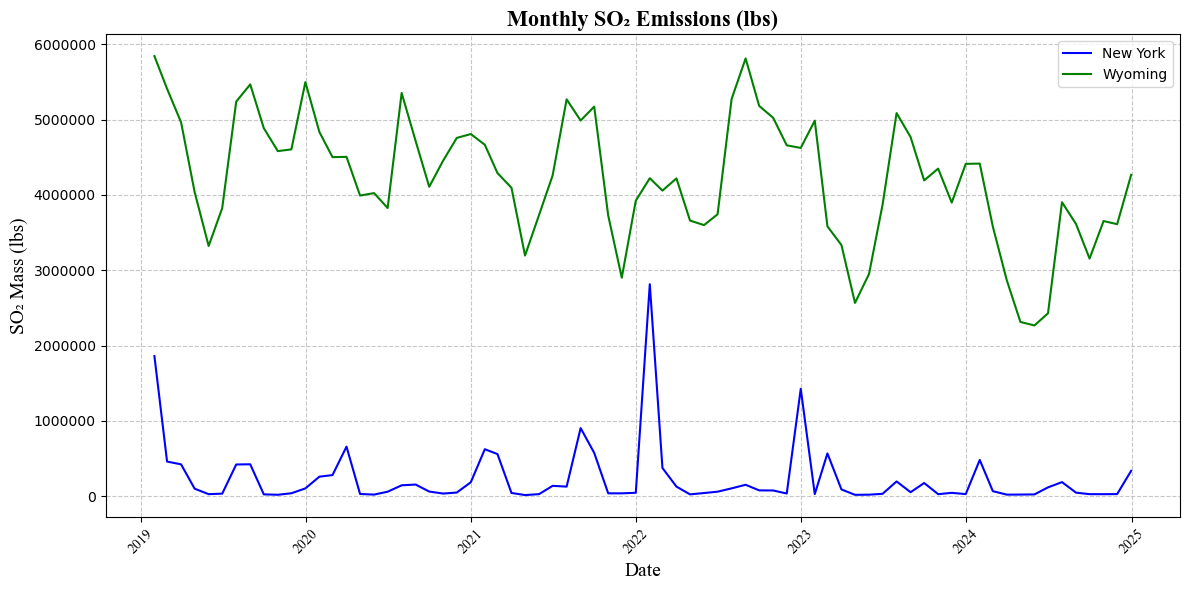

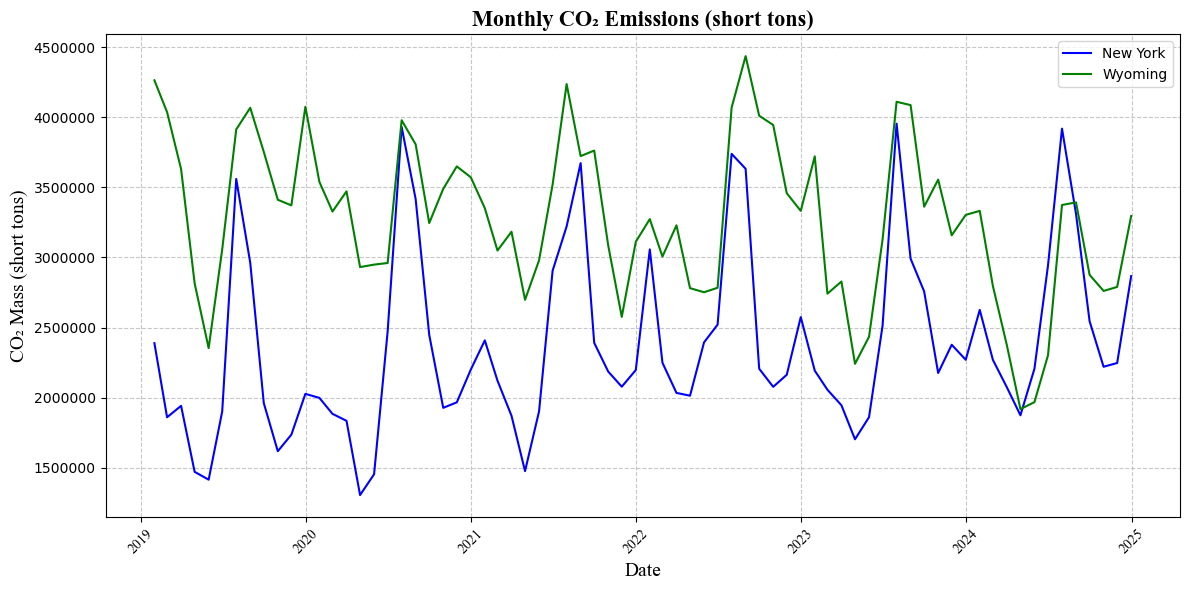

In [ ]:
# Resample to monthly NOx emissions (sum)
emissions_by_month_ny = campd_ny["NOx Mass (lbs)"].resample('ME').sum()
emissions_by_month_wy = campd_wy["NOx Mass (lbs)"].resample('ME').sum()

# Plot NOx
plt.figure(figsize=(12, 6))

plt.plot(emissions_by_month_ny.index, emissions_by_month_ny.values, color='b', label='New York')
plt.plot(emissions_by_month_wy.index, emissions_by_month_wy.values, color='g', label='Wyoming')

plt.title('Monthly NOx Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
plt.xlabel('Date', fontsize=14, fontname="Times New Roman")
plt.ylabel('NOx Mass (lbs)', fontsize=14, fontname="Times New Roman")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.xticks(rotation=45, fontname="Times New Roman")

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

# Resample to monthly SO2 emissions (sum)
emissions_by_month_ny = campd_ny["SO2 Mass (lbs)"].resample('ME').sum()
emissions_by_month_wy = campd_wy["SO2 Mass (lbs)"].resample('ME').sum()

# Plot SO2
plt.figure(figsize=(12, 6))

plt.plot(emissions_by_month_ny.index, emissions_by_month_ny.values, color='b', label='New York')
plt.plot(emissions_by_month_wy.index, emissions_by_month_wy.values, color='g', label='Wyoming')

plt.title('Monthly SO₂ Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
plt.xlabel('Date', fontsize=14, fontname="Times New Roman")
plt.ylabel('SO₂ Mass (lbs)', fontsize=14, fontname="Times New Roman")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.xticks(rotation=45, fontname="Times New Roman")

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

# Resample to monthly CO2 emissions (sum)
emissions_by_month_ny = campd_ny["CO2 Mass (short tons)"].resample('ME').sum()
emissions_by_month_wy = campd_wy["CO2 Mass (short tons)"].resample('ME').sum()

# Plot CO2
plt.figure(figsize=(12, 6))

plt.plot(emissions_by_month_ny.index, emissions_by_month_ny.values, color='b', label='New York')
plt.plot(emissions_by_month_wy.index, emissions_by_month_wy.values, color='g', label='Wyoming')

plt.title('Monthly CO₂ Emissions (short tons)', fontsize=16, fontname="Times New Roman", fontweight="bold")
plt.xlabel('Date', fontsize=14, fontname="Times New Roman")
plt.ylabel('CO₂ Mass (short tons)', fontsize=14, fontname="Times New Roman")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.xticks(rotation=45, fontname="Times New Roman")

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

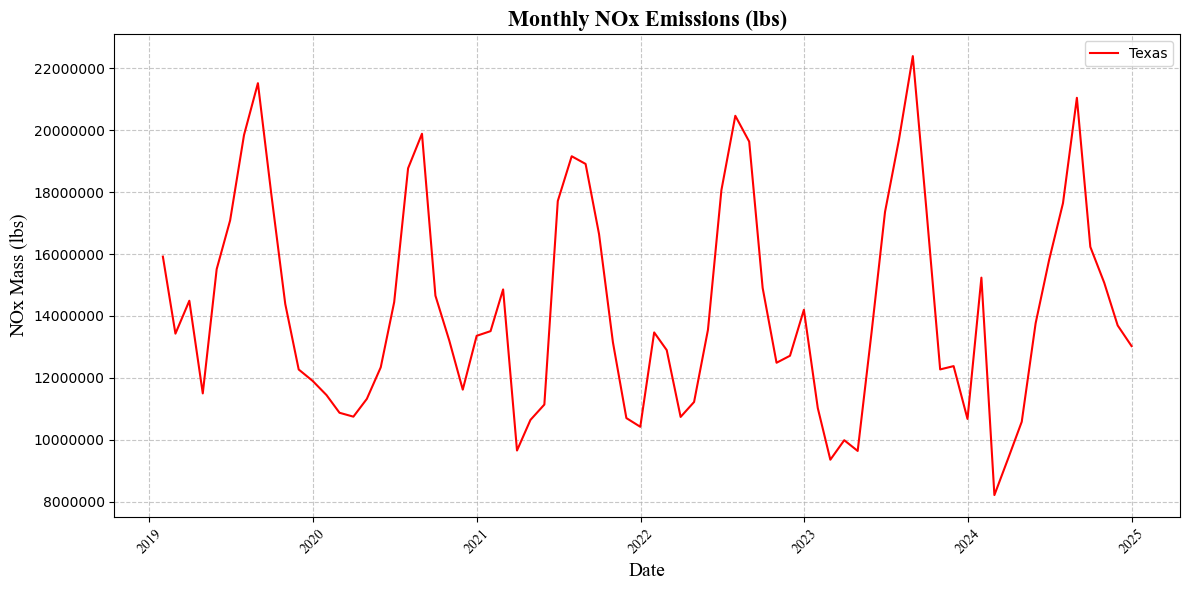

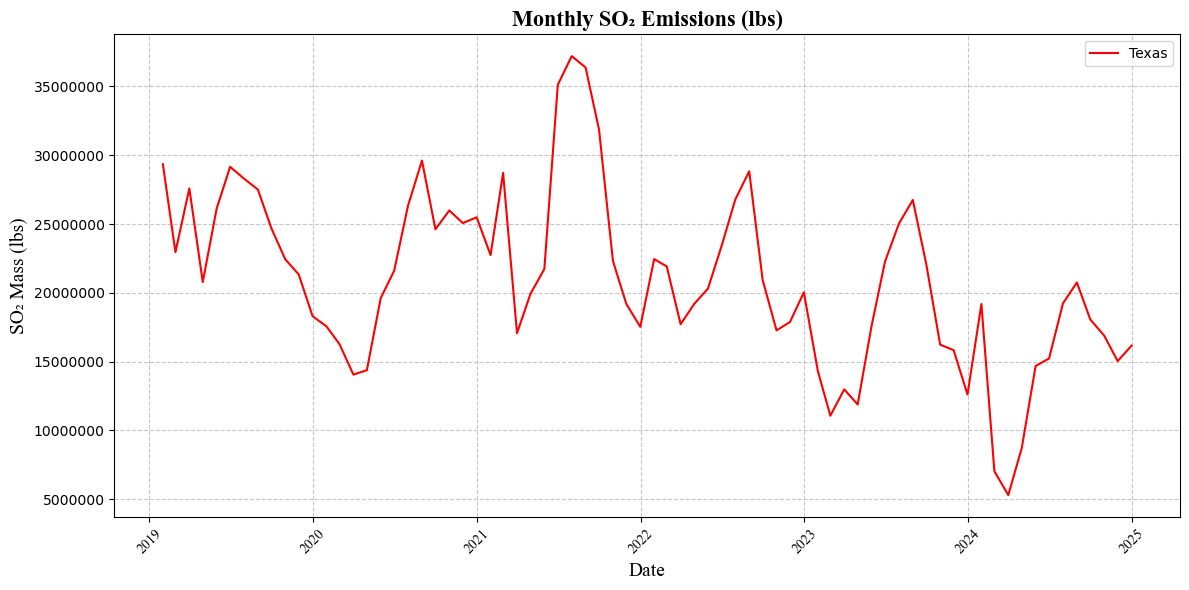

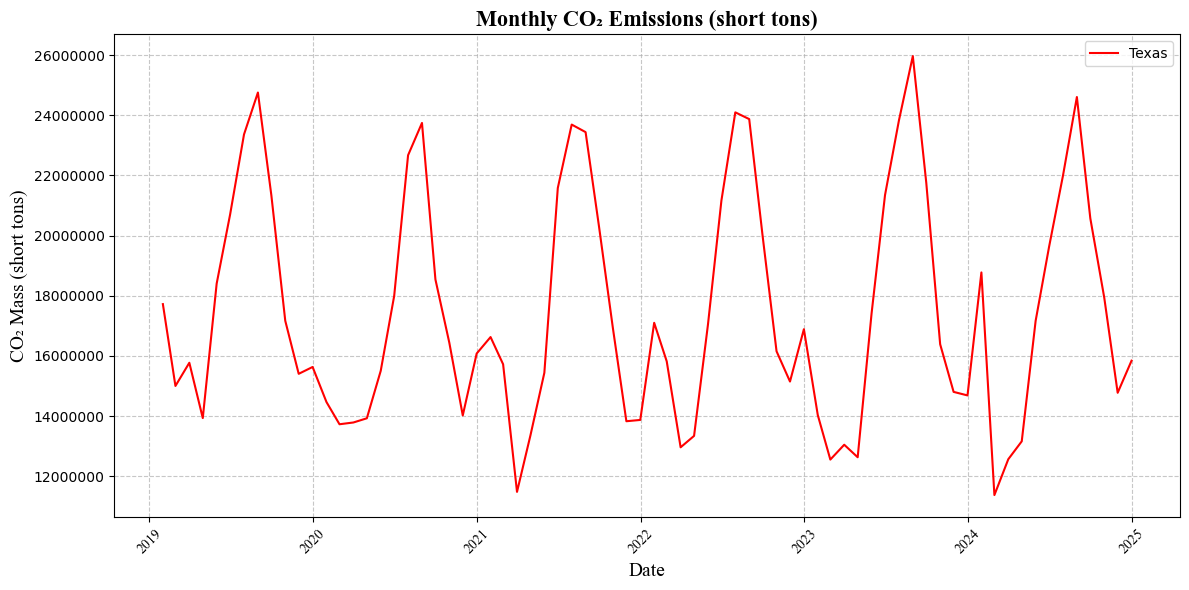

In [ ]:
# Resample to monthly NOx emissions (sum)
emissions_by_month_tx = campd_tx["NOx Mass (lbs)"].resample('ME').sum()

# Plot NOx
plt.figure(figsize=(12, 6))

plt.plot(emissions_by_month_tx.index, emissions_by_month_tx.values, color='r', label='Texas')

plt.title('Monthly NOx Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
plt.xlabel('Date', fontsize=14, fontname="Times New Roman")
plt.ylabel('NOx Mass (lbs)', fontsize=14, fontname="Times New Roman")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.xticks(rotation=45, fontname="Times New Roman")

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

# Resample to monthly SO2 emissions (sum)
emissions_by_month_tx = campd_tx["SO2 Mass (lbs)"].resample('ME').sum()

# Plot SO2
plt.figure(figsize=(12, 6))

plt.plot(emissions_by_month_tx.index, emissions_by_month_tx.values, color='r', label='Texas')

plt.title('Monthly SO₂ Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
plt.xlabel('Date', fontsize=14, fontname="Times New Roman")
plt.ylabel('SO₂ Mass (lbs)', fontsize=14, fontname="Times New Roman")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.xticks(rotation=45, fontname="Times New Roman")

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

# Resample to monthly CO2 emissions (sum)
emissions_by_month_tx = campd_tx["CO2 Mass (short tons)"].resample('ME').sum()

# Plot CO2
plt.figure(figsize=(12, 6))

plt.plot(emissions_by_month_tx.index, emissions_by_month_tx.values, color='r', label='Texas')

plt.title('Monthly CO₂ Emissions (short tons)', fontsize=16, fontname="Times New Roman", fontweight="bold")
plt.xlabel('Date', fontsize=14, fontname="Times New Roman")
plt.ylabel('CO₂ Mass (short tons)', fontsize=14, fontname="Times New Roman")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.xticks(rotation=45, fontname="Times New Roman")

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

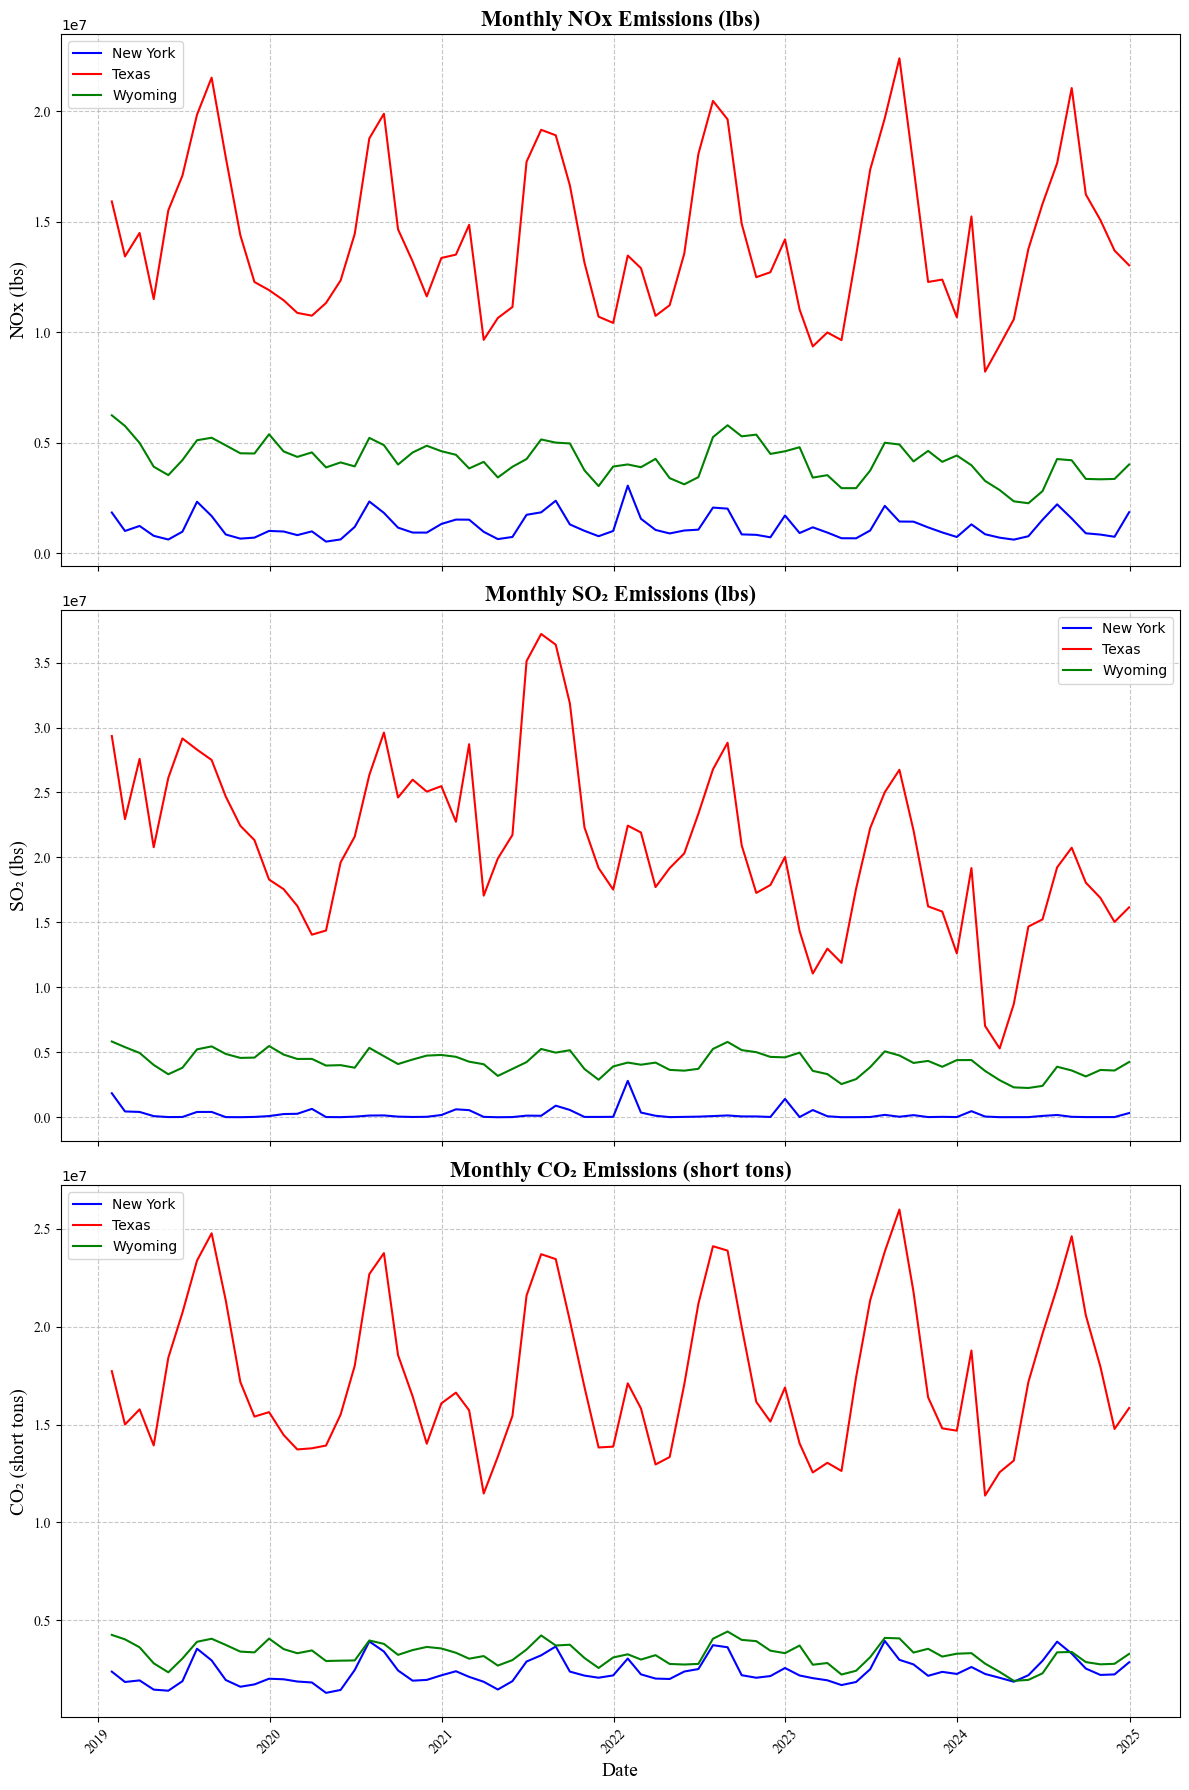

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 18), sharex=True)

# NOx

# Resample to monthly NOx emissions (sum)
emissions_by_month_ny = campd_ny["NOx Mass (lbs)"].resample('ME').sum()
emissions_by_month_tx = campd_tx["NOx Mass (lbs)"].resample('ME').sum()
emissions_by_month_wy = campd_wy["NOx Mass (lbs)"].resample('ME').sum()

axes[0].plot(emissions_by_month_ny.index, emissions_by_month_ny.values, 'b', label='New York')
axes[0].plot(emissions_by_month_tx.index, emissions_by_month_tx.values, 'r', label='Texas')
axes[0].plot(emissions_by_month_wy.index, emissions_by_month_wy.values, 'g', label='Wyoming')
axes[0].set_title('Monthly NOx Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[0].set_ylabel('NOx (lbs)', fontsize=14, fontname="Times New Roman")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.7)

# SO2

# Resample to monthly SO2 emissions (sum)
emissions_by_month_ny = campd_ny["SO2 Mass (lbs)"].resample('ME').sum()
emissions_by_month_tx = campd_tx["SO2 Mass (lbs)"].resample('ME').sum()
emissions_by_month_wy = campd_wy["SO2 Mass (lbs)"].resample('ME').sum()

axes[1].plot(emissions_by_month_ny.index, emissions_by_month_ny.values, 'b', label='New York')
axes[1].plot(emissions_by_month_tx.index, emissions_by_month_tx.values, 'r', label='Texas')
axes[1].plot(emissions_by_month_wy.index, emissions_by_month_wy.values, 'g', label='Wyoming')
axes[1].set_title('Monthly SO₂ Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[1].set_ylabel('SO₂ (lbs)', fontsize=14, fontname="Times New Roman")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.7)

# CO2

# Resample to monthly CO2 emissions (sum)
emissions_by_month_ny = campd_ny["CO2 Mass (short tons)"].resample('ME').sum()
emissions_by_month_tx = campd_tx["CO2 Mass (short tons)"].resample('ME').sum()
emissions_by_month_wy = campd_wy["CO2 Mass (short tons)"].resample('ME').sum()

axes[2].plot(emissions_by_month_ny.index, emissions_by_month_ny.values, 'b', label='New York')
axes[2].plot(emissions_by_month_tx.index, emissions_by_month_tx.values, 'r', label='Texas')
axes[2].plot(emissions_by_month_wy.index, emissions_by_month_wy.values, 'g', label='Wyoming')
axes[2].set_title('Monthly CO₂ Emissions (short tons)', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[2].set_xlabel('Date', fontsize=14, fontname="Times New Roman")
axes[2].set_ylabel('CO₂ (short tons)', fontsize=14, fontname="Times New Roman")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.7)

# formatting
for ax in axes:
    ax.ticklabel_format(style='plain', axis='y')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
    ax.tick_params(axis='x', rotation=45, labelsize=10)
    for label in ax.get_xticklabels():
        label.set_fontname("Times New Roman")
    for label in ax.get_yticklabels():
        label.set_fontname("Times New Roman")

plt.tight_layout()
plt.show()

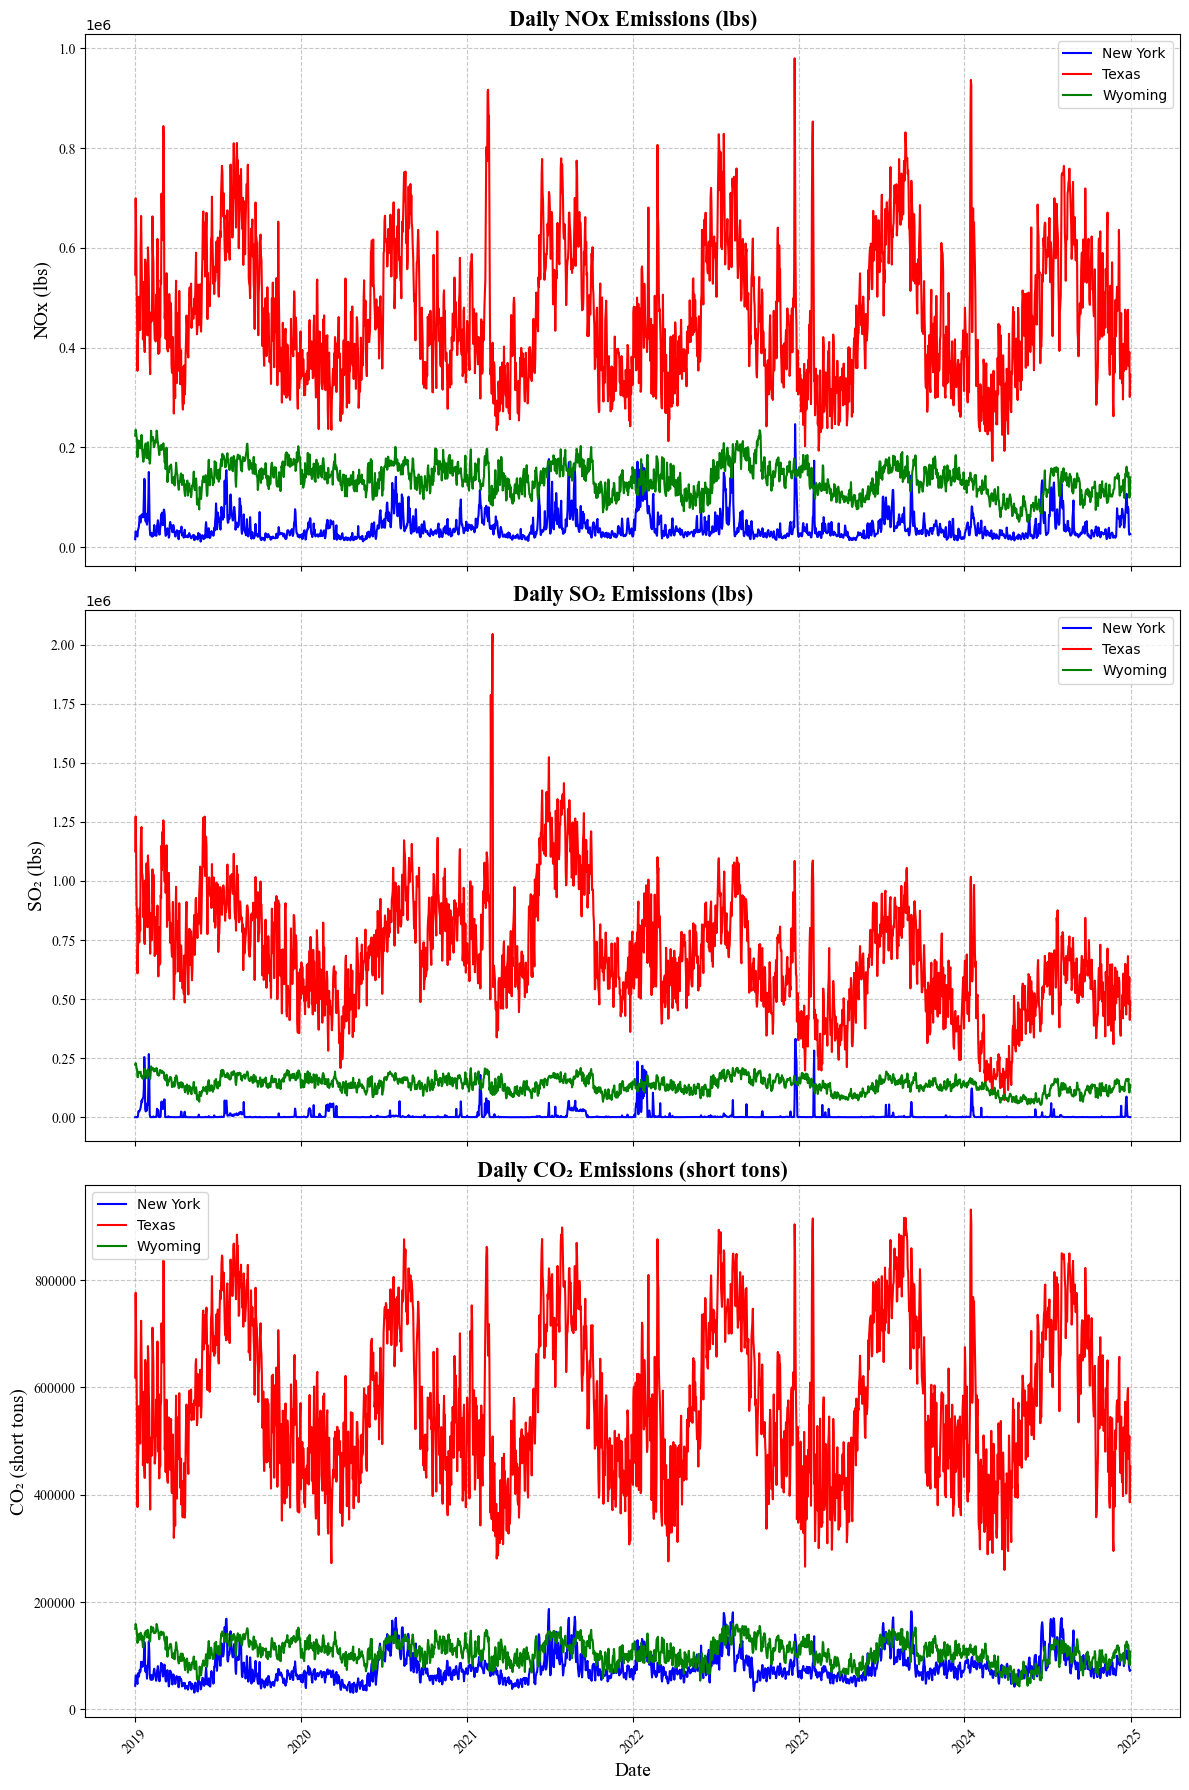

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 18), sharex=True)

# NOx

# Resample to monthly NOx emissions (sum)
emissions_by_month_ny = campd_ny["NOx Mass (lbs)"].resample('D').sum()
emissions_by_month_tx = campd_tx["NOx Mass (lbs)"].resample('D').sum()
emissions_by_month_wy = campd_wy["NOx Mass (lbs)"].resample('D').sum()

axes[0].plot(emissions_by_month_ny.index, emissions_by_month_ny.values, 'b', label='New York')
axes[0].plot(emissions_by_month_tx.index, emissions_by_month_tx.values, 'r', label='Texas')
axes[0].plot(emissions_by_month_wy.index, emissions_by_month_wy.values, 'g', label='Wyoming')
axes[0].set_title('Daily NOx Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[0].set_ylabel('NOx (lbs)', fontsize=14, fontname="Times New Roman")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.7)

# SO2

# Resample to monthly SO2 emissions (sum)
emissions_by_month_ny = campd_ny["SO2 Mass (lbs)"].resample('D').sum()
emissions_by_month_tx = campd_tx["SO2 Mass (lbs)"].resample('D').sum()
emissions_by_month_wy = campd_wy["SO2 Mass (lbs)"].resample('D').sum()

axes[1].plot(emissions_by_month_ny.index, emissions_by_month_ny.values, 'b', label='New York')
axes[1].plot(emissions_by_month_tx.index, emissions_by_month_tx.values, 'r', label='Texas')
axes[1].plot(emissions_by_month_wy.index, emissions_by_month_wy.values, 'g', label='Wyoming')
axes[1].set_title('Daily SO₂ Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[1].set_ylabel('SO₂ (lbs)', fontsize=14, fontname="Times New Roman")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.7)

# CO2

# Resample to monthly CO2 emissions (sum)
emissions_by_month_ny = campd_ny["CO2 Mass (short tons)"].resample('D').sum()
emissions_by_month_tx = campd_tx["CO2 Mass (short tons)"].resample('D').sum()
emissions_by_month_wy = campd_wy["CO2 Mass (short tons)"].resample('D').sum()

axes[2].plot(emissions_by_month_ny.index, emissions_by_month_ny.values, 'b', label='New York')
axes[2].plot(emissions_by_month_tx.index, emissions_by_month_tx.values, 'r', label='Texas')
axes[2].plot(emissions_by_month_wy.index, emissions_by_month_wy.values, 'g', label='Wyoming')
axes[2].set_title('Daily CO₂ Emissions (short tons)', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[2].set_xlabel('Date', fontsize=14, fontname="Times New Roman")
axes[2].set_ylabel('CO₂ (short tons)', fontsize=14, fontname="Times New Roman")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.7)

# formatting
for ax in axes:
    ax.ticklabel_format(style='plain', axis='y')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
    ax.tick_params(axis='x', rotation=45, labelsize=10)
    for label in ax.get_xticklabels():
        label.set_fontname("Times New Roman")
    for label in ax.get_yticklabels():
        label.set_fontname("Times New Roman")

plt.tight_layout()
plt.show()

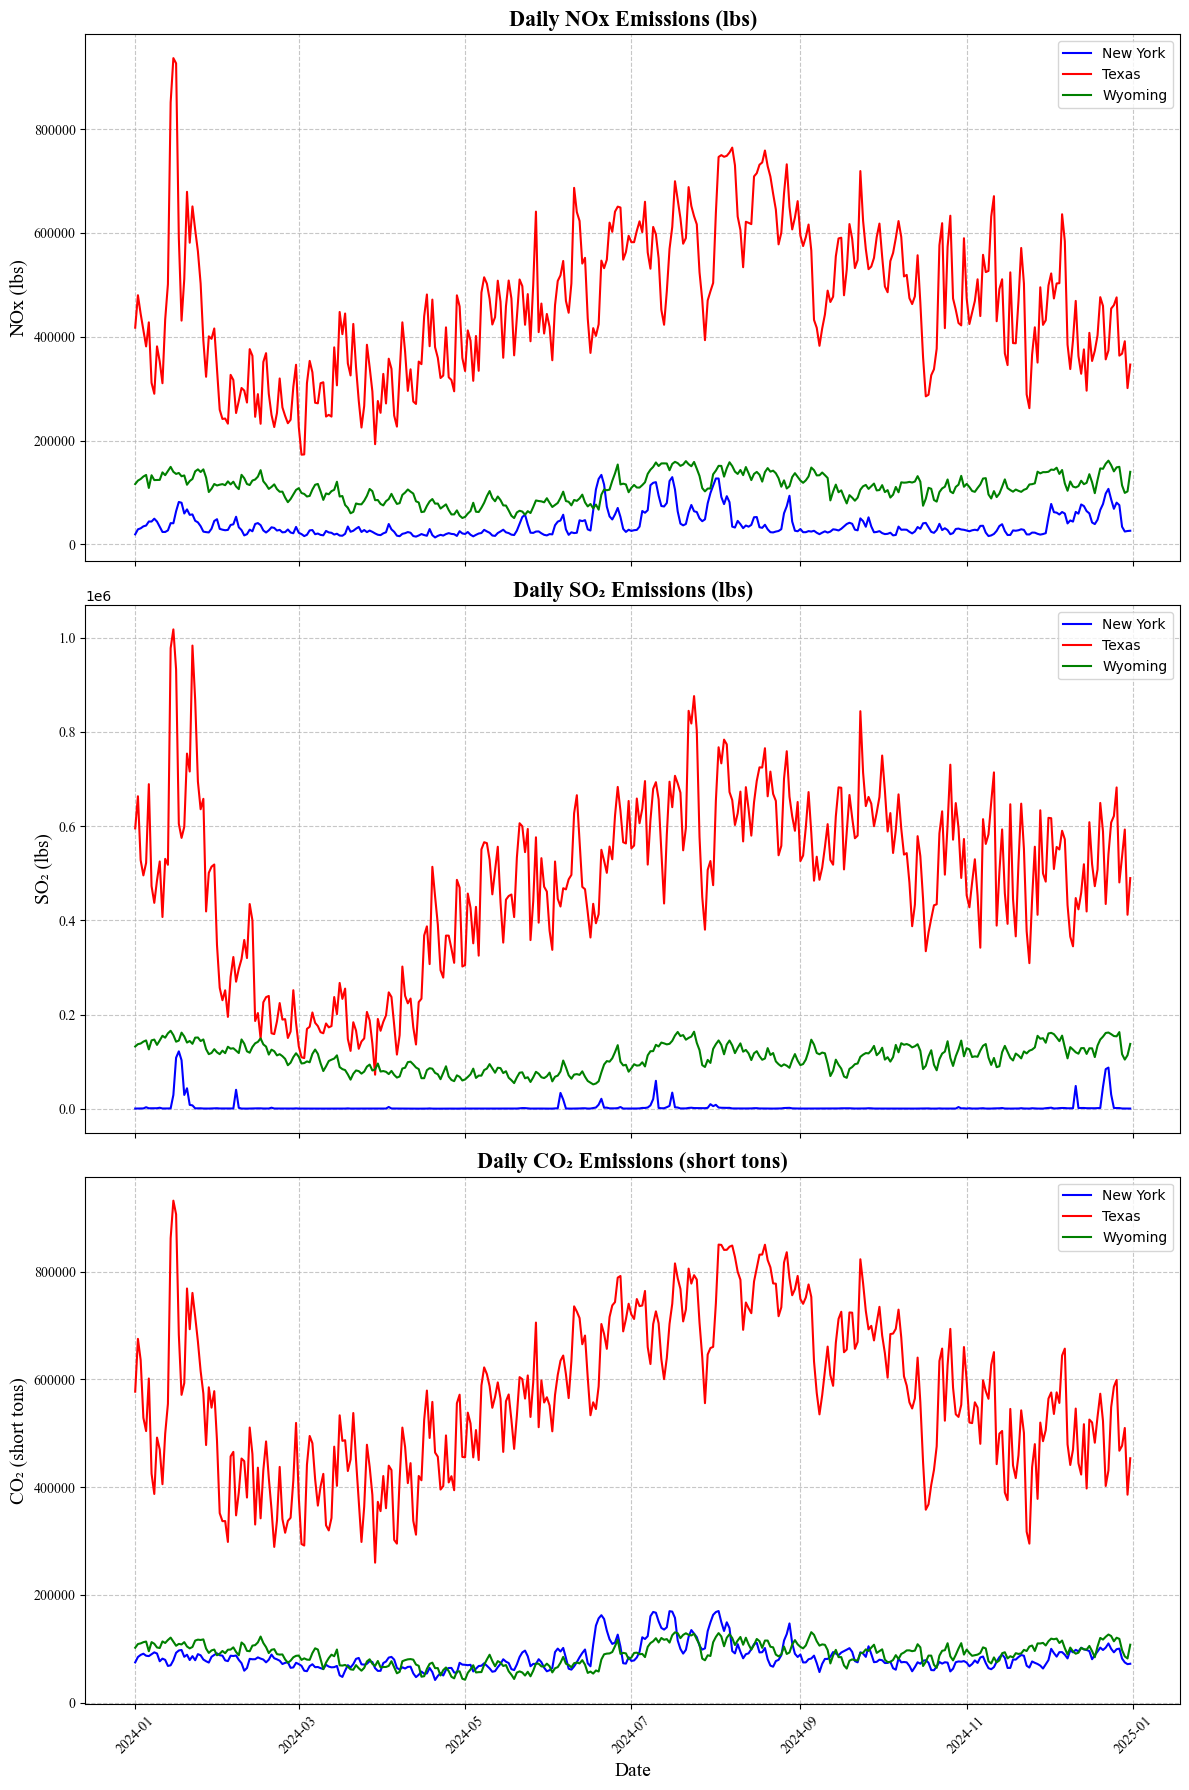

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 18), sharex=True)

# NOx
emissions_by_day_ny = campd_ny["NOx Mass (lbs)"].resample('D').sum()['2024']
emissions_by_day_tx = campd_tx["NOx Mass (lbs)"].resample('D').sum()['2024']
emissions_by_day_wy = campd_wy["NOx Mass (lbs)"].resample('D').sum()['2024']
axes[0].plot(emissions_by_day_ny.index, emissions_by_day_ny.values, 'b', label='New York')
axes[0].plot(emissions_by_day_tx.index, emissions_by_day_tx.values, 'r', label='Texas')
axes[0].plot(emissions_by_day_wy.index, emissions_by_day_wy.values, 'g', label='Wyoming')
axes[0].set_title('Daily NOx Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[0].set_ylabel('NOx (lbs)', fontsize=14, fontname="Times New Roman")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.7)

# SO2
so2_by_day_ny = campd_ny["SO2 Mass (lbs)"].resample('D').sum()['2024']
so2_by_day_tx = campd_tx["SO2 Mass (lbs)"].resample('D').sum()['2024']
so2_by_day_wy = campd_wy["SO2 Mass (lbs)"].resample('D').sum()['2024']
axes[1].plot(so2_by_day_ny.index, so2_by_day_ny.values, 'b', label='New York')
axes[1].plot(so2_by_day_tx.index, so2_by_day_tx.values, 'r', label='Texas')
axes[1].plot(so2_by_day_wy.index, so2_by_day_wy.values, 'g', label='Wyoming')
axes[1].set_title('Daily SO₂ Emissions (lbs)', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[1].set_ylabel('SO₂ (lbs)', fontsize=14, fontname="Times New Roman")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.7)

# CO2
co2_by_day_ny = campd_ny["CO2 Mass (short tons)"].resample('D').sum()['2024']
co2_by_day_tx = campd_tx["CO2 Mass (short tons)"].resample('D').sum()['2024']
co2_by_day_wy = campd_wy["CO2 Mass (short tons)"].resample('D').sum()['2024']
axes[2].plot(co2_by_day_ny.index, co2_by_day_ny.values, 'b', label='New York')
axes[2].plot(co2_by_day_tx.index, co2_by_day_tx.values, 'r', label='Texas')
axes[2].plot(co2_by_day_wy.index, co2_by_day_wy.values, 'g', label='Wyoming')
axes[2].set_title('Daily CO₂ Emissions (short tons)', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[2].set_xlabel('Date', fontsize=14, fontname="Times New Roman")
axes[2].set_ylabel('CO₂ (short tons)', fontsize=14, fontname="Times New Roman")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.7)

# formatting
for ax in axes:
    ax.ticklabel_format(style='plain', axis='y')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=False))
    ax.tick_params(axis='x', rotation=45, labelsize=10)
    for label in ax.get_xticklabels():
        label.set_fontname("Times New Roman")
    for label in ax.get_yticklabels():
        label.set_fontname("Times New Roman")

plt.tight_layout()
plt.show()

In [ ]:
# reset indices (Date) to a column again
campd_ny = campd_ny.reset_index()
campd_tx = campd_tx.reset_index()
campd_wy = campd_wy.reset_index()

<h4>ACF</h4>

<h5>Texas</h5>

<h6>CO2</h6>

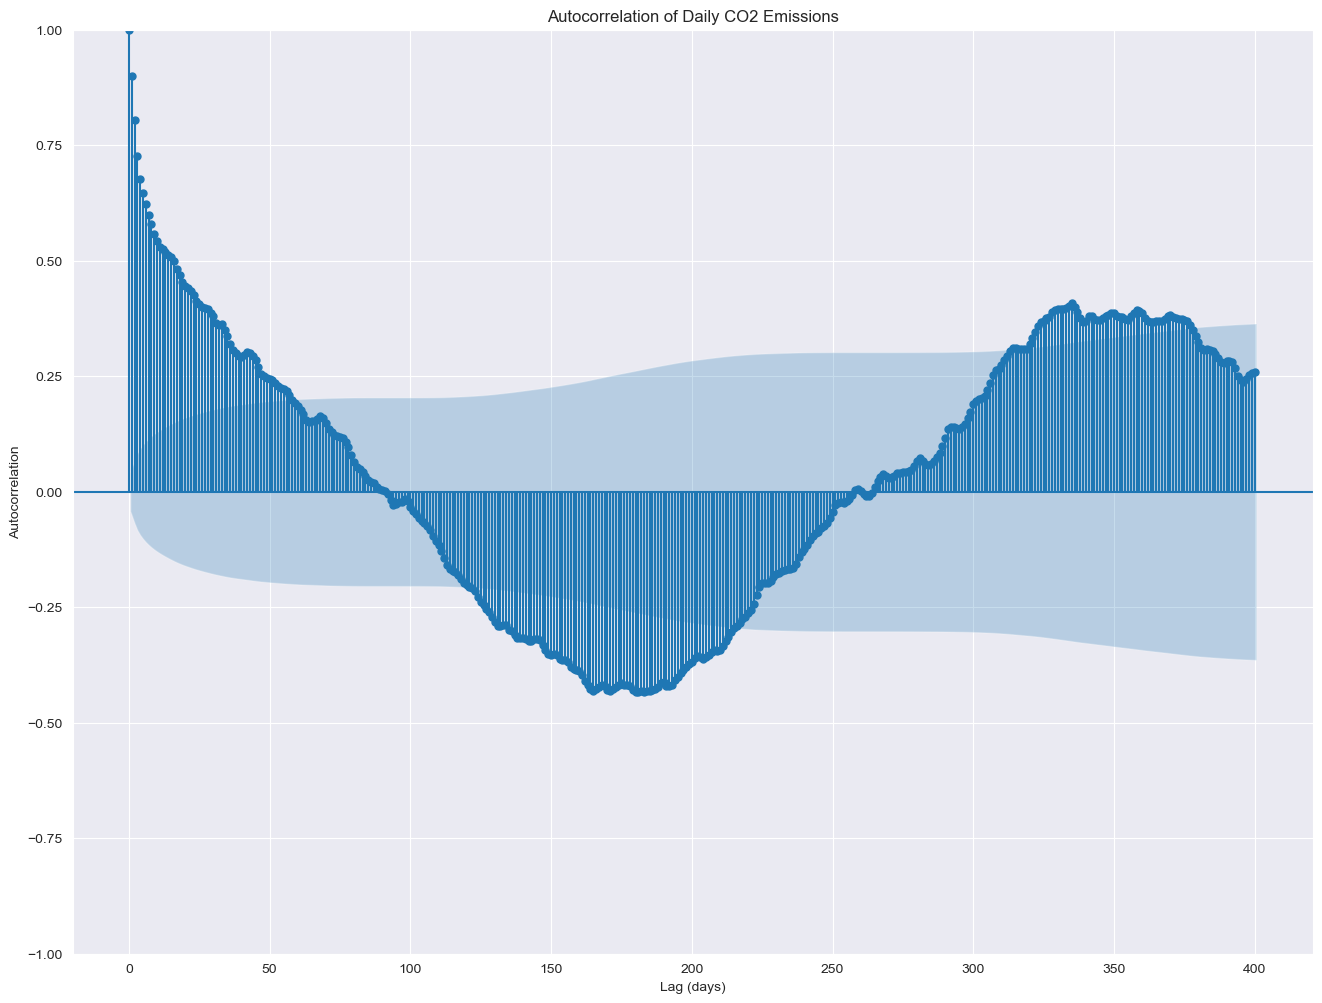

In [ ]:
# Look at daily emissions of a specific unit first

df_unit = campd_tx_all_hours[(campd_tx_all_hours["Facility ID"] == 3460) & (campd_tx_all_hours["Unit ID"] == "CBY1")]

df_daily = (
    df_unit
    .set_index('datetime')
    .sort_index()
    ['CO2 Mass (short tons)']
    .resample('D')
    .sum()
)

# Plot acf for 400 days
plot_acf(df_daily, lags=400)
plt.title("Autocorrelation of Daily CO2 Emissions")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.grid(True)
plt.show()


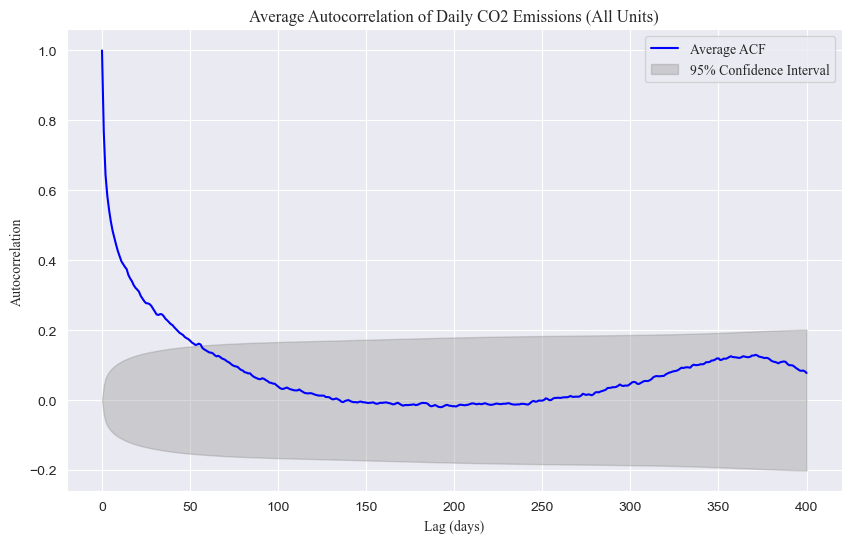

In [ ]:
# Compute the average acf values and confidence intervals across all units

# Filter for units that emit NOx
sample_units = campd_tx_all_hours[campd_tx_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily CO2 Emissions (All Units)", fontname="Times New Roman")
plt.xlabel("Lag (days)", fontname="Times New Roman")
plt.ylabel("Autocorrelation", fontname="Times New Roman")
plt.legend(prop={"family": "Times New Roman"})
plt.grid(True)
plt.show()

In [54]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags 300–400
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

Units with significant ACF values at lag 365: [(3441, '8'), (3441, '9'), (3443, '9'), (3452, '2'), (3453, '6'), (3453, '7'), (3453, '8'), (3460, 'CBY1'), (3460, 'CBY2'), (3470, 'WAP2'), (3476, '5'), (3478, '3'), (3482, '153T'), (3482, '154T'), (3491, '3'), (3491, '4'), (3491, '5'), (3504, '1'), (3601, '1'), (3601, '2'), (3611, '1'), (3612, '1'), (3612, '3'), (3612, 'CGT5'), (3628, '2'), (4937, 'CT-2'), (4939, '1'), (4939, '3'), (4939, '4'), (6183, 'SM-1'), (6194, '171B'), (6243, '1'), (7900, 'SH4'), (50109, 'HRSG1'), (50109, 'HRSG2'), (54817, 'EAST'), (55062, '1'), (55062, '2'), (55062, '3'), (55086, '101'), (55086, '102'), (55091, 'STK2'), (55091, 'STK3'), (55091, 'STK4'), (55091, 'STK5'), (55132, 'OGTDB1'), (55132, 'OGTDB2'), (55132, 'OGTDB3'), (55137, 'CTG-1'), (55137, 'CTG-2'), (55137, 'CTG-3'), (55139, 'CTG1'), (55139, 'CTG2'), (55144, 'STK1'), (55144, 'STK2'), (55144, 'STK3'), (55154, '1'), (55154, '2'), (55172, 'GT-3'), (55176, '1'), (55230, 'CT-1'), (55230, 'CT-2'), (55230, 'CT

In [55]:
print("Of a total ", campd_tx_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units in TX, ", len(significant_units), " have a significant seasonality")

Of a total  390  units in TX,  87  have a significant seasonality


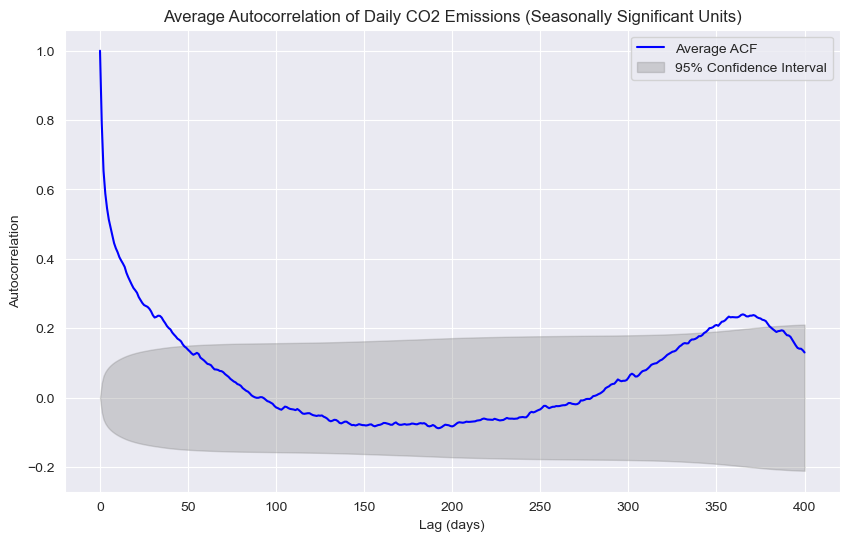

In [57]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_tx_all_hours[campd_tx_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily CO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

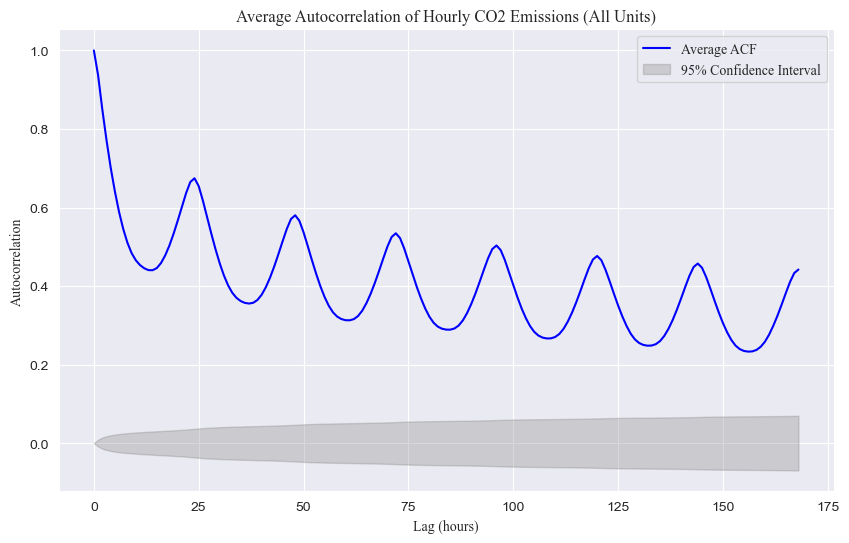

In [ ]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_tx_all_hours[campd_tx_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='CO2 Mass (short tons)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Hourly CO2 Emissions (All Units)", fontname="Times New Roman")
plt.xlabel("Lag (hours)", fontname="Times New Roman")
plt.ylabel("Autocorrelation", fontname="Times New Roman")
plt.legend(prop={"family": "Times New Roman"})
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>NOx</h6>

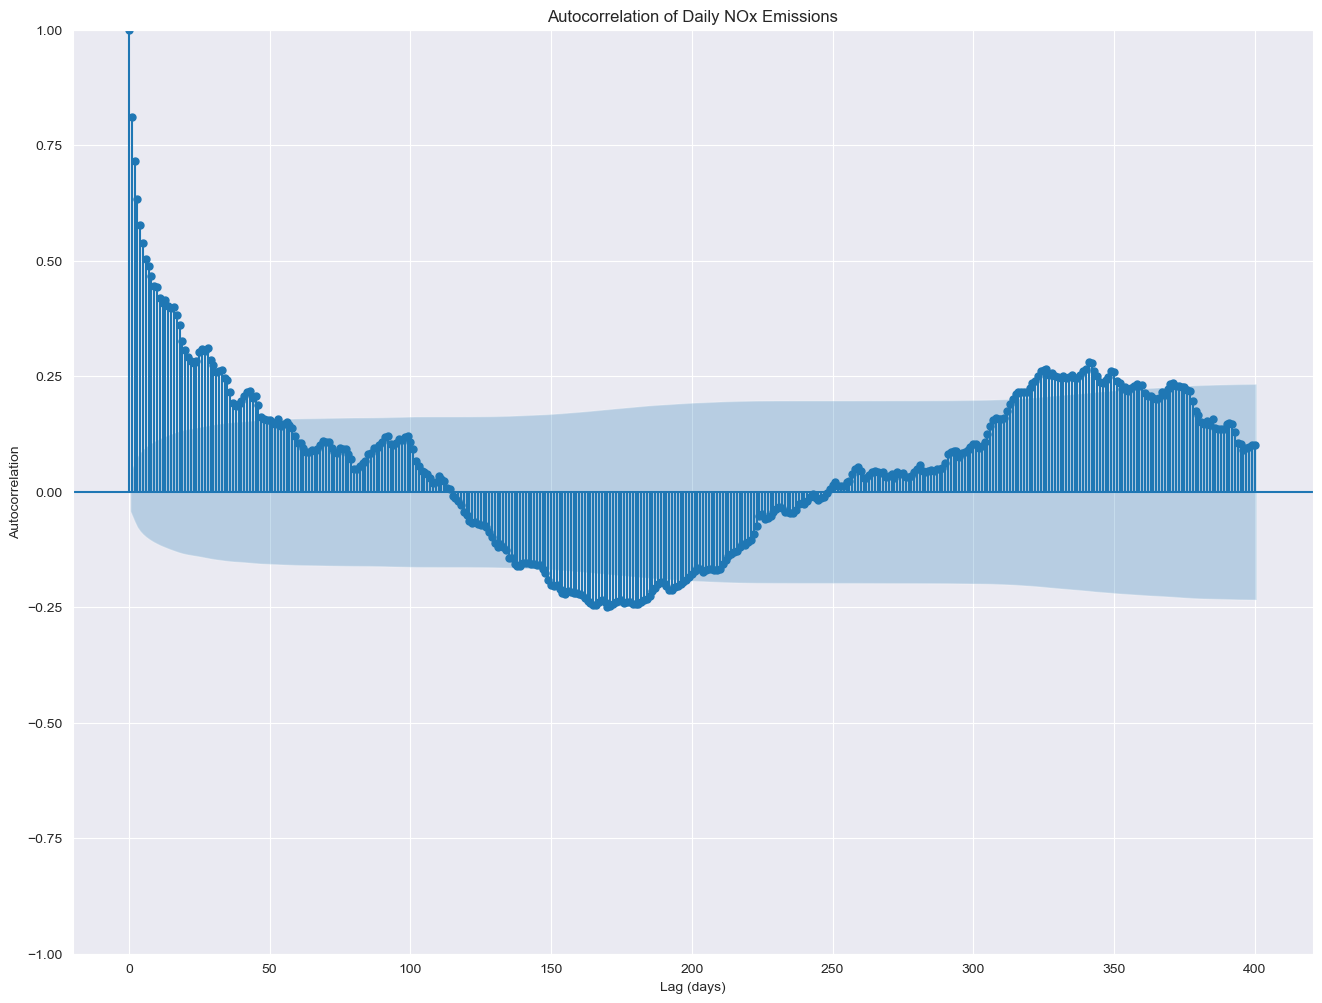

In [52]:
# look at daily emissions of a specific unit first

df_unit = campd_tx_all_hours[(campd_tx_all_hours["Facility ID"] == 3460) & (campd_tx_all_hours["Unit ID"] == "CBY1")]

df_daily = (
    df_unit
    .set_index('datetime')
    .sort_index()
    ['NOx Mass (lbs)']
    .resample('D')
    .sum()
)

# Plot acf for 400 days
plot_acf(df_daily, lags=400)
plt.title("Autocorrelation of Daily NOx Emissions")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.grid(True)
plt.show()


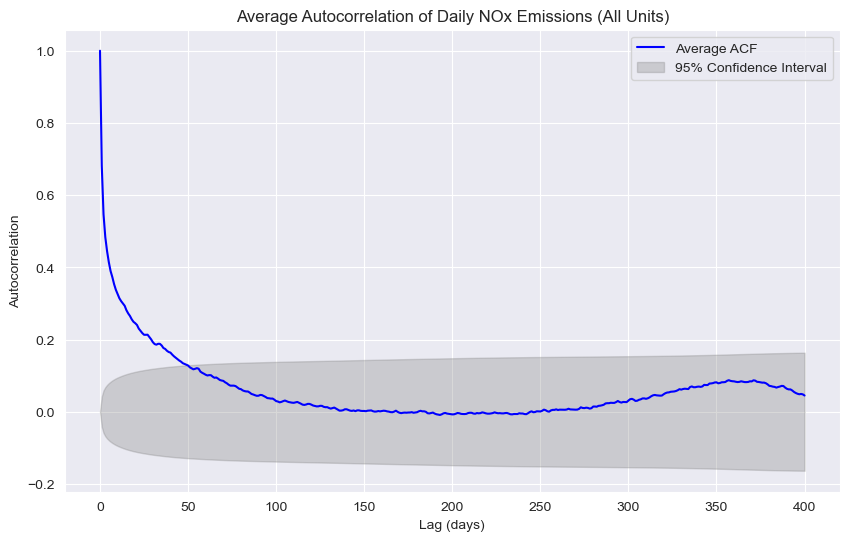

In [29]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit NOx
sample_units = campd_tx_all_hours[campd_tx_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily NOx Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

In [40]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags 300–400
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

Units with significant ACF values at lag 365: [(3441, '8'), (3443, '9'), (3453, '6'), (3453, '7'), (3453, '8'), (3460, 'CBY2'), (3470, 'WAP2'), (3478, '3'), (3482, '153T'), (3482, '154T'), (3491, '3'), (3491, '4'), (3491, '5'), (3576, 'BW2'), (3601, '1'), (3601, '2'), (3628, '2'), (4195, '2'), (4266, '5'), (4939, '1'), (4939, '3'), (4939, '4'), (6183, 'SM-1'), (6194, '171B'), (6194, '172B'), (6243, '1'), (7030, 'U2'), (50109, 'HRSG1'), (50109, 'HRSG2'), (55062, '1'), (55062, '2'), (55062, '3'), (55086, '101'), (55086, '102'), (55091, 'STK1'), (55091, 'STK2'), (55091, 'STK3'), (55091, 'STK4'), (55091, 'STK5'), (55132, 'OGTDB1'), (55132, 'OGTDB2'), (55132, 'OGTDB3'), (55137, 'CTG-2'), (55139, 'CTG1'), (55139, 'CTG2'), (55176, '1'), (55230, 'CT-1'), (55230, 'CT-2'), (55230, 'CT-4'), (55664, 'GT-1'), (55664, 'GT-2'), (55708, 'BFB-1'), (56611, 'S01'), (56806, 'CBY41'), (58001, 'CTG3'), (58001, 'CTG4'), (58005, 'CTG1'), (58005, 'CTG2'), (58562, 'GT-2'), (59812, 'CGT5')]


In [39]:
print("Of a total ", campd_tx_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units in TX, ", len(significant_units), " have a significant seasonality")

Of a total  390  units in TX,  60  have a significant seasonality


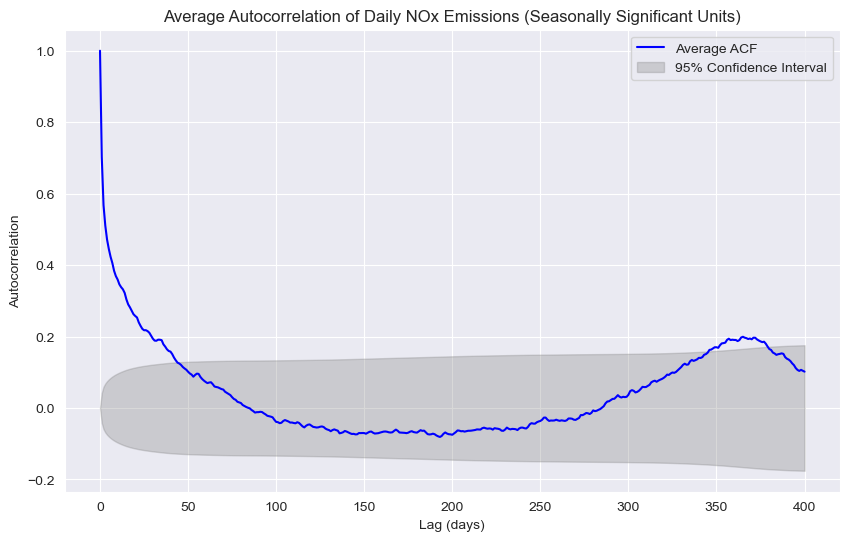

In [ ]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_tx_all_hours[campd_tx_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily NOx Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

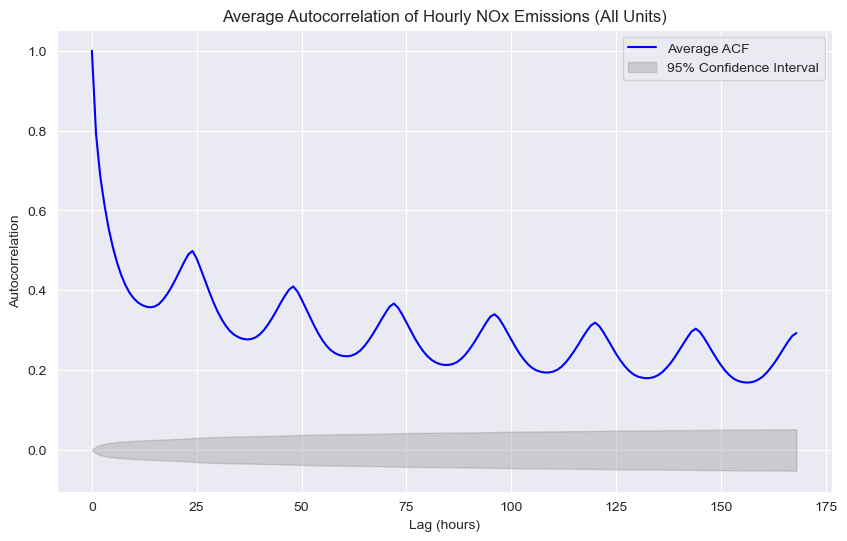

In [ ]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_tx_all_hours[campd_tx_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='NOx Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Hourly NOx Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>SO2</h6>

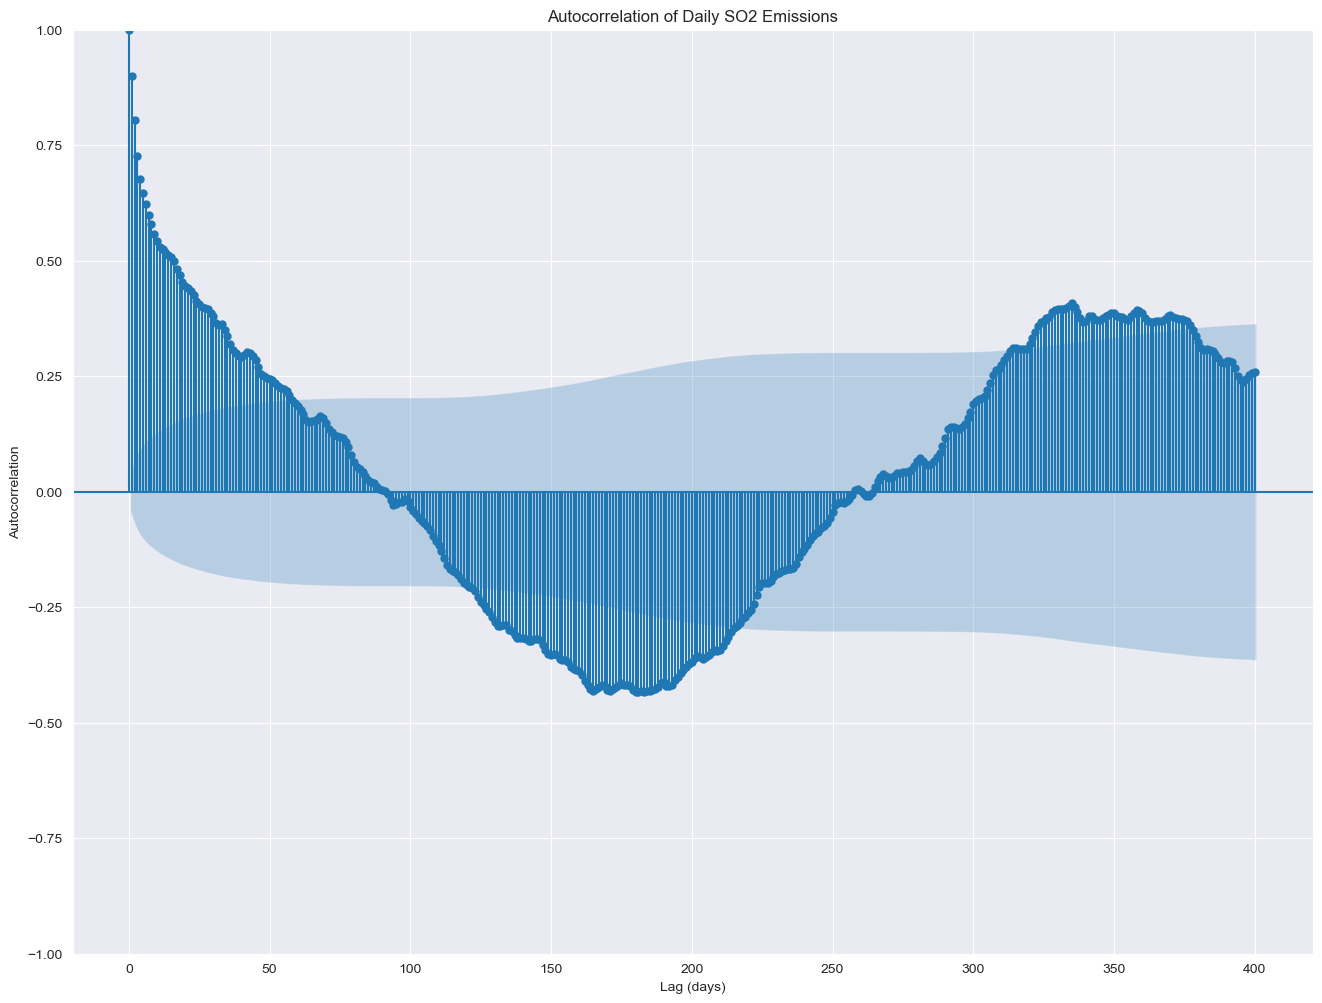

In [59]:
# look at daily emissions of a specific unit first

df_unit = campd_tx_all_hours[(campd_tx_all_hours["Facility ID"] == 3460) & (campd_tx_all_hours["Unit ID"] == "CBY1")]

df_daily = (
    df_unit
    .set_index('datetime')
    .sort_index()
    ['SO2 Mass (lbs)']
    .resample('D')
    .sum()
)

# Plot acf for 400 days
plot_acf(df_daily, lags=400)
plt.title("Autocorrelation of Daily SO2 Emissions")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.grid(True)
plt.show()


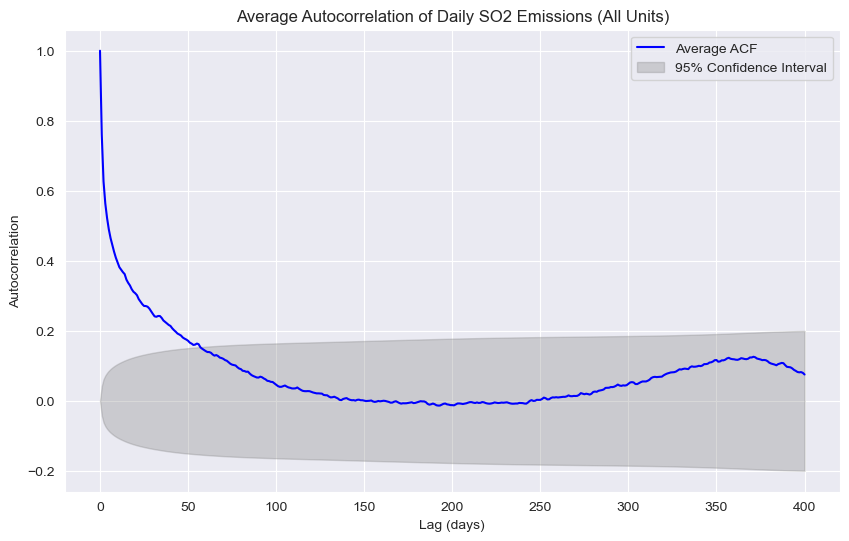

In [ ]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit
sample_units = campd_tx_all_hours[campd_tx_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily SO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

In [61]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags 300–400
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

Units with significant ACF values at lag 365: [(3441, '8'), (3441, '9'), (3443, '9'), (3453, '6'), (3453, '7'), (3453, '8'), (3460, 'CBY1'), (3460, 'CBY2'), (3470, 'WAP2'), (3478, '3'), (3482, '153T'), (3482, '154T'), (3491, '3'), (3491, '4'), (3491, '5'), (3504, '1'), (3601, '1'), (3601, '2'), (3611, '1'), (3612, '1'), (3612, '3'), (3612, 'CGT5'), (3612, 'CGT8'), (4937, 'CT-2'), (4939, '1'), (4939, '3'), (4939, '4'), (6183, 'SM-1'), (6194, '171B'), (6243, '1'), (7900, 'SH4'), (50109, 'HRSG1'), (50109, 'HRSG2'), (55062, '1'), (55062, '2'), (55062, '3'), (55086, '101'), (55086, '102'), (55091, 'STK2'), (55091, 'STK3'), (55091, 'STK4'), (55091, 'STK5'), (55132, 'OGTDB1'), (55132, 'OGTDB2'), (55132, 'OGTDB3'), (55137, 'CTG-1'), (55137, 'CTG-2'), (55137, 'CTG-3'), (55139, 'CTG1'), (55139, 'CTG2'), (55144, 'STK1'), (55144, 'STK2'), (55144, 'STK3'), (55154, '1'), (55154, '2'), (55172, 'GT-3'), (55176, '1'), (55230, 'CT-1'), (55230, 'CT-2'), (55230, 'CT-3'), (55230, 'CT-4'), (55320, 'GT-1'), 

In [62]:
print("Of a total ", campd_tx_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units in TX, ", len(significant_units), " have a significant seasonality")

Of a total  390  units in TX,  83  have a significant seasonality


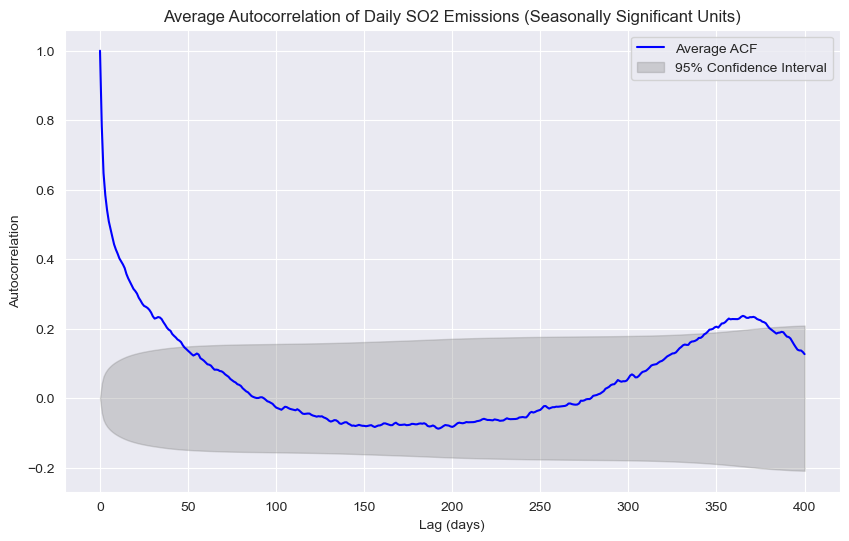

In [63]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_tx_all_hours[campd_tx_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily SO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

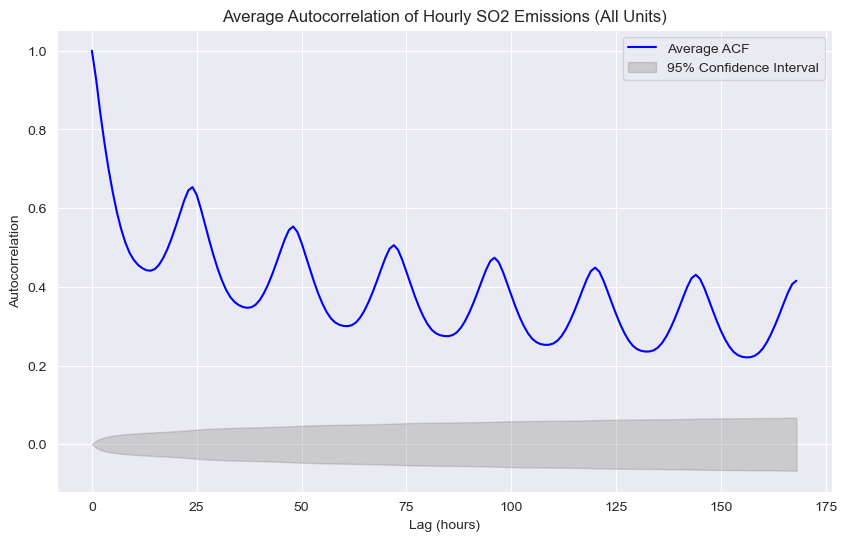

In [64]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_tx_all_hours[campd_tx_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_tx_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='SO2 Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Hourly SO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h5>New York</h5>

<h6>CO2</h6>

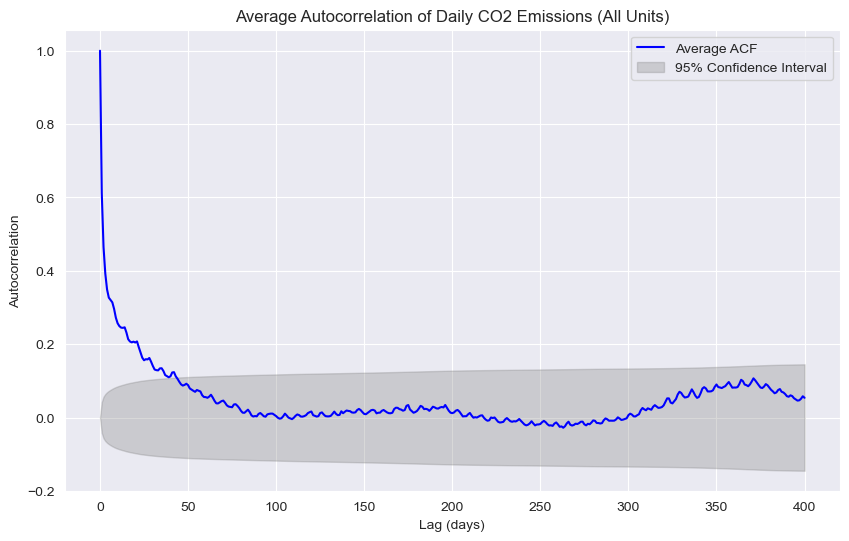

In [76]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit
sample_units = campd_ny_all_hours[campd_ny_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily CO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

In [87]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags 300–400
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

Units with significant ACF values at lag 365: [(2480, '1'), (2490, '20'), (2490, '30'), (2493, '1'), (2493, '2'), (2493, '70'), (2500, 'UCC001'), (2504, '120'), (2504, '121'), (2504, '122'), (2511, '20'), (2511, 'U00014'), (2511, 'U00015'), (2511, 'U00016'), (2511, 'U00017'), (2511, 'U00018'), (2511, 'U00019'), (2514, 'U00020'), (2514, 'U00021'), (2516, '1'), (2516, '2'), (2516, '3'), (2516, '4'), (2517, '3'), (2517, 'UGT002'), (2517, 'UGT003'), (2521, 'UGT001'), (2527, '6'), (2535, '1'), (2539, '10001'), (2539, '10002'), (2539, '10003'), (2625, '2'), (2682, '20'), (6082, '1'), (7146, 'UGT007'), (7146, 'UGT008'), (7146, 'UGT009'), (7146, 'UGT013'), (7869, 'UGT012'), (7869, 'UGT013'), (7909, 'VB01'), (7909, 'VB02'), (7910, '2301'), (7910, '2302'), (7912, 'BW01'), (7913, 'HG01'), (7913, 'HG02'), (7914, 'HR01'), (7914, 'HR02'), (7915, 'NO1'), (8006, '1'), (8006, '2'), (8007, 'U00011'), (8007, 'U00012'), (8053, 'PT01'), (10190, '1'), (10464, 'E0001'), (10464, 'E0002'), (10464, 'E0003'), (1

In [79]:
print("Of a total ", campd_ny_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Of a total  197  units,  63  have a significant seasonality


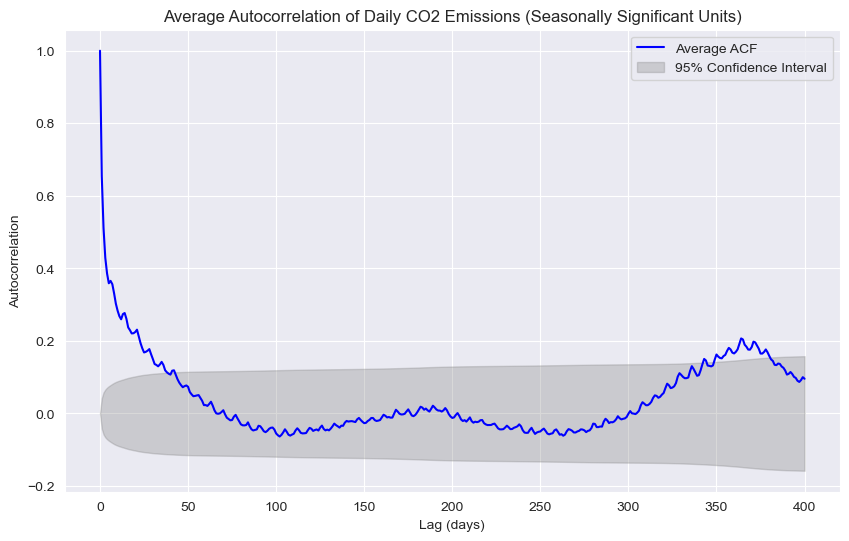

In [84]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_ny_all_hours[campd_ny_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily CO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

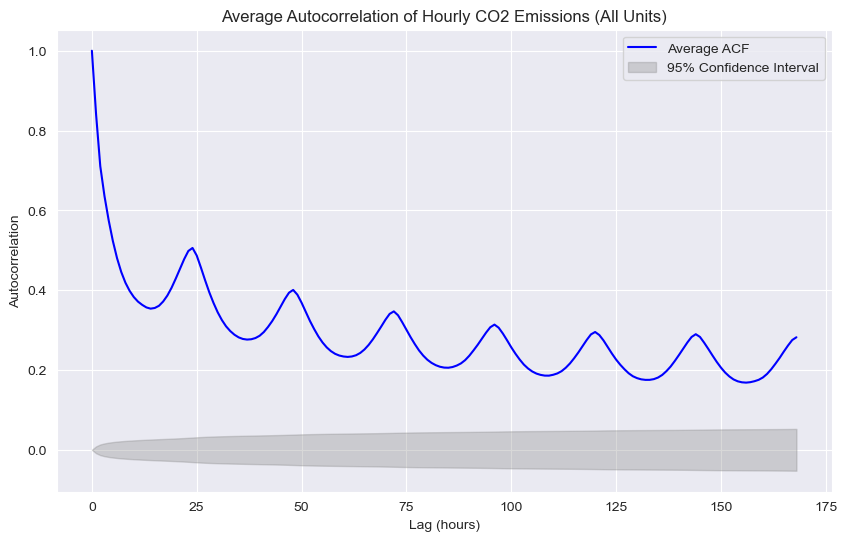

In [85]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_ny_all_hours[campd_ny_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='CO2 Mass (short tons)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Hourly CO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>NOx</h6>

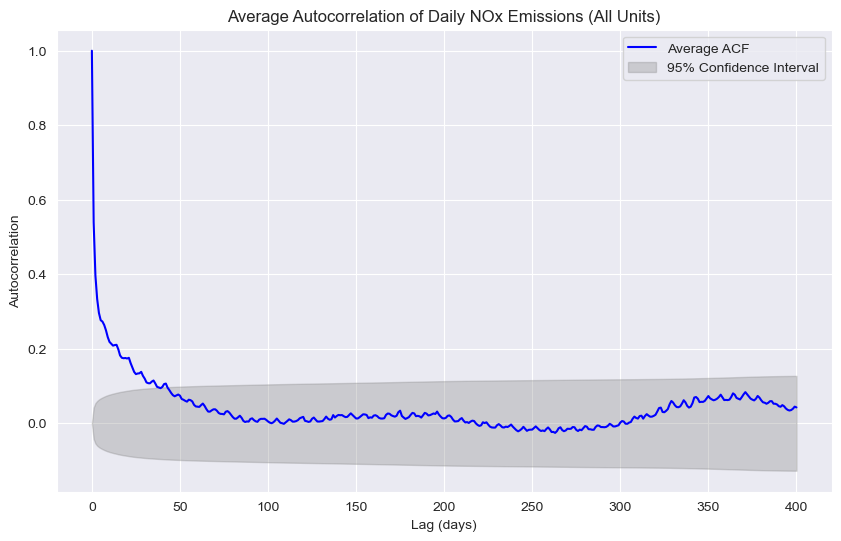

In [69]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit NOx
sample_units = campd_ny_all_hours[campd_ny_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily NOx Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

In [80]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags 300–400
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

Units with significant ACF values at lag 365: [(2493, '1'), (2493, '2'), (2493, '60'), (2500, '10'), (2500, '20'), (2504, '121'), (2511, 'U00016'), (2511, 'U00017'), (2511, 'U00018'), (2511, 'U00019'), (2517, '4'), (2517, 'UGT002'), (2517, 'UGT003'), (2539, '10001'), (2539, '10002'), (2539, '10003'), (2682, '10'), (6082, '1'), (7146, 'UGT007'), (7869, 'UGT012'), (7869, 'UGT013'), (7909, 'VB01'), (7909, 'VB02'), (7910, '2302'), (7912, 'BW01'), (7913, 'HG01'), (7913, 'HG02'), (7914, 'HR01'), (7914, 'HR02'), (7915, 'NO1'), (8007, 'U00011'), (8007, 'U00012'), (8007, 'U00013'), (8007, 'U00014'), (8007, 'U00015'), (8007, 'U00016'), (8007, 'U00017'), (8007, 'U00018'), (8007, 'U00019'), (8007, 'U00020'), (8053, 'PT01'), (10619, '1'), (10620, '1'), (50449, '1'), (50450, '1'), (50451, '1'), (50978, 'A'), (54149, '1'), (54547, '2'), (54547, '3'), (54547, '4'), (54574, '1'), (55375, 'CT3'), (55375, 'CT4'), (55405, '2'), (55699, '1'), (55699, '2'), (55786, 'CT01'), (55786, 'CT02'), (55969, 'U-01'),

In [81]:
print("Of a total ", campd_ny_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Of a total  197  units,  63  have a significant seasonality


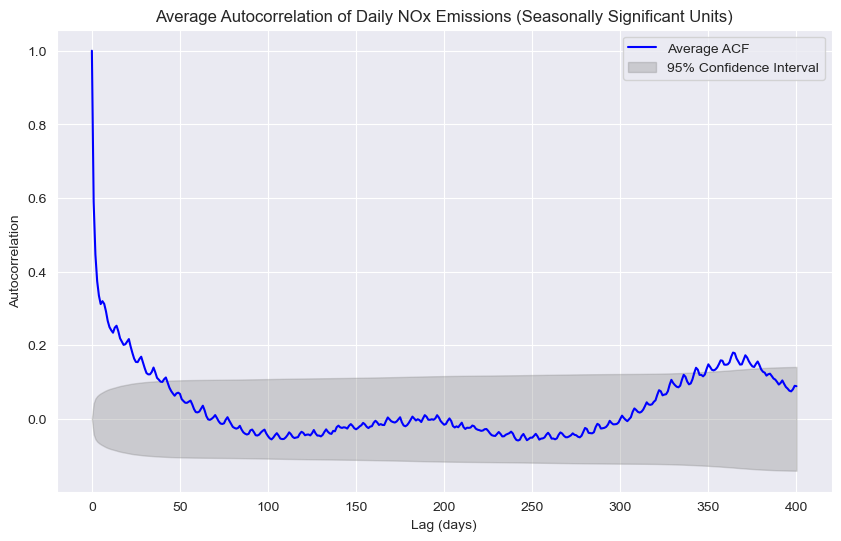

In [73]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_ny_all_hours[campd_ny_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily NOx Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

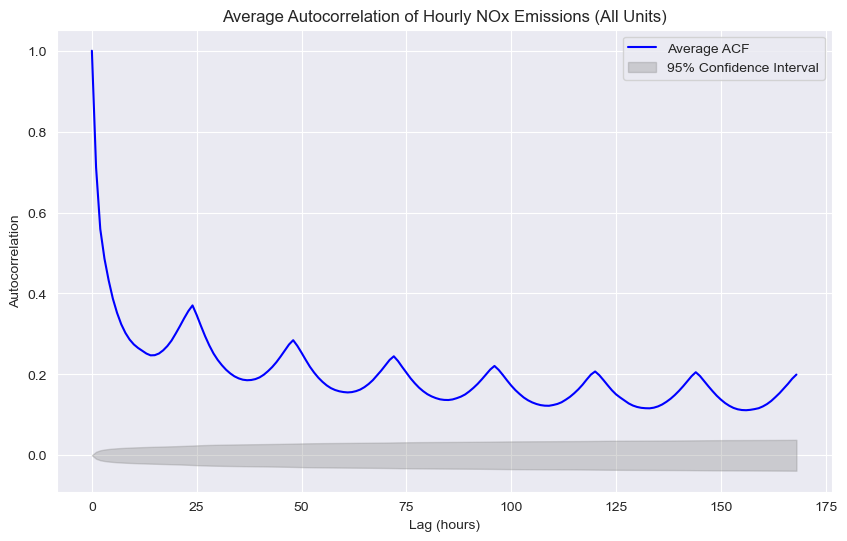

In [68]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_ny_all_hours[campd_ny_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='NOx Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Hourly NOx Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>SO2</h6>

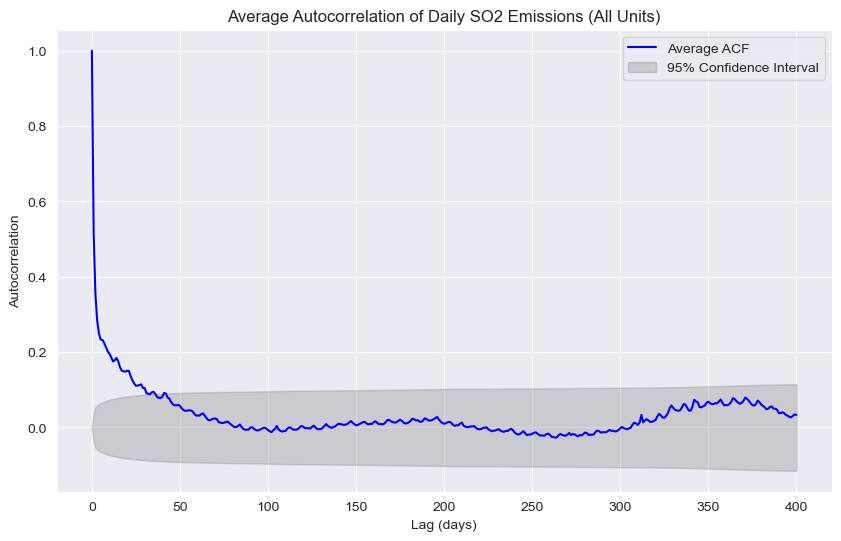

In [88]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit NOx
sample_units = campd_ny_all_hours[campd_ny_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily SO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

In [89]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags 300–400
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

Units with significant ACF values at lag 365: [(2493, '1'), (2493, '2'), (2511, 'U00016'), (2511, 'U00017'), (2511, 'U00018'), (2511, 'U00019'), (2516, '4'), (2517, 'UGT002'), (2517, 'UGT003'), (2539, '10001'), (2539, '10002'), (2539, '10003'), (2682, '10'), (6082, '1'), (7146, 'UGT007'), (7869, 'UGT012'), (7869, 'UGT013'), (7909, 'VB01'), (7909, 'VB02'), (7910, '2302'), (7912, 'BW01'), (7913, 'HG01'), (7913, 'HG02'), (7914, 'HR01'), (7914, 'HR02'), (7915, 'NO1'), (8007, 'U00003'), (8007, 'U00004'), (8007, 'U00011'), (8007, 'U00012'), (8007, 'U00013'), (8007, 'U00014'), (8007, 'U00015'), (8007, 'U00016'), (8007, 'U00017'), (8007, 'U00018'), (8007, 'U00019'), (8007, 'U00020'), (8053, 'PT01'), (10619, '1'), (10620, '1'), (50449, '1'), (50450, '1'), (50451, '1'), (50978, 'A'), (54149, '1'), (54547, '2'), (54547, '3'), (54547, '4'), (54574, '1'), (55375, 'CT4'), (55405, '2'), (55699, '1'), (55699, '2'), (55786, 'CT01'), (55786, 'CT02'), (55969, 'U-01'), (56032, '0001'), (56196, 'CTG7A'), (

In [90]:
print("Of a total ", campd_ny_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Of a total  197  units,  60  have a significant seasonality


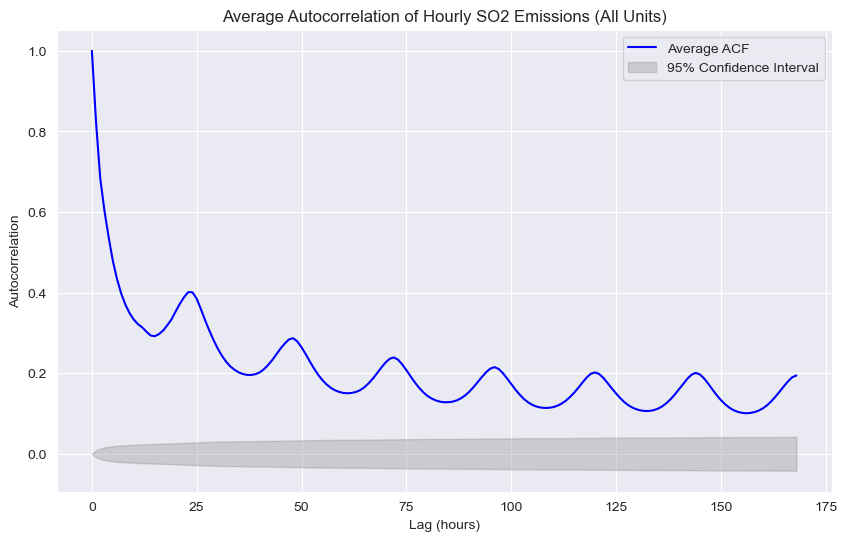

In [86]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_ny_all_hours[campd_ny_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_ny_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='SO2 Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Hourly SO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h5>Wyoming</h5>

<h6>CO2</h6>

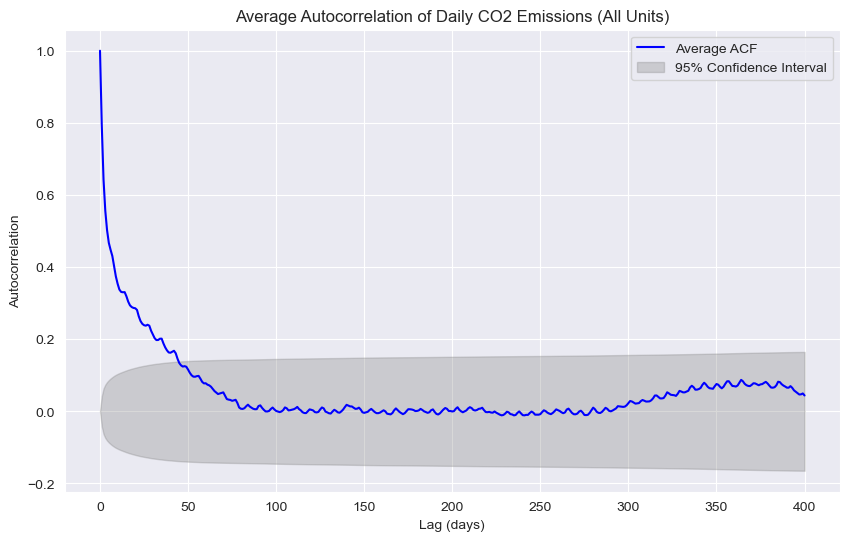

In [91]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit
sample_units = campd_wy_all_hours[campd_wy_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily CO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

In [92]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags 300–400
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

Units with significant ACF values at lag 365: [(4162, '1'), (55477, 'CT2')]


In [94]:
print("Of a total ", campd_wy_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Of a total  25  units,  2  have a significant seasonality


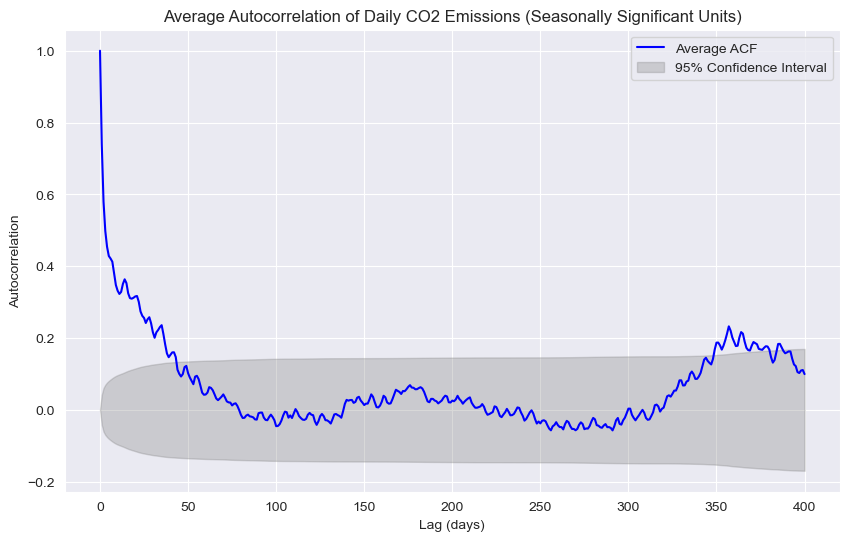

In [95]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_wy_all_hours[campd_wy_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['CO2 Mass (short tons)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'CO2 Mass (short tons)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily CO2 Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

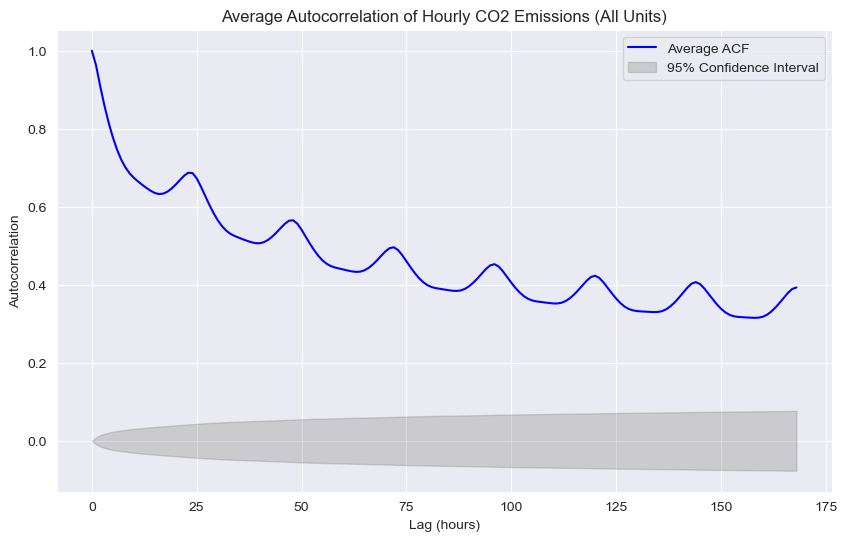

In [96]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_wy_all_hours[campd_wy_all_hours["CO2 Mass (short tons)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='CO2 Mass (short tons)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Hourly CO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>NOx</h6>

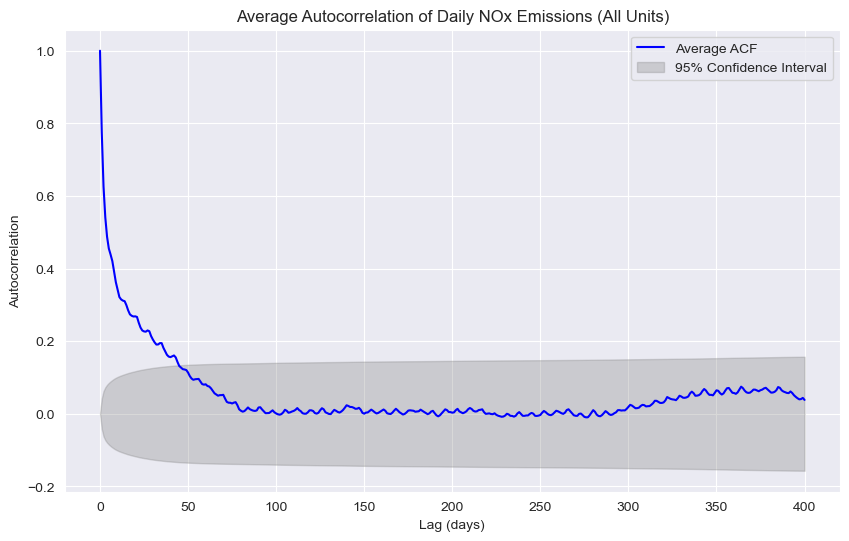

In [97]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit NOx
sample_units = campd_wy_all_hours[campd_wy_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily NOx Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

In [98]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags 300–400
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

Units with significant ACF values at lag 365: [(55477, 'CT2')]


In [99]:
print("Of a total ", campd_wy_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Of a total  25  units,  1  have a significant seasonality


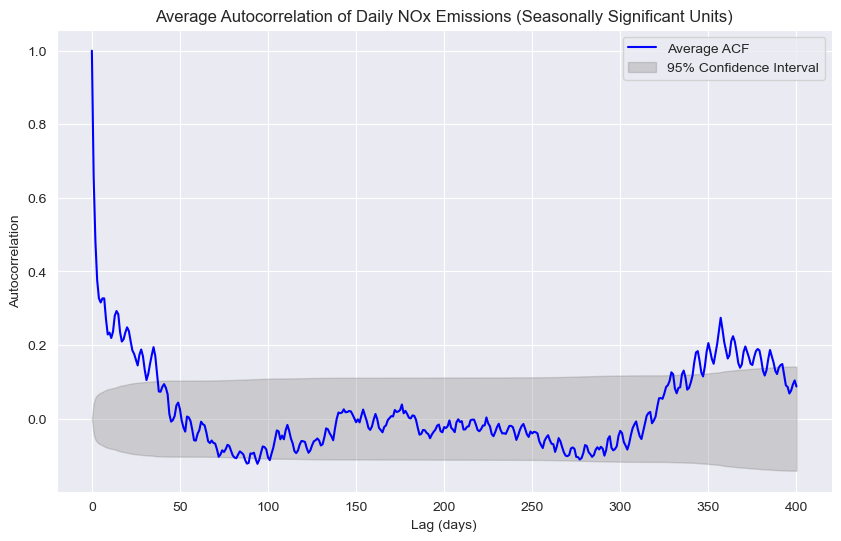

In [100]:
# Calculate average values for units with significant acf at lag 365

# Filter the for the significant units
sampled_data = campd_wy_all_hours[campd_wy_all_hours.set_index(["Facility ID", "Unit ID"]).index.isin(significant_units)]

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['NOx Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'NOx Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily NOx Emissions (Seasonally Significant Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

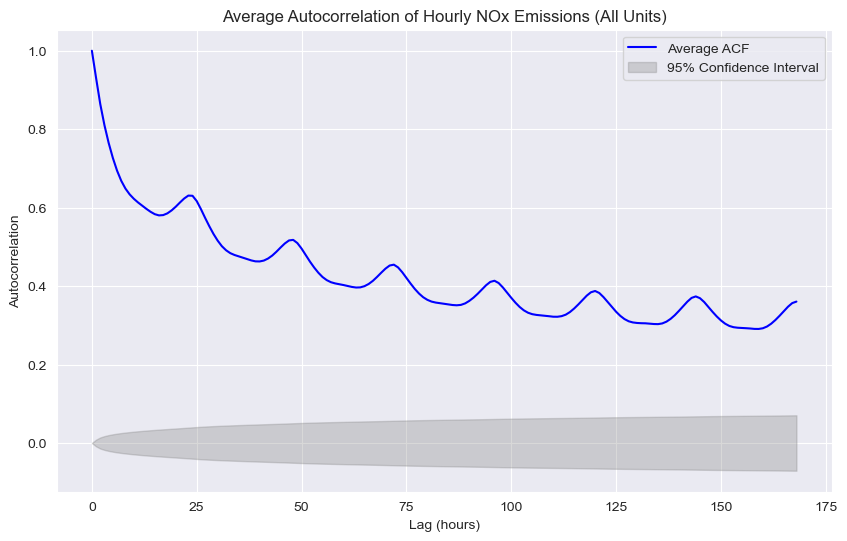

In [102]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_wy_all_hours[campd_wy_all_hours["NOx Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='NOx Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Hourly NOx Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

<h6>SO2</h6>

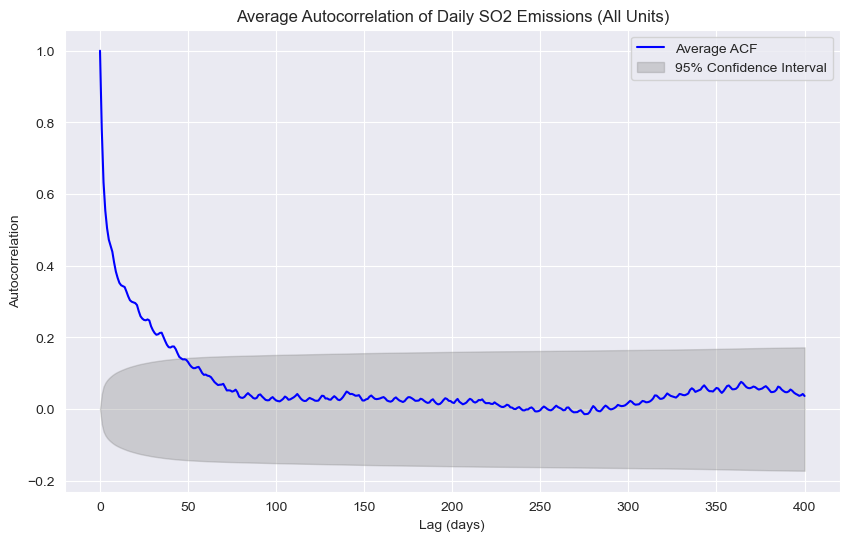

In [103]:
# compute the average acf values and confidence intervals across all units

# Filter for units that emit NOx
sample_units = campd_wy_all_hours[campd_wy_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Get daily summed emissions 
daily_emissions = (
    sampled_data
    .groupby(['Facility ID', 'Unit ID', sampled_data['datetime'].dt.date])['SO2 Mass (lbs)']
    .sum()
    .reset_index()
    .rename(columns={'datetime': 'Daily Date', 'SO2 Mass (lbs)': 'Daily Emissions'})
)

# Pivot the so each unit has its own column of daily emissions
pivoted_data = daily_emissions.pivot(index='Daily Date', columns=['Facility ID', 'Unit ID'], values='Daily Emissions')

# Get acf values and confidence intervals for all units up to 400 lags with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Daily SO2 Emissions (All Units)")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

In [104]:
# Get units with significant ACF values at the 1-year mark
significant_units = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=400, alpha=0.05)
    
    # Extract the ACF values and confidence intervals for lags 300–400
    acf_365 = acf_values[365]
    conf_lower = confint[365, 0] - acf_365 
    conf_upper = confint[365, 1] - acf_365
    
    # Check if ACF values outside the confidence interval
    if np.any((acf_365 < conf_lower) | (acf_365 > conf_upper)):
        significant_units.append(col)

print(f"Units with significant ACF values at lag 365: {significant_units}")

Units with significant ACF values at lag 365: [(55477, 'CT2')]


In [106]:
print("Of a total ", campd_wy_all_hours[["Facility ID", "Unit ID"]].drop_duplicates().shape[0], " units, ", len(significant_units), " have a significant seasonality")

Of a total  25  units,  1  have a significant seasonality


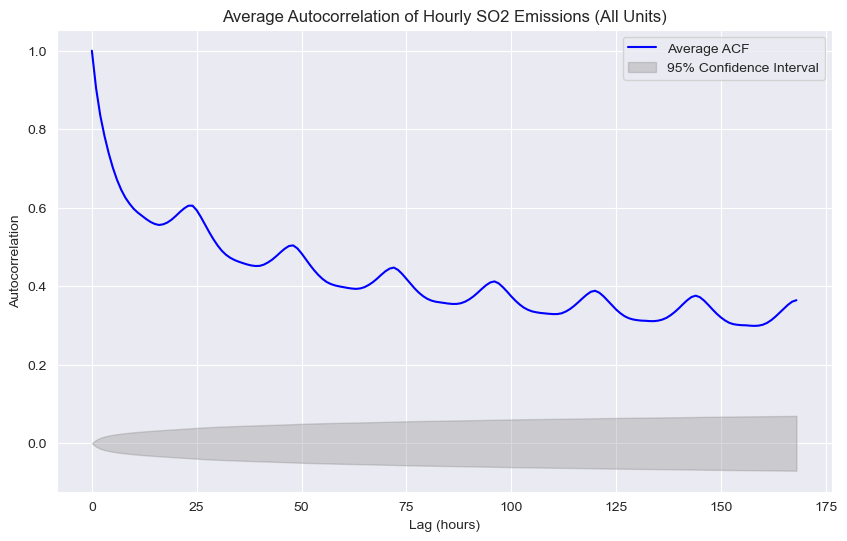

In [107]:
# Calculate average values for units within the first week (hourly lags)

sample_units = campd_wy_all_hours[campd_wy_all_hours["SO2 Mass (lbs)"] > 0][['Facility ID', 'Unit ID']].drop_duplicates()
sampled_data = campd_wy_all_hours.merge(sample_units, on=['Facility ID', 'Unit ID'])

# Pivot the so each unit has its own column of daily emissions
pivoted_data = sampled_data.pivot(index='datetime', columns=['Facility ID', 'Unit ID'], values='SO2 Mass (lbs)')

# Get acf values and confidence intervals for all units up to 24*7 lags (1 week) with confidence intervals at 5 %
acf_values_list = []
confidence_intervals_list = []

for col in pivoted_data.columns:
    acf_values, confint = acf(pivoted_data[col], nlags=24*7, alpha=0.05)
    acf_values_list.append(acf_values)
    confidence_intervals_list.append(confint)

# Calc average autocorrelation and confidence intervals
average_acf = np.mean(acf_values_list, axis=0)
lower_conf = np.mean([conf[:, 0] - average_acf for conf in confidence_intervals_list], axis=0) # conf int is centered around acf values per default, have to adjust them to center around x-axis
upper_conf = np.mean([conf[:, 1] - average_acf for conf in confidence_intervals_list], axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(average_acf)), average_acf, linestyle='-', color='b', label='Average ACF')
plt.fill_between(range(len(average_acf)), lower_conf, upper_conf, color='gray', alpha=0.3, label='95% Confidence Interval')
plt.title("Average Autocorrelation of Hourly SO2 Emissions (All Units)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

# shows clear 24 hour peaks

clear 24 hour peaks

<h4>Since 1996 (using daily data)</h4>

In [ ]:
# Convert to datetime format
campd_daily_ny['Date'] = pd.to_datetime(campd_daily_ny['Date'])
campd_daily_tx['Date'] = pd.to_datetime(campd_daily_tx['Date'])
campd_daily_wy['Date'] = pd.to_datetime(campd_daily_wy['Date'])

# Set Date as index for resampling
campd_daily_ny.set_index('Date', inplace=True)
campd_daily_tx.set_index('Date', inplace=True)
campd_daily_wy.set_index('Date', inplace=True)

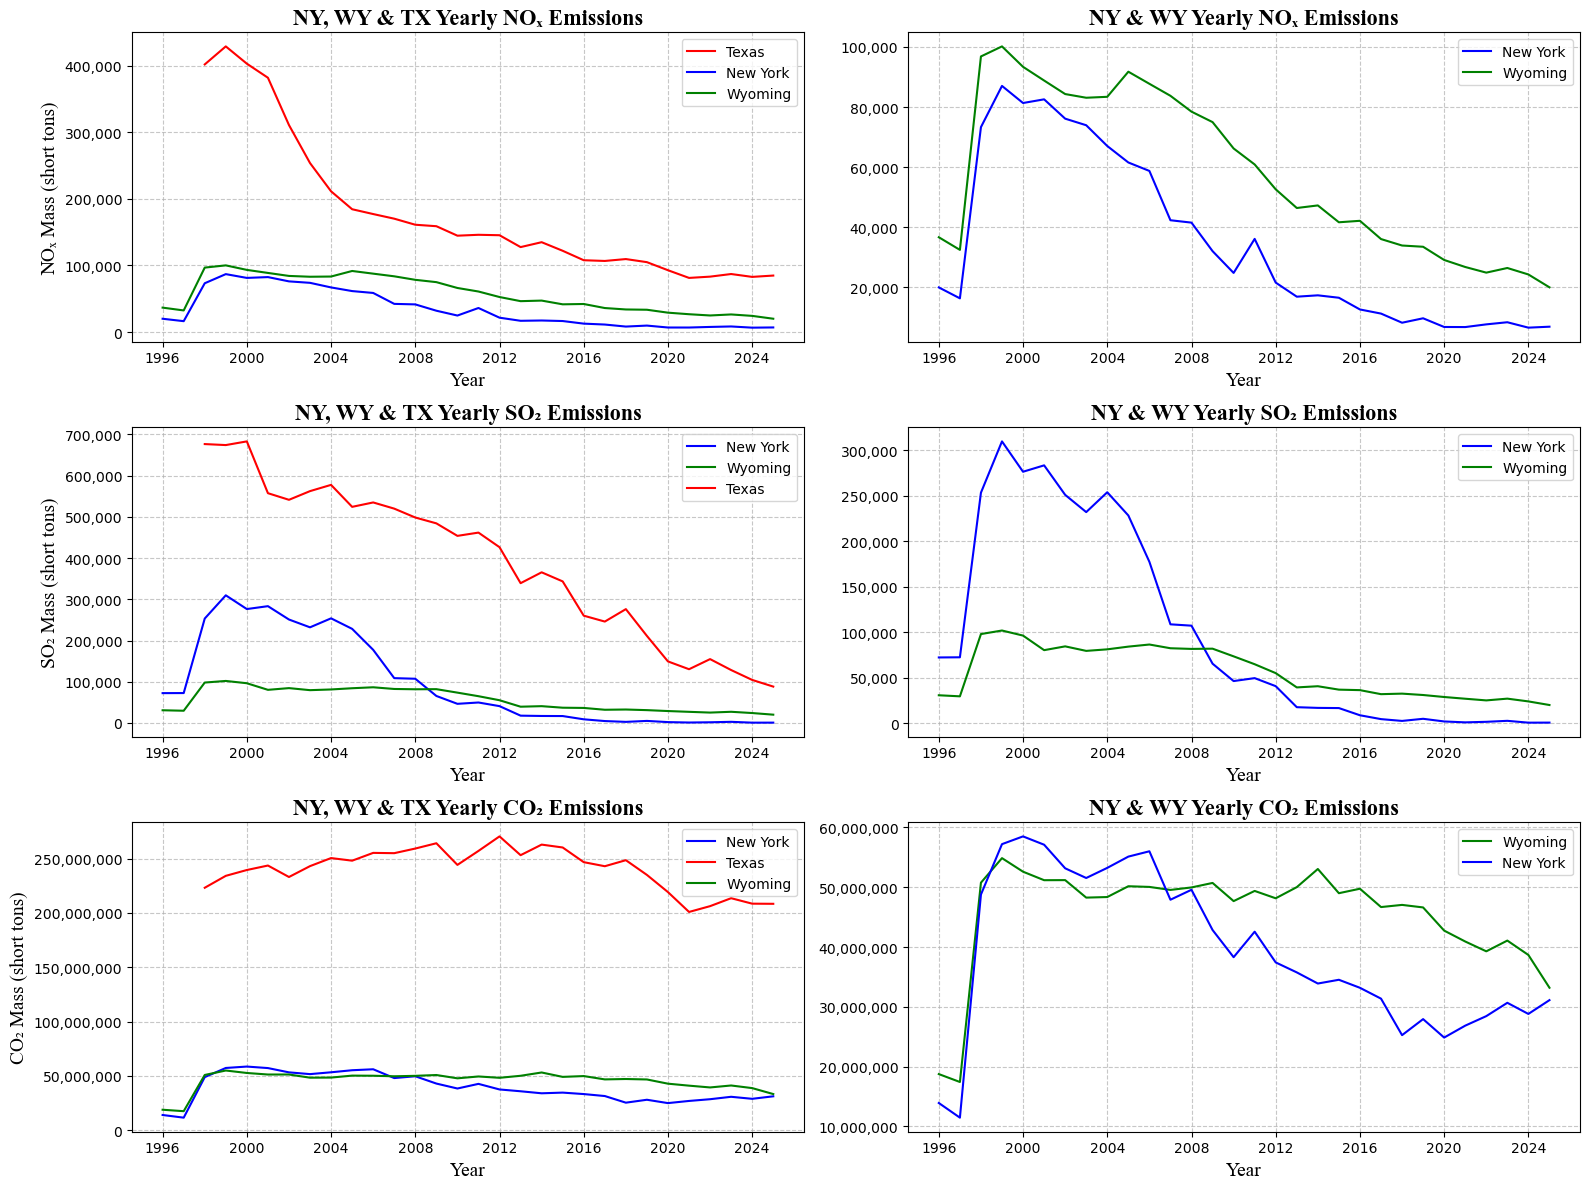

In [ ]:
# Chart for all emissions

# Resample to yearly NOx emissions (sum)
emissions_by_year_ny_nox = campd_daily_ny["NOx Mass (short tons)"].resample('YE').sum()
emissions_by_year_tx_nox = campd_daily_tx["NOx Mass (short tons)"].resample('YE').sum()
emissions_by_year_wy_nox = campd_daily_wy["NOx Mass (short tons)"].resample('YE').sum()

# Resample to yearly SO2 emissions (sum)
emissions_by_year_ny_so2 = campd_daily_ny["SO2 Mass (short tons)"].resample('YE').sum()
emissions_by_year_tx_so2 = campd_daily_tx["SO2 Mass (short tons)"].resample('YE').sum()
emissions_by_year_wy_so2 = campd_daily_wy["SO2 Mass (short tons)"].resample('YE').sum()

# Resample to yearly CO2 emissions (sum)
emissions_by_year_ny_co2 = campd_daily_ny["CO2 Mass (short tons)"].resample('YE').sum()
emissions_by_year_tx_co2 = campd_daily_tx["CO2 Mass (short tons)"].resample('YE').sum()
emissions_by_year_wy_co2 = campd_daily_wy["CO2 Mass (short tons)"].resample('YE').sum()

# Function to format y-axis numbers with commas
def format_with_commas(x, pos):
    return f"{x:,.0f}"

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

# NOx
axes[0, 0].plot(emissions_by_year_tx_nox.index, emissions_by_year_tx_nox.values, color='r', label='Texas')
axes[0, 0].plot(emissions_by_year_ny_nox.index, emissions_by_year_ny_nox.values, color='b', label='New York')
axes[0, 0].plot(emissions_by_year_wy_nox.index, emissions_by_year_wy_nox.values, color='g', label='Wyoming')
axes[0, 0].set_title('NY, WY & TX Yearly NOₓ Emissions', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[0, 0].set_xlabel('Year', fontsize=14, fontname="Times New Roman")
axes[0, 0].set_ylabel('NOₓ Mass (short tons)', fontsize=14, fontname="Times New Roman")
axes[0, 0].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[0, 0].grid(True, linestyle="--", alpha=0.7)
axes[0, 0].legend()
axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[0, 1].plot(emissions_by_year_ny_nox.index, emissions_by_year_ny_nox.values, color='b', label='New York')
axes[0, 1].plot(emissions_by_year_wy_nox.index, emissions_by_year_wy_nox.values, color='g', label='Wyoming')
axes[0, 1].set_title('NY & WY Yearly NOₓ Emissions', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[0, 1].set_xlabel('Year', fontsize=14, fontname="Times New Roman")
axes[0, 1].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[0, 1].grid(True, linestyle="--", alpha=0.7)
axes[0, 1].legend()
axes[0, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# SO2 EMISSIONS
axes[1, 0].plot(emissions_by_year_ny_so2.index, emissions_by_year_ny_so2.values, color='b', label='New York')
axes[1, 0].plot(emissions_by_year_wy_so2.index, emissions_by_year_wy_so2.values, color='g', label='Wyoming')
axes[1, 0].plot(emissions_by_year_tx_so2.index, emissions_by_year_tx_so2.values, color='r', label='Texas')
axes[1, 0].set_title('NY, WY & TX Yearly SO₂ Emissions', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[1, 0].set_xlabel('Year', fontsize=14, fontname="Times New Roman")
axes[1, 0].set_ylabel('SO₂ Mass (short tons)', fontsize=14, fontname="Times New Roman")
axes[1, 0].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[1, 0].grid(True, linestyle="--", alpha=0.7)
axes[1, 0].legend()
axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[1, 1].plot(emissions_by_year_ny_so2.index, emissions_by_year_ny_so2.values, color='b', label='New York')
axes[1, 1].plot(emissions_by_year_wy_so2.index, emissions_by_year_wy_so2.values, color='g', label='Wyoming')
axes[1, 1].set_title('NY & WY Yearly SO₂ Emissions', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[1, 1].set_xlabel('Year', fontsize=14, fontname="Times New Roman")
axes[1, 1].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[1, 1].grid(True, linestyle="--", alpha=0.7)
axes[1, 1].legend()
axes[1, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# CO2
axes[2, 0].plot(emissions_by_year_ny_co2.index, emissions_by_year_ny_co2.values, color='b', label='New York')
axes[2, 0].plot(emissions_by_year_tx_co2.index, emissions_by_year_tx_co2.values, color='r', label='Texas')
axes[2, 0].plot(emissions_by_year_wy_co2.index, emissions_by_year_wy_co2.values, color='g', label='Wyoming')
axes[2, 0].set_title('NY, WY & TX Yearly CO₂ Emissions', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[2, 0].set_xlabel('Year', fontsize=14, fontname="Times New Roman")
axes[2, 0].set_ylabel('CO₂ Mass (short tons)', fontsize=14, fontname="Times New Roman")
axes[2, 0].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[2, 0].grid(True, linestyle="--", alpha=0.7)
axes[2, 0].legend()
axes[2, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[2, 1].plot(emissions_by_year_wy_co2.index, emissions_by_year_wy_co2.values, color='g', label='Wyoming')
axes[2, 1].plot(emissions_by_year_ny_co2.index, emissions_by_year_ny_co2.values, color='b', label='New York')
axes[2, 1].set_title('NY & WY Yearly CO₂ Emissions', fontsize=16, fontname="Times New Roman", fontweight="bold")
axes[2, 1].set_xlabel('Year', fontsize=14, fontname="Times New Roman")
axes[2, 1].yaxis.set_major_formatter(mticker.FuncFormatter(format_with_commas))
axes[2, 1].grid(True, linestyle="--", alpha=0.7)
axes[2, 1].legend()
axes[2, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()


In [ ]:
# Big jump in EGUs in 1997
print(df[df["Date"].dt.year == 1996]["Unit ID"].count())
df[df["Date"].dt.year == 1997]["Unit ID"].count()

3524


20093

In [ ]:
# TX Emissions Change
print("TX SO2 change since 1997: ", (emissions_by_year_tx_so2.iloc[0] - emissions_by_year_tx_so2.loc["2024-12-31"]) / emissions_by_year_tx_so2.iloc[0] * 100, "%")
print("TX NOx change since 1997: ", (emissions_by_year_tx_nox.iloc[0] - emissions_by_year_tx_nox.loc["2024-12-31"]) / emissions_by_year_tx_nox.iloc[0] * 100, "%")
print("TX CO2 change since 1997: ", (emissions_by_year_tx_co2.iloc[0] - emissions_by_year_tx_co2.loc["2024-12-31"]) / emissions_by_year_tx_co2.iloc[0] * 100, "%")
print("")
# WY Emissions Change
print("WY SO2 change since 1997: ", (emissions_by_year_wy_so2.iloc[2] - emissions_by_year_wy_so2.loc["2024-12-31"]) / emissions_by_year_wy_so2.iloc[2] * 100, "%")
print("WY NOx change since 1997: ", (emissions_by_year_wy_nox.iloc[2] - emissions_by_year_wy_nox.loc["2024-12-31"]) / emissions_by_year_wy_nox.iloc[2] * 100, "%")
print("WY CO2 change since 1997: ", (emissions_by_year_wy_co2.iloc[2] - emissions_by_year_wy_co2.loc["2024-12-31"]) / emissions_by_year_wy_co2.iloc[2] * 100, "%")
print("")
# NY Emissions Change
print("NY SO2 change since 1997: ", (emissions_by_year_ny_so2.iloc[2] - emissions_by_year_ny_so2.loc["2024-12-31"]) / emissions_by_year_ny_so2.iloc[2] * 100, "%")
print("NY NOx change since 1997: ", (emissions_by_year_ny_nox.iloc[2] - emissions_by_year_ny_nox.loc["2024-12-31"]) / emissions_by_year_ny_nox.iloc[2] * 100, "%")
print("NY CO2 change since 1997: ", (emissions_by_year_ny_co2.iloc[2] - emissions_by_year_ny_co2.loc["2024-12-31"]) / emissions_by_year_ny_co2.iloc[2] * 100, "%")

TX SO2 change since 1997:  86.97159992459801 %
TX NOx change since 1997:  78.88850713658553 %
TX CO2 change since 1997:  6.624174728005595 %

WY SO2 change since 1997:  79.55638640739043 %
WY NOx change since 1997:  79.31185034766338 %
WY CO2 change since 1997:  34.63173866263505 %

NY SO2 change since 1997:  99.72453933360444 %
NY NOx change since 1997:  90.5361675489526 %
NY CO2 change since 1997:  36.22466714795023 %


<h3>Rel. Freq. NOx Controls</h3>

In [ ]:
def split_outside_parentheses(s):
    parts = []
    current = []
    depth = 0  # track parentheses depth

    for char in s:
        if char == '(':
            depth += 1
        elif char == ')':
            depth = max(depth - 1, 0)
        
        # Split on ',' or '|' only if outside parentheses
        if (char == ',' or char == '|') and depth == 0:
            part = ''.join(current).strip()
            if part:
                parts.append(part)
            current = []
        else:
            current.append(char)
    
    # Append last part
    part = ''.join(current).strip()
    if part:
        parts.append(part)

    
    return parts


In [ ]:
# function for one-hot encoding NOx Controls
def preprocess_nox_controls(df, column='NOx Controls'):
    df = df.copy()
    df = df.dropna(subset=[column])
    
    # Apply custom splitting
    control_lists = df[column].apply(split_outside_parentheses)
    
    # One-hot encode controls
    mlb = MultiLabelBinarizer()
    control_matrix = mlb.fit_transform(control_lists)
    
    # Create a DataFrame from the binary matrix
    controls_df = pd.DataFrame(control_matrix, columns=mlb.classes_, index=df.index)
    
    df = df.drop(columns=[column])
    df = pd.concat([df, controls_df], axis=1)
    
    return df, mlb.classes_  # return control column names for later use



In [ ]:
campd_ny_processed, ny_control_cols = preprocess_nox_controls(campd_ny)
campd_tx_processed, tx_control_cols = preprocess_nox_controls(campd_tx)
campd_wy_processed, wy_control_cols = preprocess_nox_controls(campd_wy)

campd_ny_processed

,State,Facility Name,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),Steam Load (1000 lb/hr),SO2 Mass (lbs),...,Low NOx Burner Technology w/ Closed-coupled OFA,Low NOx Burner Technology w/ Closed-coupled/Separated OFA,Low NOx Burner Technology w/ Separated OFA,Nothing,Other,Overfire Air,Selective Catalytic Reduction,Steam Injection,Water Injection,"Water Injection (Began Jul 01, 2022)"
0,NY,Danskammer Generating Station,2480,1,2019-06-04,11,0.08,0.0,NaN,0.000,...,0,0,0,1,0,0,0,0,0,0
1,NY,Danskammer Generating Station,2480,1,2019-06-10,20,0.72,0.0,NaN,0.072,...,0,0,0,1,0,0,0,0,0,0
2,NY,Danskammer Generating Station,2480,1,2019-06-10,21,1.00,0.0,NaN,0.100,...,0,0,0,1,0,0,0,0,0,0
3,NY,Danskammer Generating Station,2480,1,2019-06-10,22,1.00,0.0,NaN,0.100,...,0,0,0,1,0,0,0,0,0,0
4,NY,Danskammer Generating Station,2480,1,2019-06-10,23,1.00,0.0,NaN,0.100,...,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2400696,NY,Cricket Valley Energy Center,57185,U003,2024-07-15,16,1.00,301.0,NaN,1.245,...,0,0,0,0,0,0,1,0,0,0
2400697,NY,Cricket Valley Energy Center,57185,U003,2024-07-15,17,1.00,316.0,NaN,1.306,...,0,0,0,0,0,0,1,0,0,0
2400698,NY,Cricket Valley Energy Center,57185,U003,2024-07-15,18,1.00,317.0,NaN,1.306,...,0,0,0,0,0,0,1,0,0,0
2400699,NY,Cricket Valley Energy Center,57185,U003,2024-07-15,19,1.00,319.0,NaN,1.337,...,0,0,0,0,0,0,1,0,0,0


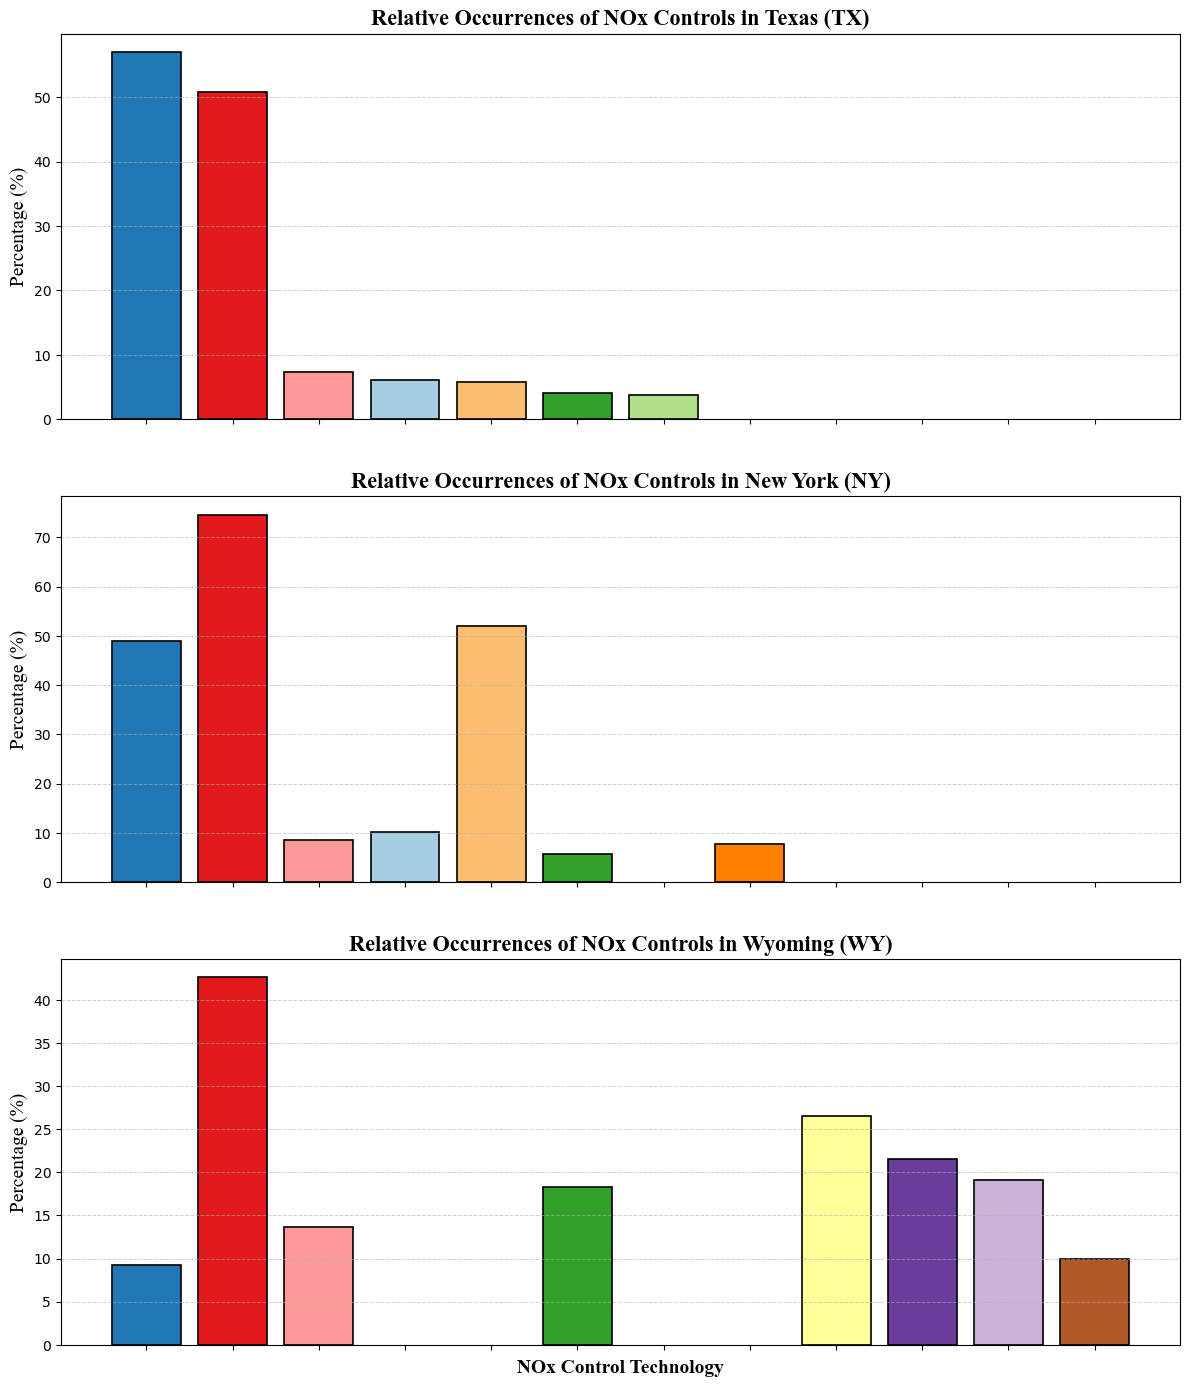

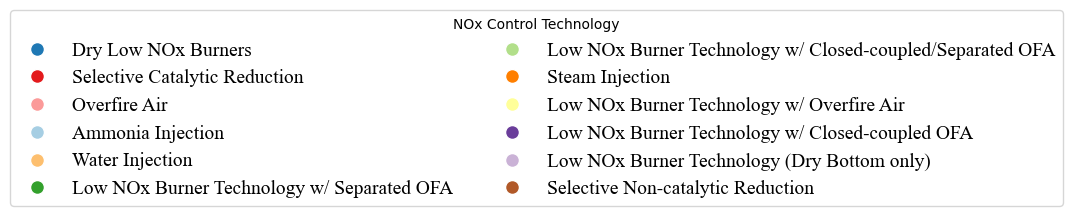

In [ ]:
# Compute percentage occurrence of each NOx control among those with controls
def compute_control_percentages(df, control_columns):
    df = df[df["Nothing"] != 1]  # Exclude rows without NOx controls
    
    percentages = df[control_columns].mean() * 100
    return pd.DataFrame({
        'Control Name': percentages.index,
        'Percentage': percentages.values
    })

# Calculate percentages from one-hot encoded DataFrames
nox_df_tx = compute_control_percentages(campd_tx_processed, tx_control_cols)
nox_df_ny = compute_control_percentages(campd_ny_processed, ny_control_cols)
nox_df_wy = compute_control_percentages(campd_wy_processed, wy_control_cols)

# Apply threshold
MIN_THRESHOLD = 3.0
filtered_dfs = {
    "Texas (TX)": nox_df_tx[nox_df_tx['Percentage'] >= MIN_THRESHOLD],
    "New York (NY)": nox_df_ny[nox_df_ny['Percentage'] >= MIN_THRESHOLD],
    "Wyoming (WY)": nox_df_wy[nox_df_wy['Percentage'] >= MIN_THRESHOLD]
}

# Combine all unique control names
all_controls = pd.concat([df["Control Name"] for df in filtered_dfs.values()]).unique()

# Define color mapping
colors = plt.colormaps["Paired"](range(len(all_controls)))
color_map = {control: colors[i] for i, control in enumerate(all_controls)}

# Initialize figure with academic-style aesthetics
fig, axes = plt.subplots(3, 1, figsize=(12, 18), sharex=True)

for (title, df), ax in zip(filtered_dfs.items(), axes):
    df_sorted = df.sort_values(by="Percentage", ascending=False)
    
    bars = ax.bar(
        df_sorted["Control Name"], df_sorted["Percentage"],
        color=[color_map[control] for control in df_sorted["Control Name"]],
        edgecolor="black", linewidth=1.2
    )
    
    ax.set_title(f"Relative Occurrences of NOx Controls in {title}", fontsize=16, fontweight="bold", fontname="Times New Roman")
    ax.set_ylabel("Percentage (%)", fontsize=14, fontname="Times New Roman")
    ax.tick_params(axis="x", rotation=45, labelsize=12)
    ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.6)
    ax.set_xticklabels([])  # suppress individual x-axis labels

# Improve spacing
plt.tight_layout()
plt.subplots_adjust(bottom=0.25, hspace=0.2)
plt.xlabel("NOx Control Technology", fontsize=14, fontweight='bold', font_properties=font_properties)
plt.show()

# Sort controls for legend (sequentially by percentage in TX, NY, WY)
legend_controls_sorted = []
def add_unique_values(df):
    df= df.sort_values(by='Percentage', ascending=False)
    for name in df["Control Name"]:
        if name not in legend_controls_sorted:
            legend_controls_sorted.append(name)
add_unique_values(nox_df_tx[nox_df_tx["Percentage"] >= 3])
add_unique_values(nox_df_ny[nox_df_ny["Percentage"] >= 3])
add_unique_values(nox_df_wy[nox_df_wy["Percentage"] >= 3])

# Build legend elements
legend_handles = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=color_map[control], markersize=10)
    for control in legend_controls_sorted
]

# Legend figure (separate to make it easier to read)
fig_legend = plt.figure(figsize=(10, 2))
plt.legend(
    legend_handles, legend_controls_sorted, title="NOx Control Technology",
    bbox_to_anchor=(0.5, 0.5), loc="center", fontsize=14, ncol=2, prop=font_properties
)
plt.axis("off")
plt.show()

<h3>Unit Type Energy Contribution</h3>

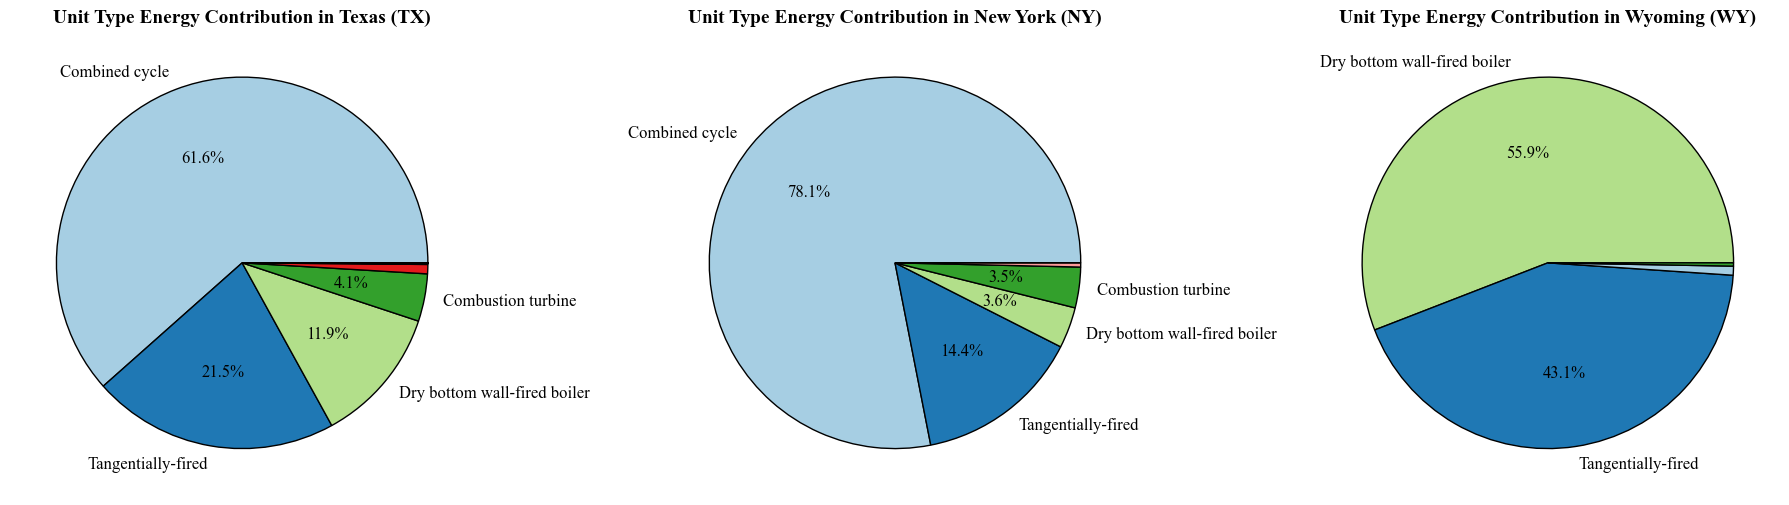

In [ ]:
# function to calc relative unit type frequencies based on Gross Load
def get_unit_type_relative_counts_by_load(df):
    # group by unit type and sum gross load for each unit type
    unit_type_load = df.groupby('Unit Type')['Gross Load (MW)'].sum()

    # normalize by the total Gross Load for the state
    total_load = unit_type_load.sum()
    unit_type_relative_load = unit_type_load / total_load
    
    # sort values in desc
    return unit_type_relative_load.sort_values(ascending=False)

# calc rel. freq. for each df
unit_type_counts_ny = get_unit_type_relative_counts_by_load(campd_ny)
unit_type_counts_tx = get_unit_type_relative_counts_by_load(campd_tx)
unit_type_counts_wy = get_unit_type_relative_counts_by_load(campd_wy)

# combine dfs
all_unit_types = pd.concat([unit_type_counts_ny, unit_type_counts_tx, unit_type_counts_wy]).index.unique()

# consistent color palette
colors = plt.cm.Paired(range(len(all_unit_types)))

# map each unit type to a color
unit_type_to_color = {unit: color for unit, color in zip(all_unit_types, colors)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

datasets = [
    ("Texas (TX)", unit_type_counts_tx, axes[0]),
    ("New York (NY)", unit_type_counts_ny, axes[1]),
    ("Wyoming (WY)", unit_type_counts_wy, axes[2])
]

# Function to format labels based on percentage threshold
def label_threshold(pct):
    return f"{pct:.1f}%" if pct > 1 else ""

# Create pie charts for each dataset
for title, unit_type_counts, ax in datasets:
    percentages = unit_type_counts.values / unit_type_counts.values.sum() * 100
    labels = [unit if pct > 1 else "" for unit, pct in zip(unit_type_counts.index, percentages)]  # Show names only for values >1%
    
    ax.pie(
        unit_type_counts.values,
        labels=labels,
        autopct=lambda p: label_threshold(p),  # Show percentages only above 1%
        colors=[unit_type_to_color[unit] for unit in unit_type_counts.index],
        wedgeprops={'edgecolor': 'black'},
        textprops={'fontsize': 12, 'fontname': 'Times New Roman'},
    )
    ax.set_title(f"Unit Type Energy Contribution in {title}", fontsize=14, fontweight="bold", fontname="Times New Roman")

plt.tight_layout()
plt.show()

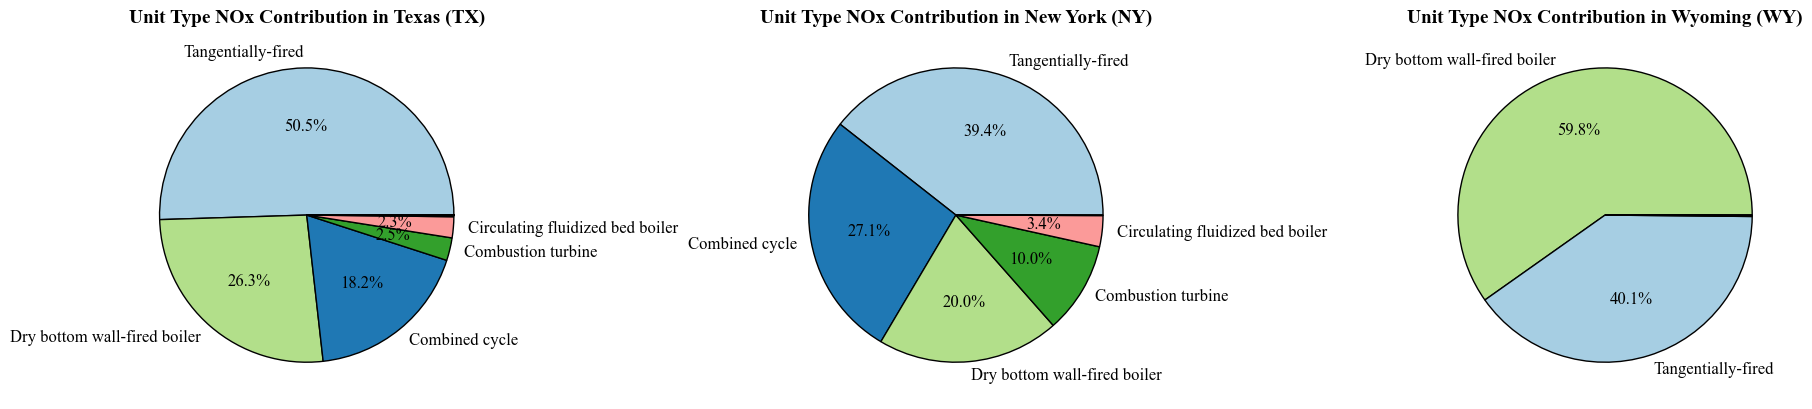

In [ ]:
# function to calc relative unit type frequencies based on NOx Mass contribution
def get_unit_type_relative_counts_by_load(df):
    # group by unit type and sum gross load for each unit type
    unit_type_load = df.groupby('Unit Type')['NOx Mass (lbs)'].sum()

    # normalize by the total Gross Load for the state
    total_load = unit_type_load.sum()
    unit_type_relative_load = unit_type_load / total_load
    
    # sort values in desc
    return unit_type_relative_load.sort_values(ascending=False)

# calc rel. freq. for each df
unit_type_counts_ny = get_unit_type_relative_counts_by_load(campd_ny)
unit_type_counts_tx = get_unit_type_relative_counts_by_load(campd_tx)
unit_type_counts_wy = get_unit_type_relative_counts_by_load(campd_wy)

# combine dfs
all_unit_types = pd.concat([unit_type_counts_ny, unit_type_counts_tx, unit_type_counts_wy]).index.unique()

# consistent color palette
colors = plt.cm.Paired(range(len(all_unit_types)))

# map each unit type to a color
unit_type_to_color = {unit: color for unit, color in zip(all_unit_types, colors)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

datasets = [
    ("Texas (TX)", unit_type_counts_tx, axes[0]),
    ("New York (NY)", unit_type_counts_ny, axes[1]),
    ("Wyoming (WY)", unit_type_counts_wy, axes[2])
]

# Function to format labels based on percentage threshold
def label_threshold(pct):
    return f"{pct:.1f}%" if pct > 1 else ""

# Create pie charts for each dataset
for title, unit_type_counts, ax in datasets:
    percentages = unit_type_counts.values / unit_type_counts.values.sum() * 100
    labels = [unit if pct > 1 else "" for unit, pct in zip(unit_type_counts.index, percentages)]  # Show names only for values >1%
    
    ax.pie(
        unit_type_counts.values,
        labels=labels,
        autopct=lambda p: label_threshold(p),  # Show percentages only above 1%
        colors=[unit_type_to_color[unit] for unit in unit_type_counts.index],
        wedgeprops={'edgecolor': 'black'},
        textprops={'fontsize': 12, 'fontname': 'Times New Roman'},
    )
    ax.set_title(f"Unit Type NOx Contribution in {title}", fontsize=14, fontweight="bold", fontname="Times New Roman")

plt.tight_layout()
plt.show()

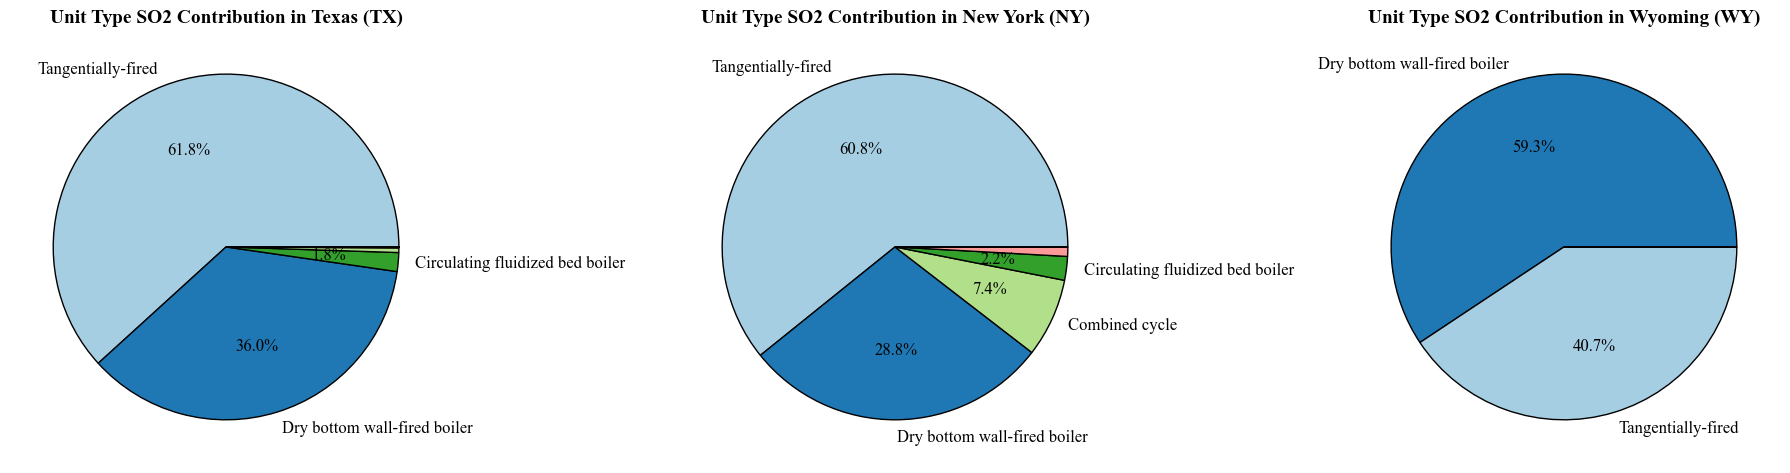

In [ ]:
# function to calc relative unit type frequencies based on SO2 Mass contribution
def get_unit_type_relative_counts_by_load(df):
    # group by unit type and sum gross load for each unit type
    unit_type_load = df.groupby('Unit Type')['SO2 Mass (lbs)'].sum()

    # normalize by the total Gross Load for the state
    total_load = unit_type_load.sum()
    unit_type_relative_load = unit_type_load / total_load
    
    # sort values in desc
    return unit_type_relative_load.sort_values(ascending=False)

# calc rel. freq. for each df
unit_type_counts_ny = get_unit_type_relative_counts_by_load(campd_ny)
unit_type_counts_tx = get_unit_type_relative_counts_by_load(campd_tx)
unit_type_counts_wy = get_unit_type_relative_counts_by_load(campd_wy)

# combine dfs
all_unit_types = pd.concat([unit_type_counts_ny, unit_type_counts_tx, unit_type_counts_wy]).index.unique()

# consistent color palette
colors = plt.cm.Paired(range(len(all_unit_types)))

# map each unit type to a color
unit_type_to_color = {unit: color for unit, color in zip(all_unit_types, colors)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

datasets = [
    ("Texas (TX)", unit_type_counts_tx, axes[0]),
    ("New York (NY)", unit_type_counts_ny, axes[1]),
    ("Wyoming (WY)", unit_type_counts_wy, axes[2])
]

# Function to format labels based on percentage threshold
def label_threshold(pct):
    return f"{pct:.1f}%" if pct > 1 else ""

# Create pie charts for each dataset
for title, unit_type_counts, ax in datasets:
    percentages = unit_type_counts.values / unit_type_counts.values.sum() * 100
    labels = [unit if pct > 1 else "" for unit, pct in zip(unit_type_counts.index, percentages)]  # Show names only for values >1%
    
    ax.pie(
        unit_type_counts.values,
        labels=labels,
        autopct=lambda p: label_threshold(p),  # Show percentages only above 1%
        colors=[unit_type_to_color[unit] for unit in unit_type_counts.index],
        wedgeprops={'edgecolor': 'black'},
        textprops={'fontsize': 12, 'fontname': 'Times New Roman'},
    )
    ax.set_title(f"Unit Type SO2 Contribution in {title}", fontsize=14, fontweight="bold", fontname="Times New Roman")

plt.tight_layout()
plt.show()

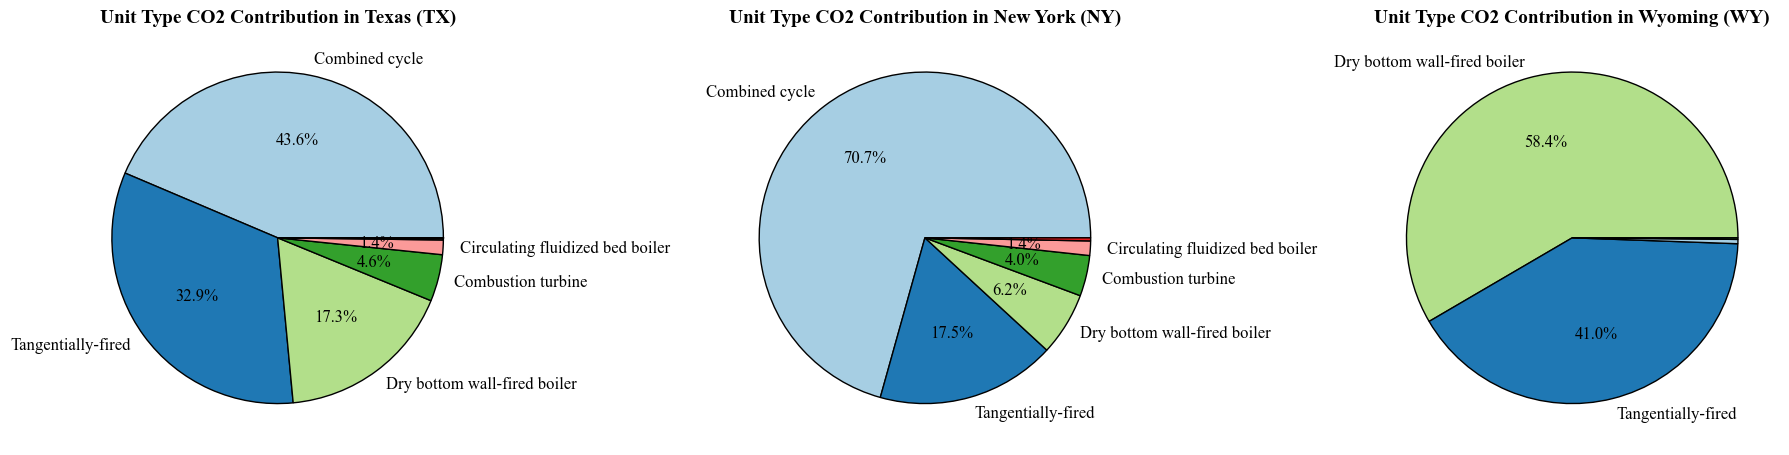

In [ ]:
# function to calc relative unit type frequencies based on CO2 Mass contributions
def get_unit_type_relative_counts_by_load(df):
    # group by unit type and sum gross load for each unit type
    unit_type_load = df.groupby('Unit Type')['CO2 Mass (short tons)'].sum()

    # normalize by the total Gross Load for the state
    total_load = unit_type_load.sum()
    unit_type_relative_load = unit_type_load / total_load
    
    # sort values in desc
    return unit_type_relative_load.sort_values(ascending=False)

# calc rel. freq. for each df
unit_type_counts_ny = get_unit_type_relative_counts_by_load(campd_ny)
unit_type_counts_tx = get_unit_type_relative_counts_by_load(campd_tx)
unit_type_counts_wy = get_unit_type_relative_counts_by_load(campd_wy)

# combine dfs
all_unit_types = pd.concat([unit_type_counts_ny, unit_type_counts_tx, unit_type_counts_wy]).index.unique()

# consistent color palette
colors = plt.cm.Paired(range(len(all_unit_types)))

# map each unit type to a color
unit_type_to_color = {unit: color for unit, color in zip(all_unit_types, colors)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

datasets = [
    ("Texas (TX)", unit_type_counts_tx, axes[0]),
    ("New York (NY)", unit_type_counts_ny, axes[1]),
    ("Wyoming (WY)", unit_type_counts_wy, axes[2])
]

# Function to format labels based on percentage threshold
def label_threshold(pct):
    return f"{pct:.1f}%" if pct > 1 else ""

# Create pie charts for each dataset
for title, unit_type_counts, ax in datasets:
    percentages = unit_type_counts.values / unit_type_counts.values.sum() * 100
    labels = [unit if pct > 1 else "" for unit, pct in zip(unit_type_counts.index, percentages)]  # Show names only for values >1%
    
    ax.pie(
        unit_type_counts.values,
        labels=labels,
        autopct=lambda p: label_threshold(p),  # Show percentages only above 1%
        colors=[unit_type_to_color[unit] for unit in unit_type_counts.index],
        wedgeprops={'edgecolor': 'black'},
        textprops={'fontsize': 12, 'fontname': 'Times New Roman'},
    )
    ax.set_title(f"Unit Type CO2 Contribution in {title}", fontsize=14, fontweight="bold", fontname="Times New Roman")

plt.tight_layout()
plt.show()

<h3>Fuel Type Energy Contribution</h3>

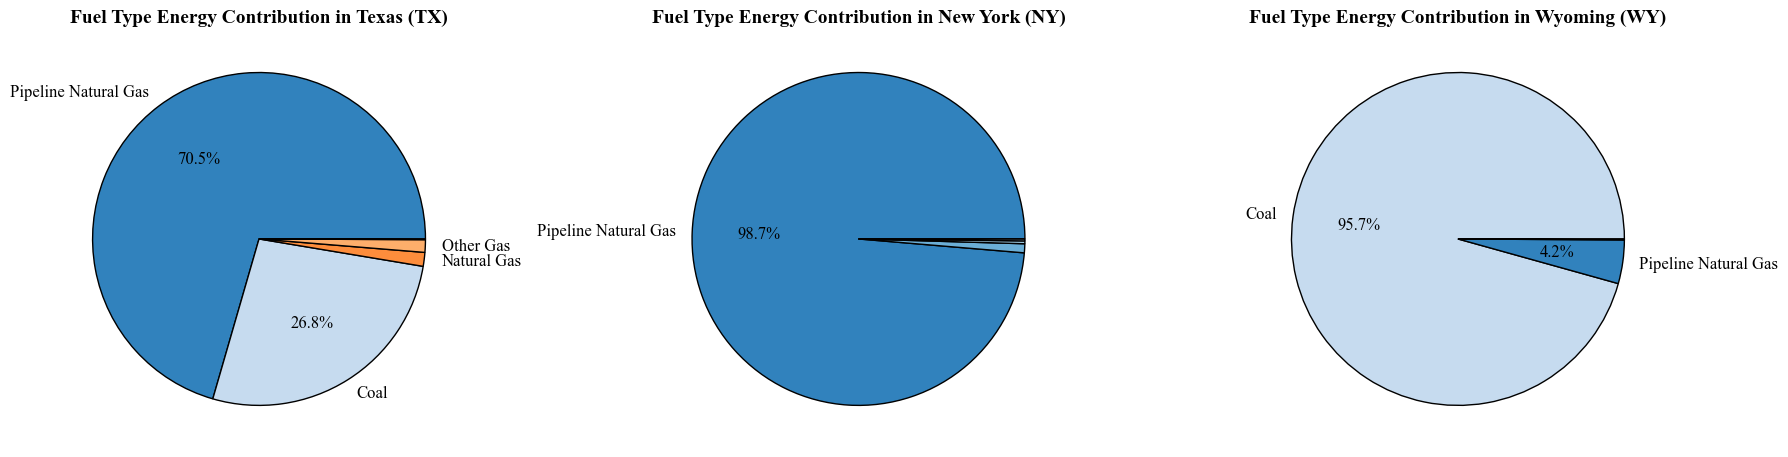

In [ ]:
# Function to calculate relative fuel type frequencies based on Gross Load
def get_fuel_type_relative_counts_by_load(df):
    fuel_type_load = df.groupby('Primary Fuel Type')['Gross Load (MW)'].sum()
    total_load = fuel_type_load.sum()
    fuel_type_relative_load = fuel_type_load / total_load
    return fuel_type_relative_load.sort_values(ascending=False)

# Calculate relative frequency for each state
fuel_type_counts_ny = get_fuel_type_relative_counts_by_load(campd_ny)
fuel_type_counts_tx = get_fuel_type_relative_counts_by_load(campd_tx)
fuel_type_counts_wy = get_fuel_type_relative_counts_by_load(campd_wy)

# Combine indexes to get unique fuel types across all states
all_fuel_types = pd.concat([fuel_type_counts_ny, fuel_type_counts_tx, fuel_type_counts_wy]).index.unique()

# Assign consistent colors
colors = plt.cm.tab20c(range(len(all_fuel_types)))
fuel_type_to_color = {fuel: color for fuel, color in zip(all_fuel_types, colors)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Define datasets for plotting
datasets = [
    ("Texas (TX)", fuel_type_counts_tx, axes[0]),
    ("New York (NY)", fuel_type_counts_ny, axes[1]),
    ("Wyoming (WY)", fuel_type_counts_wy, axes[2])
]

# Function to show label if >%3
def label_threshold(pct):
    return f"{pct:.1f}%" if pct > 3 else ""

for title, fuel_type_counts, ax in datasets:
    percentages = fuel_type_counts.values / fuel_type_counts.values.sum() * 100
    labels = [fuel if pct > 1 else "" for fuel, pct in zip(fuel_type_counts.index, percentages)]
    
    ax.pie(
        fuel_type_counts.values,
        labels=labels,
        autopct=lambda p: label_threshold(p),
        colors=[fuel_type_to_color[fuel] for fuel in fuel_type_counts.index],
        wedgeprops={'edgecolor': 'black'},
        textprops={'fontsize': 12, 'fontname': 'Times New Roman'},
    )
    ax.set_title(f"Fuel Type Energy Contribution in {title}", fontsize=14, fontweight="bold", fontname="Times New Roman")

plt.tight_layout()
plt.show()


<h3>Scatter Plots</h3>

<h4>Gross Load</h4>

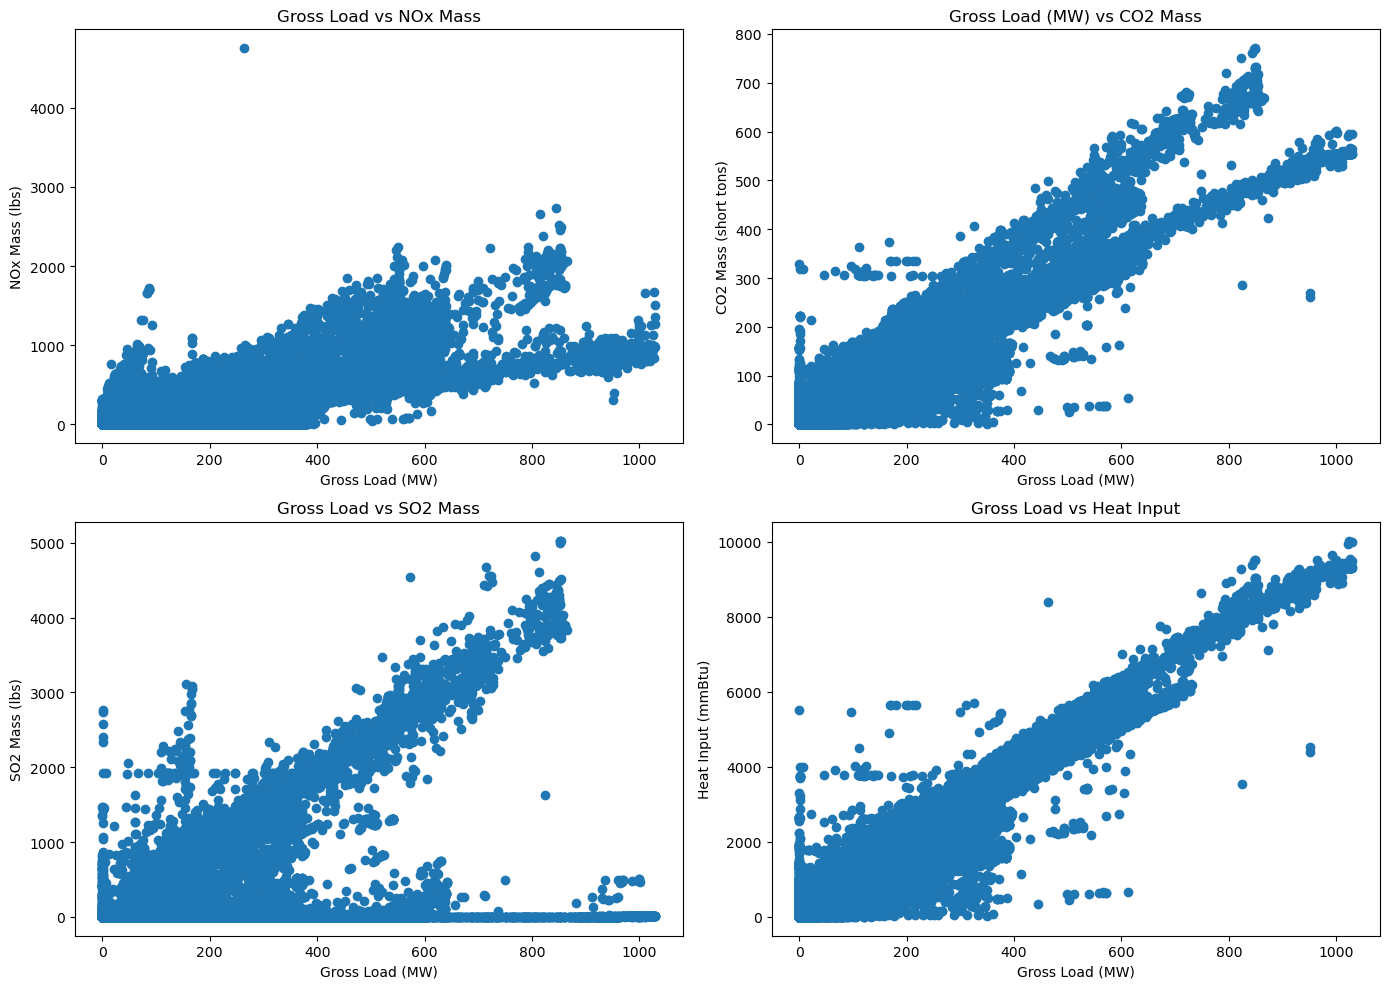

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(campd_ny['Gross Load (MW)'], campd_ny['NOx Mass (lbs)'])
axes[0, 0].set_xlabel('Gross Load (MW)')
axes[0, 0].set_ylabel('NOx Mass (lbs)')
axes[0, 0].set_title('Gross Load vs NOx Mass')

axes[0, 1].scatter(campd_ny['Gross Load (MW)'], campd_ny['CO2 Mass (short tons)'])
axes[0, 1].set_xlabel('Gross Load (MW)')
axes[0, 1].set_ylabel('CO2 Mass (short tons)')
axes[0, 1].set_title('Gross Load (MW) vs CO2 Mass')

axes[1, 0].scatter(campd_ny['Gross Load (MW)'], campd_ny['SO2 Mass (lbs)'])
axes[1, 0].set_xlabel('Gross Load (MW)')
axes[1, 0].set_ylabel('SO2 Mass (lbs)')
axes[1, 0].set_title('Gross Load vs SO2 Mass')

axes[1, 1].scatter(campd_ny['Gross Load (MW)'], campd_ny['Heat Input (mmBtu)'])
axes[1, 1].set_xlabel('Gross Load (MW)')
axes[1, 1].set_ylabel('Heat Input (mmBtu)')
axes[1, 1].set_title('Gross Load vs Heat Input')

plt.tight_layout()
plt.show()


<h4>Unit Age</h4>

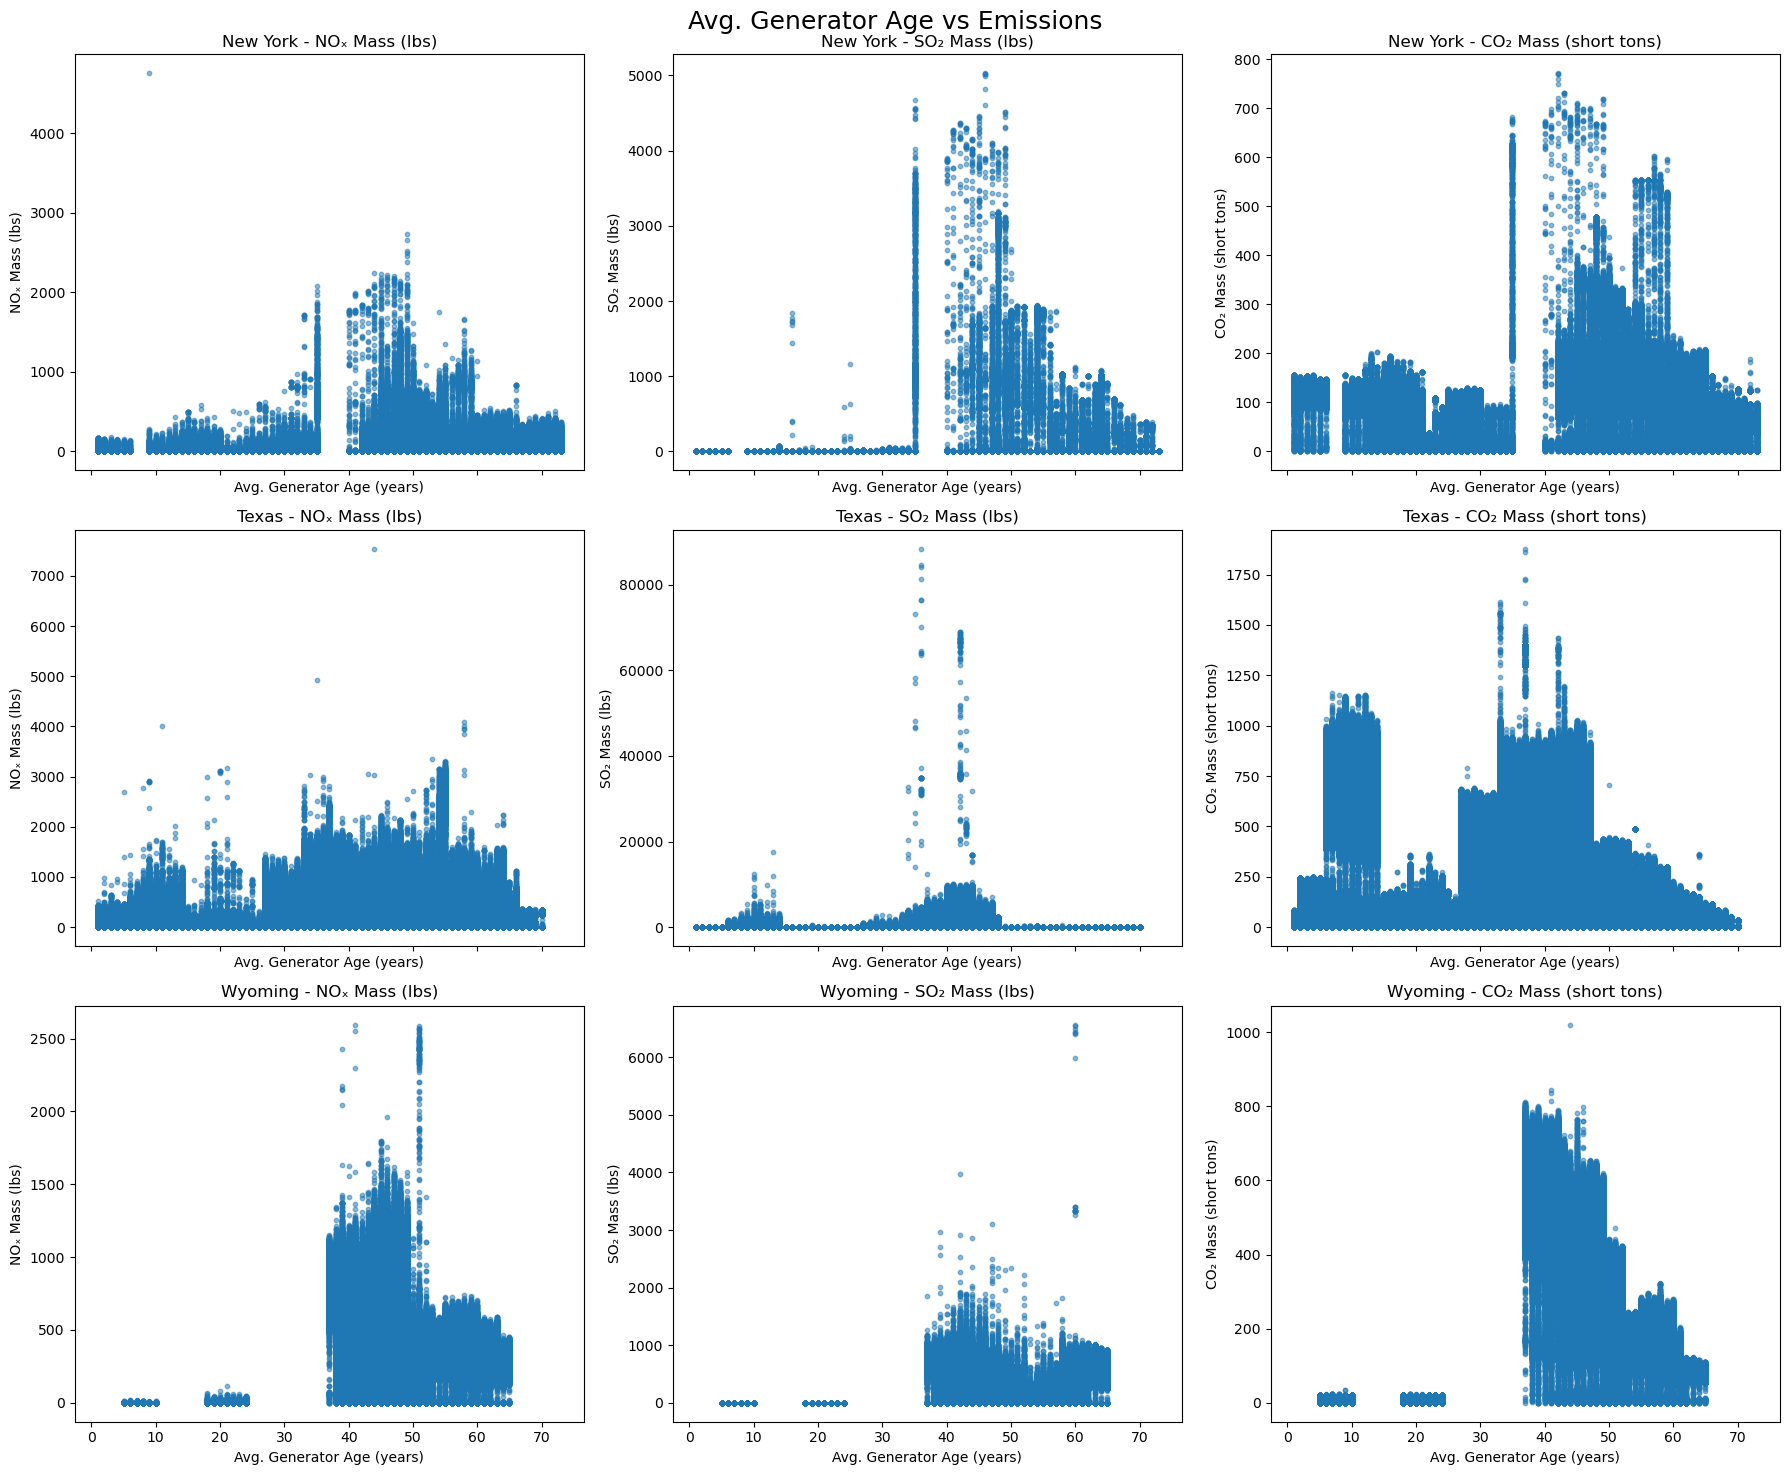

In [ ]:
states_data = {
    "New York": campd_ny,
    "Texas": campd_tx,
    "Wyoming": campd_wy
}

emissions = [
    ("NOx Mass (lbs)", "NOₓ Mass (lbs)"),
    ("SO2 Mass (lbs)", "SO₂ Mass (lbs)"),
    ("CO2 Mass (short tons)", "CO₂ Mass (short tons)")
]

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 15), sharex=True)
fig.suptitle("Avg. Generator Age vs Emissions", fontsize=18)

for i, (state_name, df) in enumerate(states_data.items()):
    for j, (em_col, em_label) in enumerate(emissions):
        ax = axes[i, j]
        ax.scatter(df["unit_age_mean"], df[em_col], alpha=0.5, s=10)
        ax.set_title(f"{state_name} - {em_label}")
        ax.set_xlabel("Avg. Generator Age (years)")
        ax.set_ylabel(em_label)

plt.tight_layout()
plt.show()

# distribution of mean generator age is unlikely to be a good (causal) predictor
# would probably act as more of a proxy of facility or unit id

C:\Users\marce\AppData\Local\Temp\ipykernel_28796\3973491583.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="CO2 Mass (short tons)", y="Facility Name", data=facility_co2, palette="Reds_r")


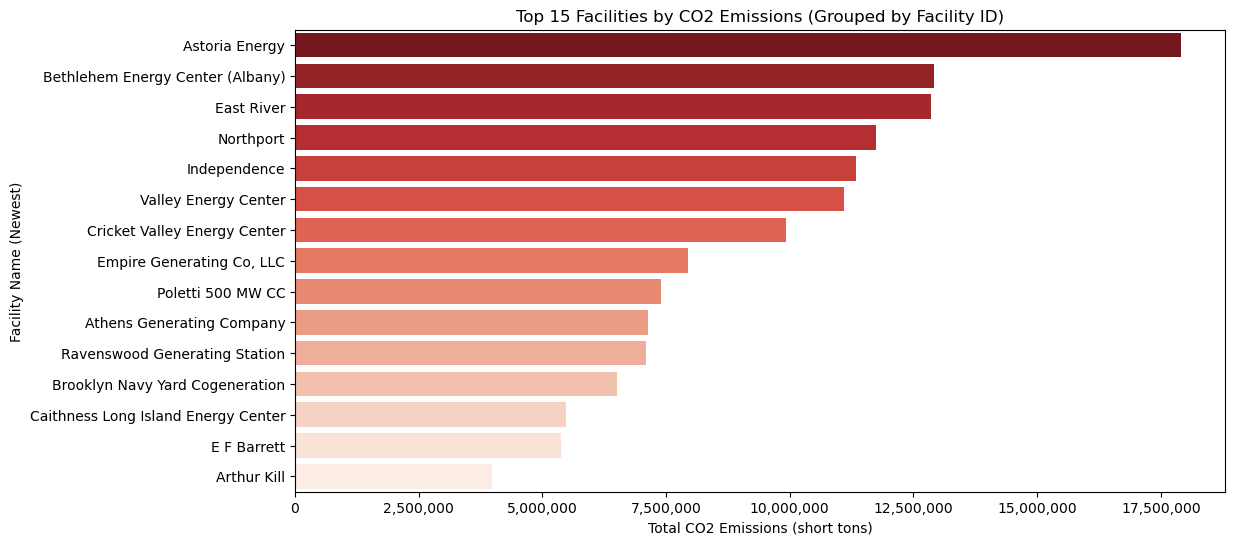

In [ ]:
# Top emitters by facility

facility_co2 = campd_ny.groupby("Facility ID")["CO2 Mass (short tons)"].sum().reset_index()

latest_facility_names = campd_ny.sort_values(by="Year", ascending=False).drop_duplicates(subset="Facility ID")[["Facility ID", "Facility Name"]]

facility_co2 = facility_co2.merge(latest_facility_names, on="Facility ID", how="left")

facility_co2 = facility_co2.sort_values(by="CO2 Mass (short tons)", ascending=False).head(15)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x="CO2 Mass (short tons)", y="Facility Name", data=facility_co2, palette="Reds_r")

# Format x-axis with commas
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"{x:,.0f}"))

plt.xlabel("Total CO2 Emissions (short tons)")
plt.ylabel("Facility Name (Newest)")
plt.title("Top 15 Facilities by CO2 Emissions (Grouped by Facility ID)")
plt.show()

<h3>Boxplots</h3>

,Gross Load (MW),NOx Mass (lbs),CO2 Mass (short tons),SO2 Mass (lbs)
count,2175690.00,2400701.00,2400701.00,2400701.00
mean,154.93,36.10,71.10,7.10
std,112.19,74.18,50.33,97.49
min,0.00,0.00,0.00,0.00
25%,48.00,8.70,26.70,0.28
50%,133.00,13.30,67.80,0.73
75%,253.00,31.60,107.60,1.11
max,1030.00,4754.10,771.00,5029.30



99.0 % of NOx Mass entries are below 500 lbs

99.0 % of SO2 Mass entries are below 200 lbs


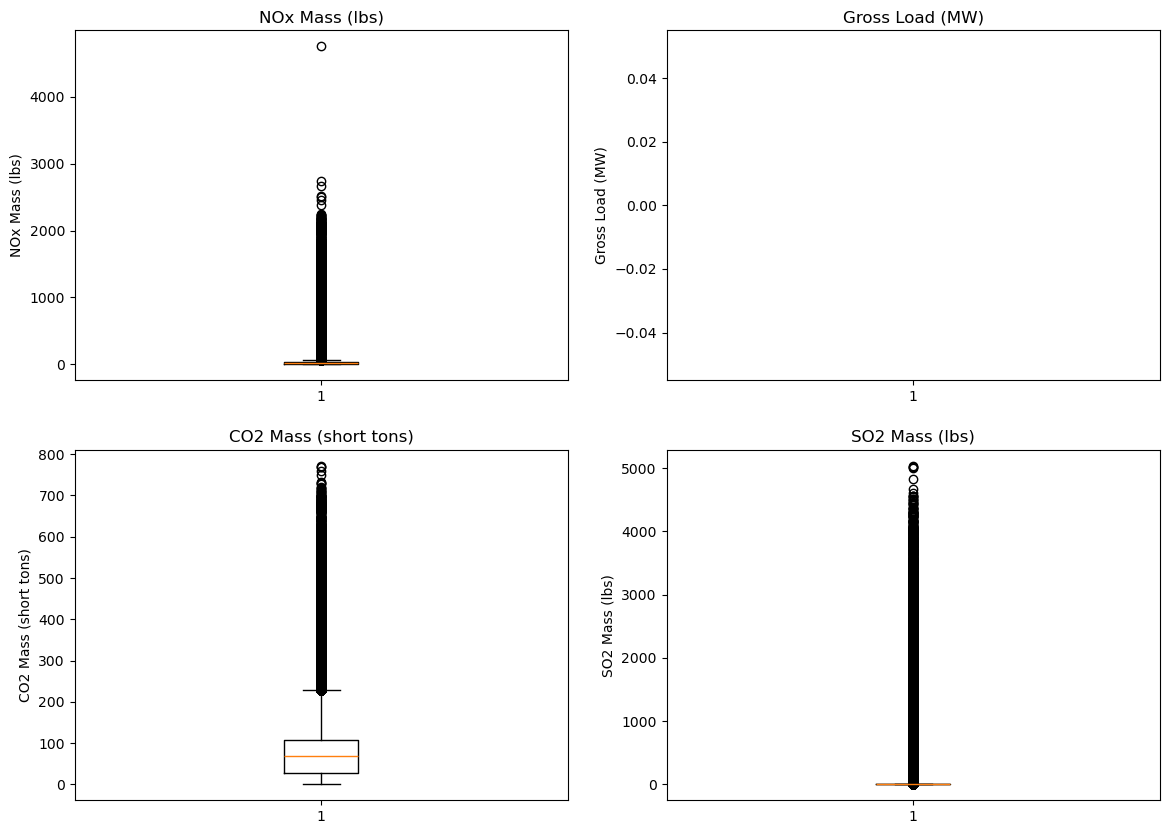

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].boxplot(campd_ny["NOx Mass (lbs)"])
axes[0, 0].set_title("NOx Mass (lbs)")
axes[0, 0].set_ylabel("NOx Mass (lbs)")

#axes[0, 1].boxplot(campd_ny["Gross Load (MW)"])
#axes[0, 1].set_title("Gross Load (MW)")
#axes[0, 1].set_ylabel("Gross Load (MW)")

axes[1, 0].boxplot(campd_ny["CO2 Mass (short tons)"])
axes[1, 0].set_title("CO2 Mass (short tons)")
axes[1, 0].set_ylabel("CO2 Mass (short tons)")

axes[1, 1].boxplot(campd_ny["SO2 Mass (lbs)"])
axes[1, 1].set_title("SO2 Mass (lbs)")
axes[1, 1].set_ylabel("SO2 Mass (lbs)")

# Disable scientific notation
pd.set_option('display.float_format', '{:.2f}'.format)
display(campd_ny[["Gross Load (MW)", "NOx Mass (lbs)", "CO2 Mass (short tons)", "SO2 Mass (lbs)"]].describe())

print("")
print(round(campd_ny[campd_ny["NOx Mass (lbs)"] <= 500]["NOx Mass (lbs)"].count() / campd_ny["NOx Mass (lbs)"].count(),2)*100, "% of NOx Mass entries are below 500 lbs")
print("")
print(round(campd_ny[campd_ny["SO2 Mass (lbs)"] <= 200]["SO2 Mass (lbs)"].count() / campd_ny["SO2 Mass (lbs)"].count(),2)*100, "% of SO2 Mass entries are below 200 lbs")
pd.reset_option('display.float_format')


<h4>Yearly Emission Distribution</h4>

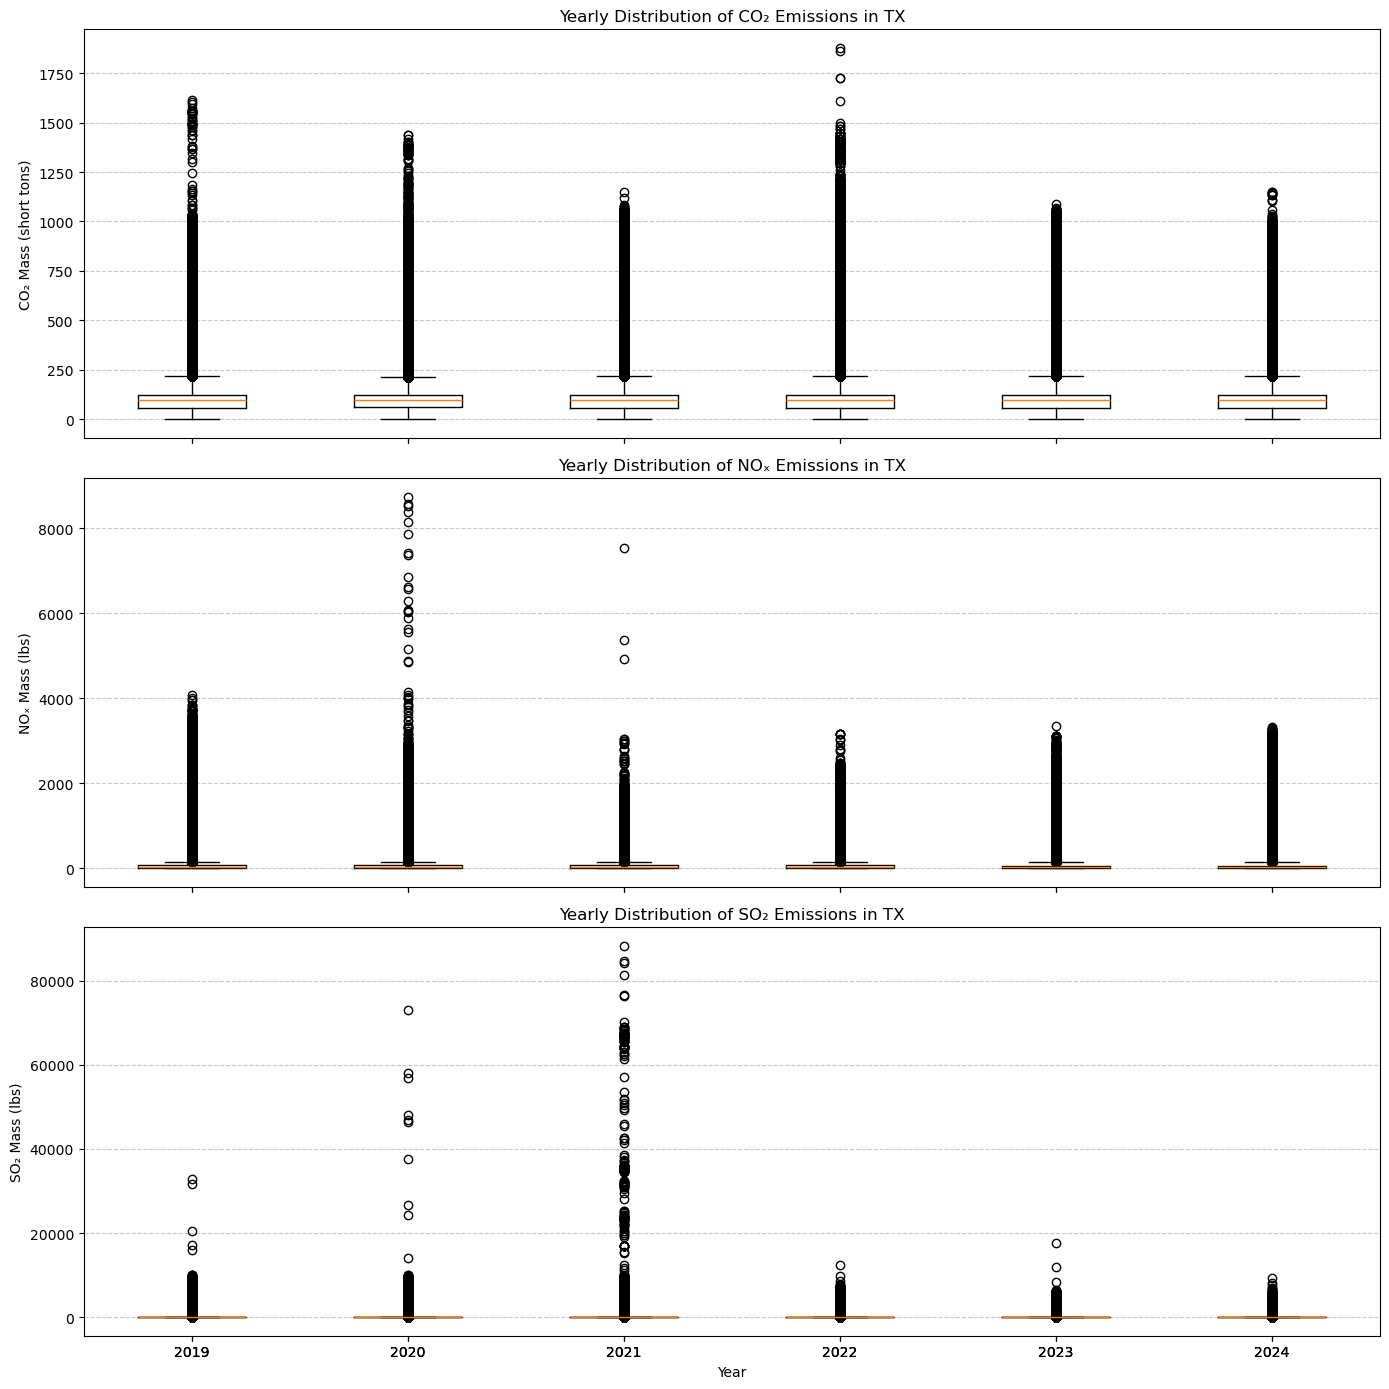

In [ ]:
df = campd_tx[["CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Year"]].dropna()

fig, axes = plt.subplots(3, 1, figsize=(14, 14), sharex=True)

# CO2
grouped_co2 = df.groupby("Year")["CO2 Mass (short tons)"]
data_co2 = [group.values for _, group in grouped_co2]
labels = [str(int(year)) for year in grouped_co2.groups.keys()]

axes[0].boxplot(data_co2, tick_labels=labels)
axes[0].set_title("Yearly Distribution of CO₂ Emissions in TX")
axes[0].set_ylabel("CO₂ Mass (short tons)")
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# NOx
grouped_nox = df.groupby("Year")["NOx Mass (lbs)"]
data_nox = [group.values for _, group in grouped_nox]

axes[1].boxplot(data_nox, tick_labels=labels)
axes[1].set_title("Yearly Distribution of NOₓ Emissions in TX")
axes[1].set_ylabel("NOₓ Mass (lbs)")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# SO2
grouped_so2 = df.groupby("Year")["SO2 Mass (lbs)"]
data_so2 = [group.values for _, group in grouped_so2]

axes[2].boxplot(data_so2, tick_labels=labels)
axes[2].set_title("Yearly Distribution of SO₂ Emissions in TX")
axes[2].set_ylabel("SO₂ Mass (lbs)")
axes[2].set_xlabel("Year")
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks()
plt.tight_layout()
plt.show()


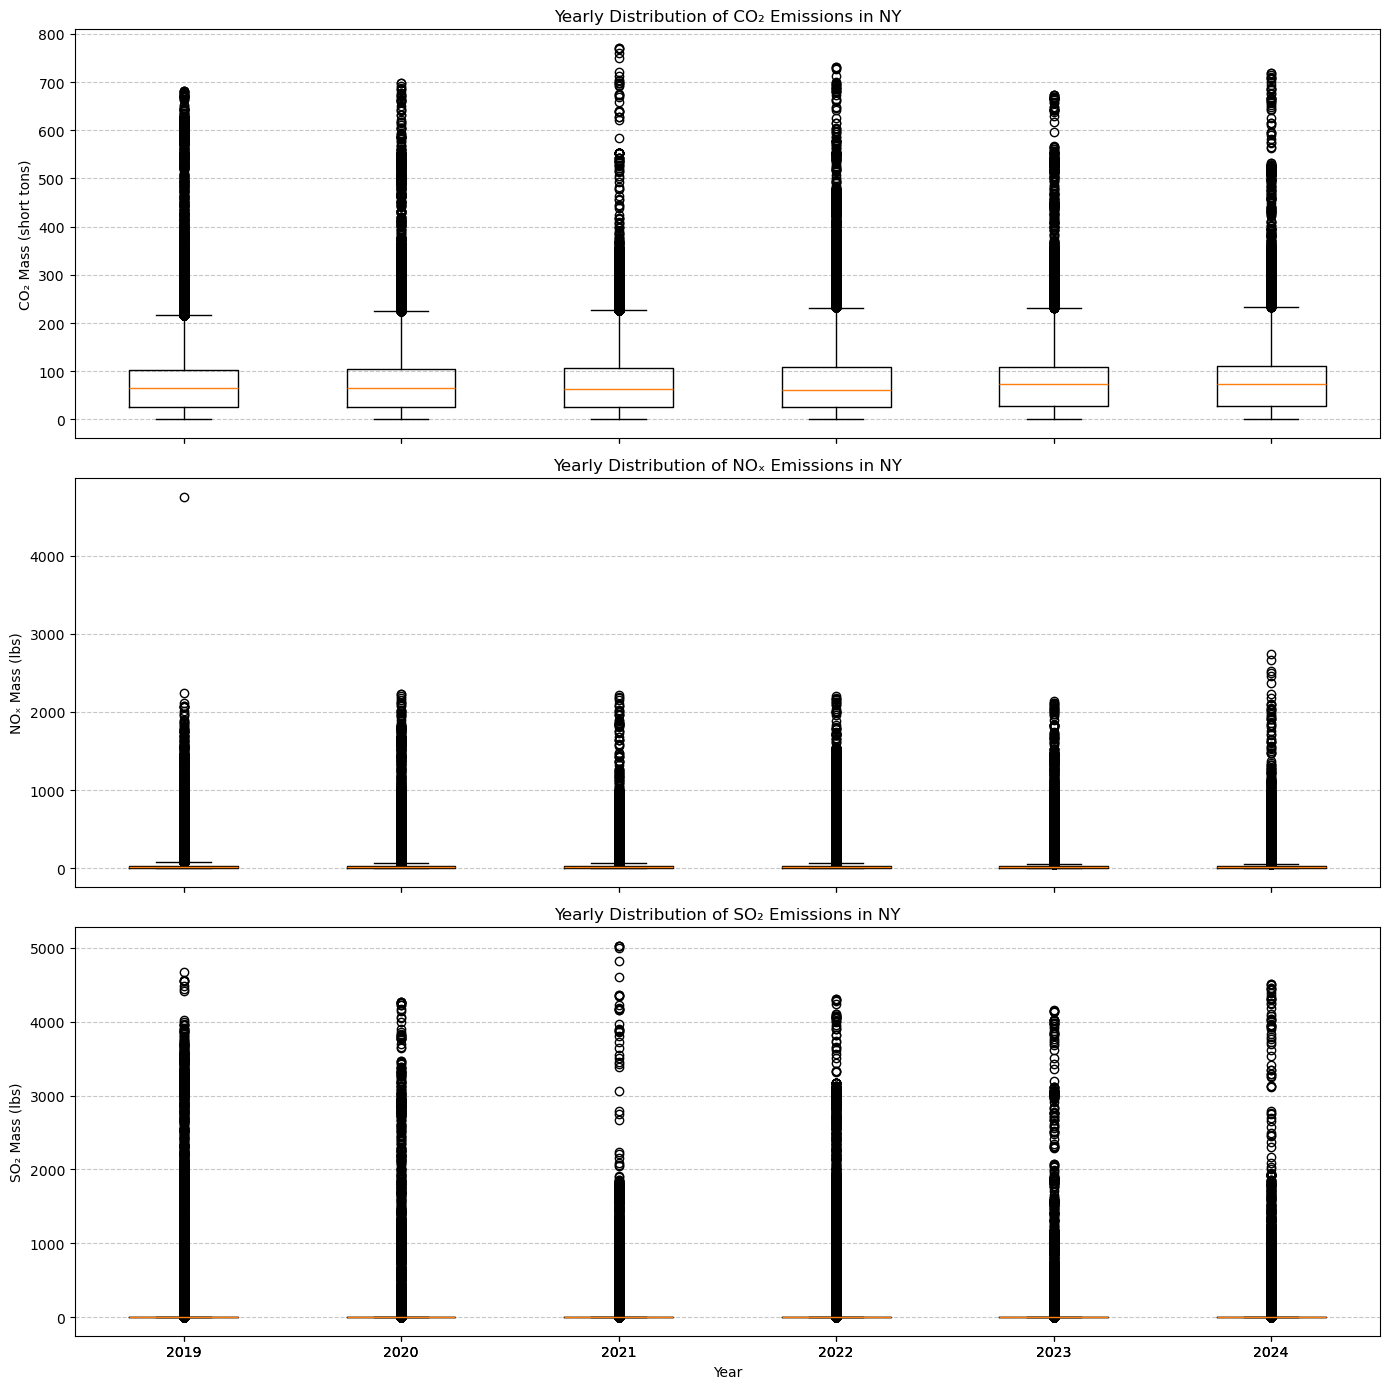

In [ ]:
df = campd_ny[["CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Year"]].dropna()

fig, axes = plt.subplots(3, 1, figsize=(14, 14), sharex=True)

# CO2
grouped_co2 = df.groupby("Year")["CO2 Mass (short tons)"]
data_co2 = [group.values for _, group in grouped_co2]
labels = [str(int(year)) for year in grouped_co2.groups.keys()]

axes[0].boxplot(data_co2, tick_labels=labels)
axes[0].set_title("Yearly Distribution of CO₂ Emissions in NY")
axes[0].set_ylabel("CO₂ Mass (short tons)")
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# NOx
grouped_nox = df.groupby("Year")["NOx Mass (lbs)"]
data_nox = [group.values for _, group in grouped_nox]

axes[1].boxplot(data_nox, tick_labels=labels)
axes[1].set_title("Yearly Distribution of NOₓ Emissions in NY")
axes[1].set_ylabel("NOₓ Mass (lbs)")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# SO2
grouped_so2 = df.groupby("Year")["SO2 Mass (lbs)"]
data_so2 = [group.values for _, group in grouped_so2]

axes[2].boxplot(data_so2, tick_labels=labels)
axes[2].set_title("Yearly Distribution of SO₂ Emissions in NY")
axes[2].set_ylabel("SO₂ Mass (lbs)")
axes[2].set_xlabel("Year")
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks()
plt.tight_layout()
plt.show()


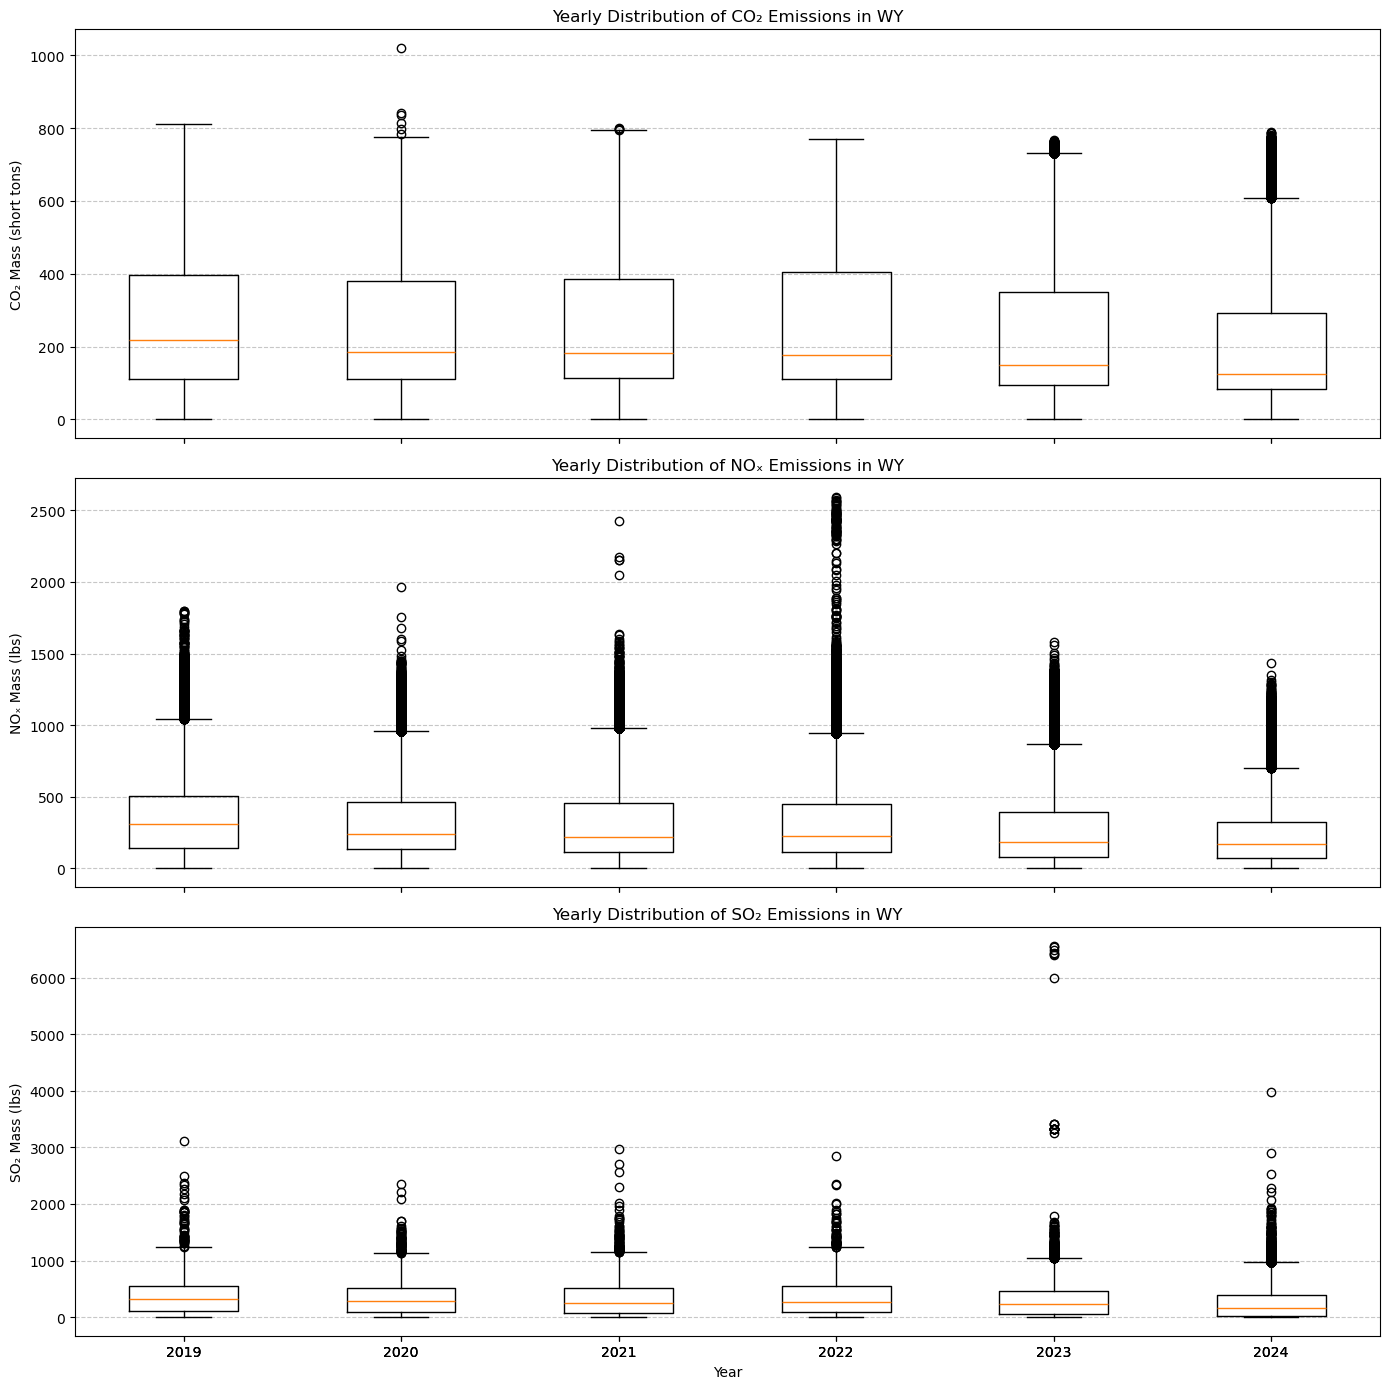

In [ ]:
df = campd_wy[["CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Year"]].dropna()

fig, axes = plt.subplots(3, 1, figsize=(14, 14), sharex=True)

# CO2
grouped_co2 = df.groupby("Year")["CO2 Mass (short tons)"]
data_co2 = [group.values for _, group in grouped_co2]
labels = [str(int(year)) for year in grouped_co2.groups.keys()]

axes[0].boxplot(data_co2, tick_labels=labels)
axes[0].set_title("Yearly Distribution of CO₂ Emissions in WY")
axes[0].set_ylabel("CO₂ Mass (short tons)")
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# NOx
grouped_nox = df.groupby("Year")["NOx Mass (lbs)"]
data_nox = [group.values for _, group in grouped_nox]

axes[1].boxplot(data_nox, tick_labels=labels)
axes[1].set_title("Yearly Distribution of NOₓ Emissions in WY")
axes[1].set_ylabel("NOₓ Mass (lbs)")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# SO2
grouped_so2 = df.groupby("Year")["SO2 Mass (lbs)"]
data_so2 = [group.values for _, group in grouped_so2]

axes[2].boxplot(data_so2, tick_labels=labels)
axes[2].set_title("Yearly Distribution of SO₂ Emissions in WY")
axes[2].set_ylabel("SO₂ Mass (lbs)")
axes[2].set_xlabel("Year")
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks()
plt.tight_layout()
plt.show()


<h4>Complete Emission Distribution</h4>

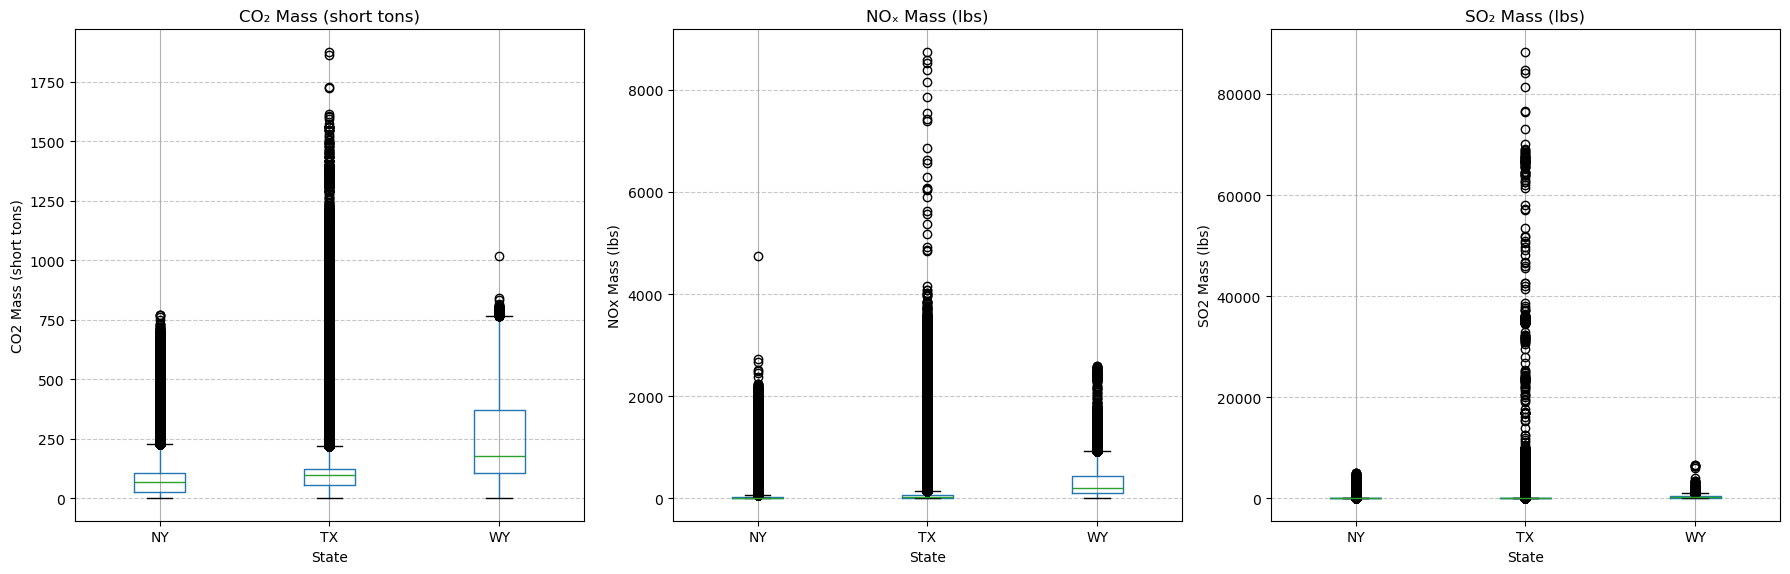

In [ ]:
# absolute

# Add a state column to each df
campd_tx["State"] = "TX"
campd_wy["State"] = "WY"
campd_ny["State"] = "NY"

df = pd.concat([campd_tx, campd_wy, campd_ny])

df = df[["State", "CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)"]].dropna()

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=False)

# Emissions and labels
emissions = [
    ("CO2 Mass (short tons)", "CO₂ Mass (short tons)"),
    ("NOx Mass (lbs)", "NOₓ Mass (lbs)"),
    ("SO2 Mass (lbs)", "SO₂ Mass (lbs)")
]

# Plot boxplots by state for each emission type
for ax, (col, title) in zip(axes, emissions):
    df.boxplot(column=col, by="State", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("State")
    ax.set_ylabel(col)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle("")
plt.tight_layout()
plt.show()


<h3>Histograms</h3>

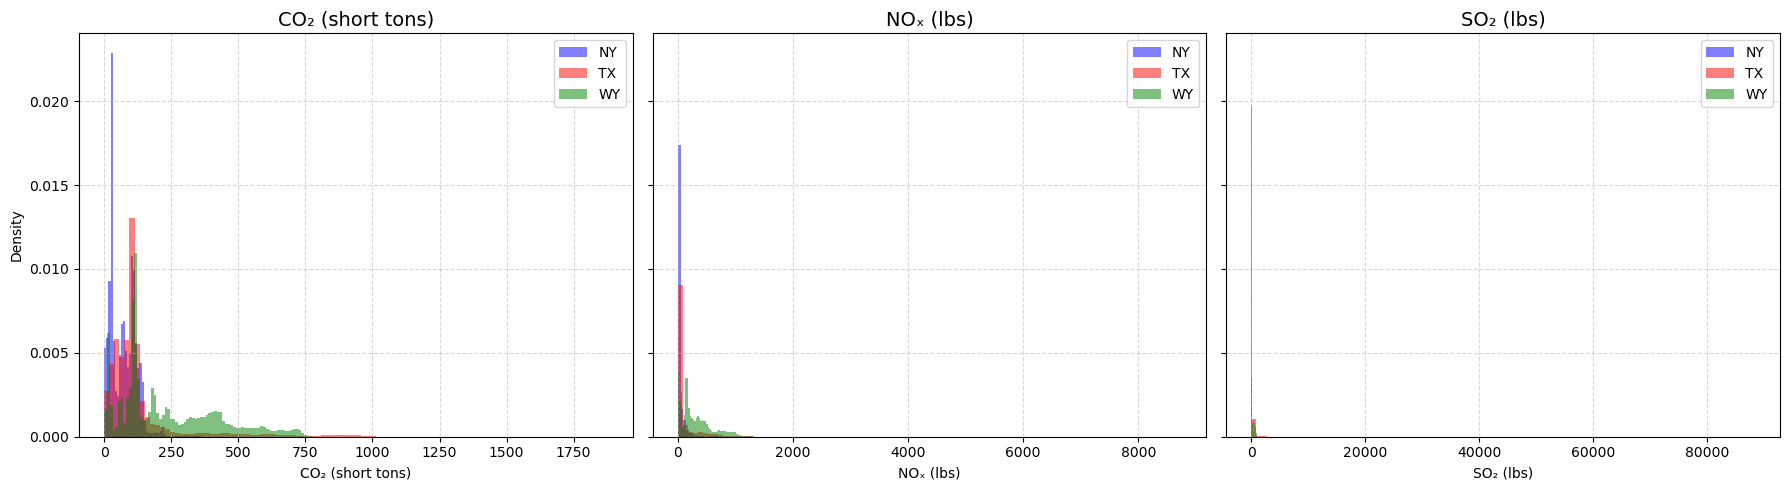

In [ ]:
co2_cols = ["State", "CO2 Mass (short tons)"]
nox_cols = ["State", "NOx Mass (lbs)"]
so2_cols = ["State", "SO2 Mass (lbs)"]

df_co2 = pd.concat([
    campd_ny[co2_cols].assign(Pollutant="CO2"),
    campd_tx[co2_cols].assign(Pollutant="CO2"),
    campd_wy[co2_cols].assign(Pollutant="CO2")
])

df_nox = pd.concat([
    campd_ny[nox_cols].assign(Pollutant="NOx"),
    campd_tx[nox_cols].assign(Pollutant="NOx"),
    campd_wy[nox_cols].assign(Pollutant="NOx")
])

df_so2 = pd.concat([
    campd_ny[so2_cols].assign(Pollutant="SO2"),
    campd_tx[so2_cols].assign(Pollutant="SO2"),
    campd_wy[so2_cols].assign(Pollutant="SO2")
])

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

pollutants = {
    "CO2": ("CO2 Mass (short tons)", "CO₂ (short tons)"),
    "NOx": ("NOx Mass (lbs)", "NOₓ (lbs)"),
    "SO2": ("SO2 Mass (lbs)", "SO₂ (lbs)")
}

colors = {"NY": "blue", "TX": "red", "WY": "green"}

for ax, (poll, (col, title)) in zip(axes, pollutants.items()):
    for state, color in colors.items():
        if poll == "CO2":
            data = df_co2[df_co2["State"] == state][col].dropna()
        elif poll == "NOx":
            data = df_nox[df_nox["State"] == state][col].dropna()
        else:
            data = df_so2[df_so2["State"] == state][col].dropna()
        
        ax.hist(data, bins=100, alpha=0.5, label=state, color=color,
                density=True, log=False)  

    ax.set_title(title, fontsize=14)
    ax.set_xlabel(title)
    ax.grid(True, linestyle='--', alpha=0.5)
    if ax == axes[0]:
        ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


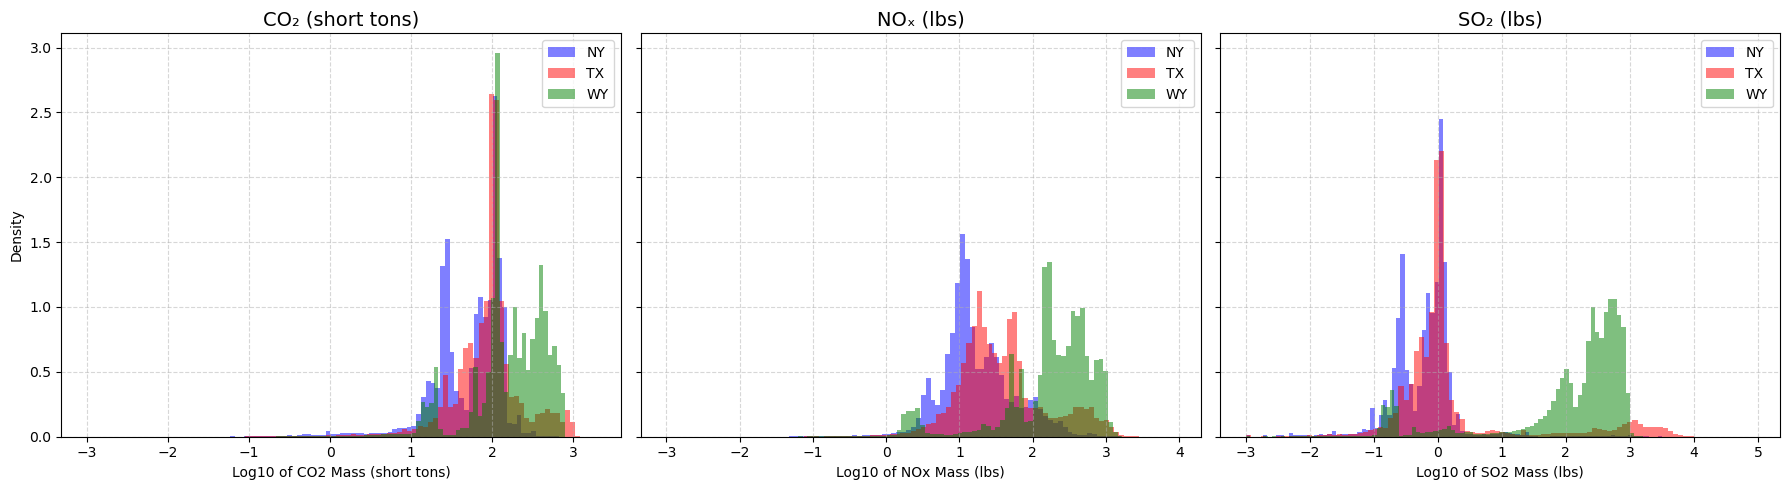

In [ ]:
# log-scaled emission distribution

co2_cols = ["State", "CO2 Mass (short tons)"]
nox_cols = ["State", "NOx Mass (lbs)"]
so2_cols = ["State", "SO2 Mass (lbs)"]

df_co2 = pd.concat([
    campd_ny[co2_cols].assign(Pollutant="CO2"),
    campd_tx[co2_cols].assign(Pollutant="CO2"),
    campd_wy[co2_cols].assign(Pollutant="CO2")
])

df_nox = pd.concat([
    campd_ny[nox_cols].assign(Pollutant="NOx"),
    campd_tx[nox_cols].assign(Pollutant="NOx"),
    campd_wy[nox_cols].assign(Pollutant="NOx")
])

df_so2 = pd.concat([
    campd_ny[so2_cols].assign(Pollutant="SO2"),
    campd_tx[so2_cols].assign(Pollutant="SO2"),
    campd_wy[so2_cols].assign(Pollutant="SO2")
])
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

pollutants = {
    "CO2": ("CO2 Mass (short tons)", "CO₂ (short tons)"),
    "NOx": ("NOx Mass (lbs)", "NOₓ (lbs)"),
    "SO2": ("SO2 Mass (lbs)", "SO₂ (lbs)")
}

colors = {"NY": "blue", "TX": "red", "WY": "green"}

for ax, (poll, (col, title)) in zip(axes, pollutants.items()):
    for state, color in colors.items():
        if poll == "CO2":
            data = df_co2[df_co2["State"] == state][col].dropna()
        elif poll == "NOx":
            data = df_nox[df_nox["State"] == state][col].dropna()
        else:
            data = df_so2[df_so2["State"] == state][col].dropna()
        
        # Filter out zero values before log-transform
        data_pos = data[data > 0]
        
        # Log-transform the data
        log_data = np.log10(data_pos)
        
        ax.hist(log_data, bins=100, alpha=0.5, label=state, color=color, density=True)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel(f'Log10 of {col}')
    ax.grid(True, linestyle='--', alpha=0.5)
    if ax == axes[0]:
        ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


<h3>Relationship Analysis</h3>

In [ ]:
# first, check the distribution for later assumptions (by example of TX)

# Data is clearly not normally distributed -> important assumption for e. g. Pearson Correlation, we use Spearman instead

<Axes: xlabel='NOx Mass (lbs)', ylabel='Count'>

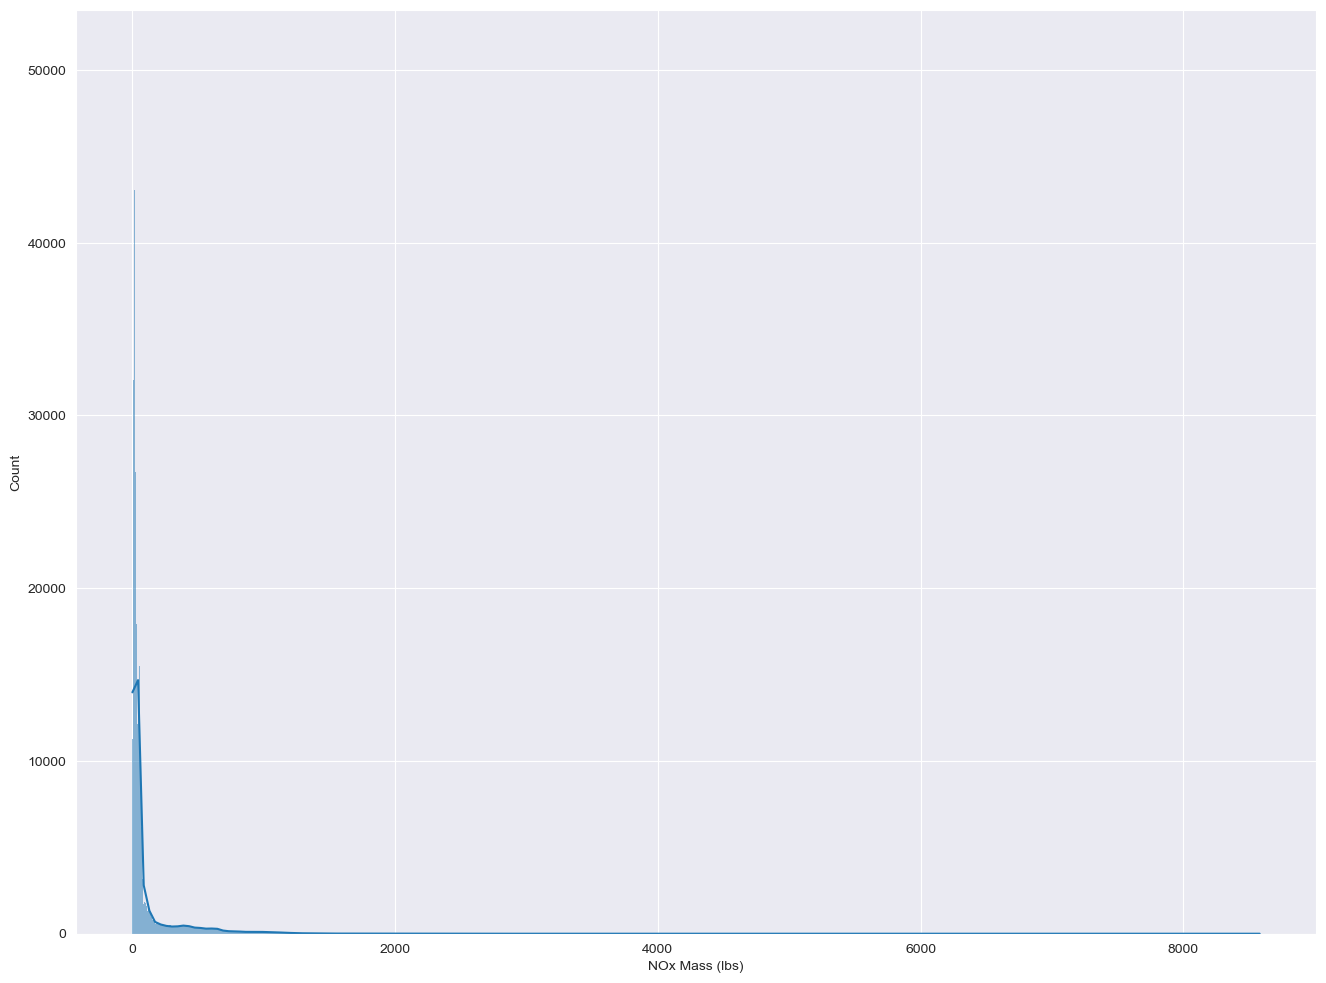

In [48]:
sns.histplot(campd_tx['NOx Mass (lbs)'], kde=True)

<Axes: xlabel='log_NOx', ylabel='Count'>

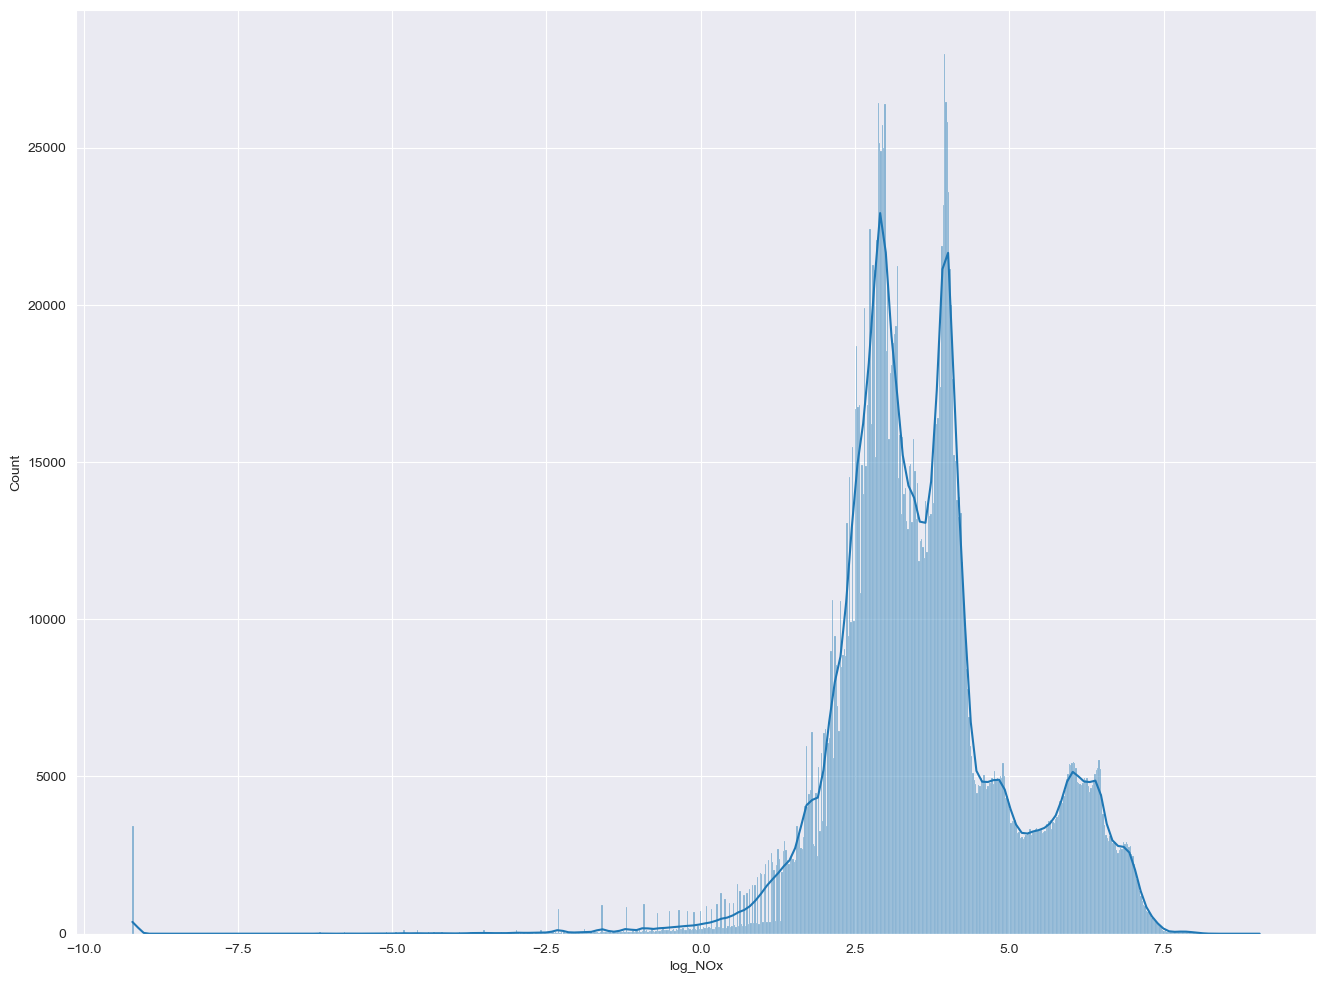

In [ ]:
sns.histplot(campd_tx['log_NOx'], kde=True)

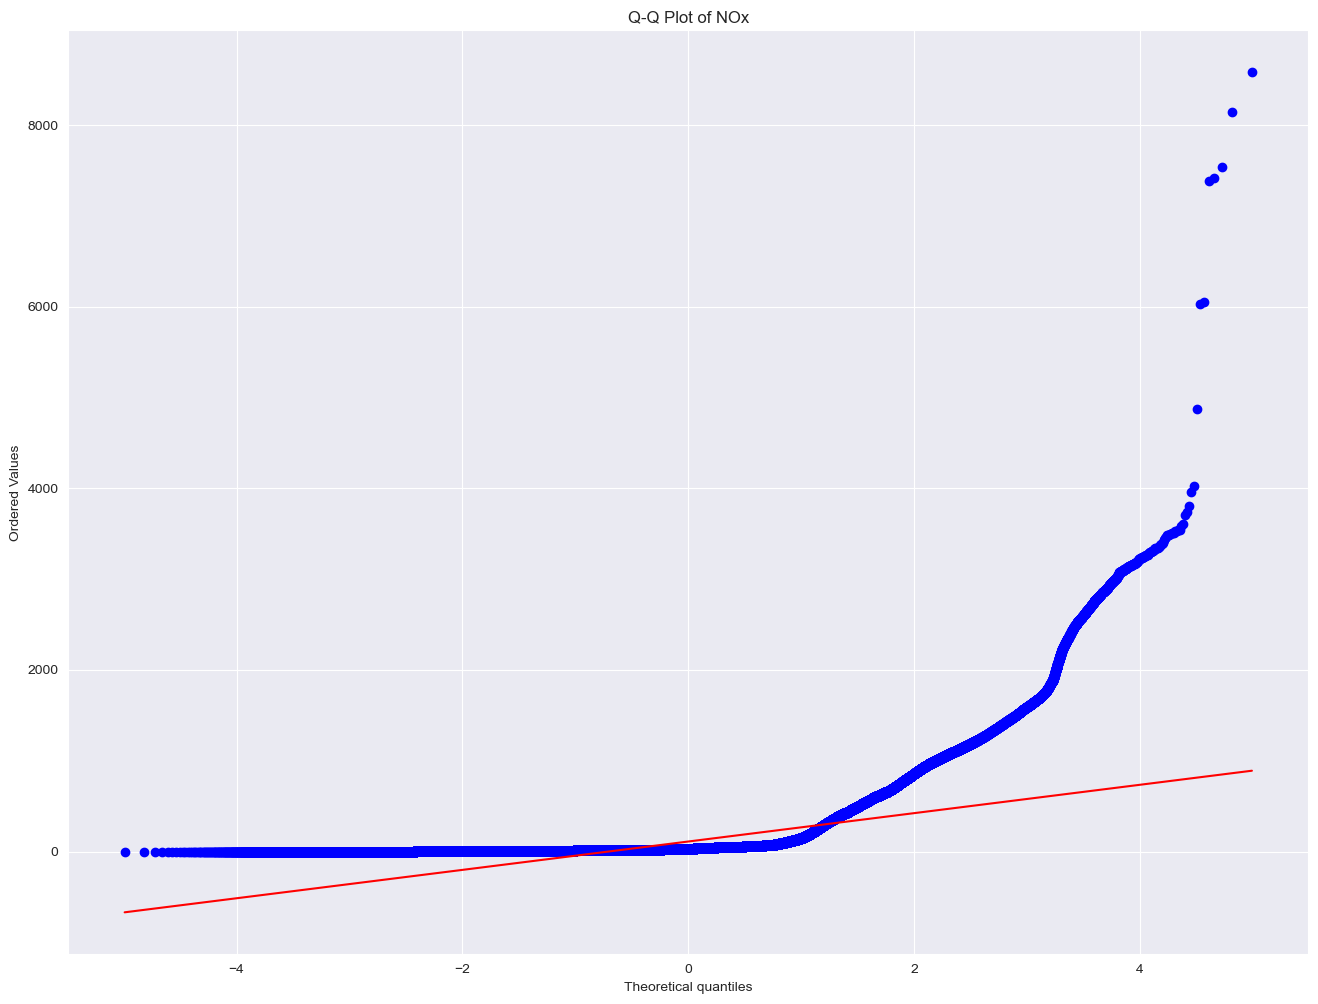

In [ ]:
stats.probplot(campd_tx['NOx Mass (lbs)'], dist="norm", plot=plt)
plt.title("Q-Q Plot of NOx")
plt.show()

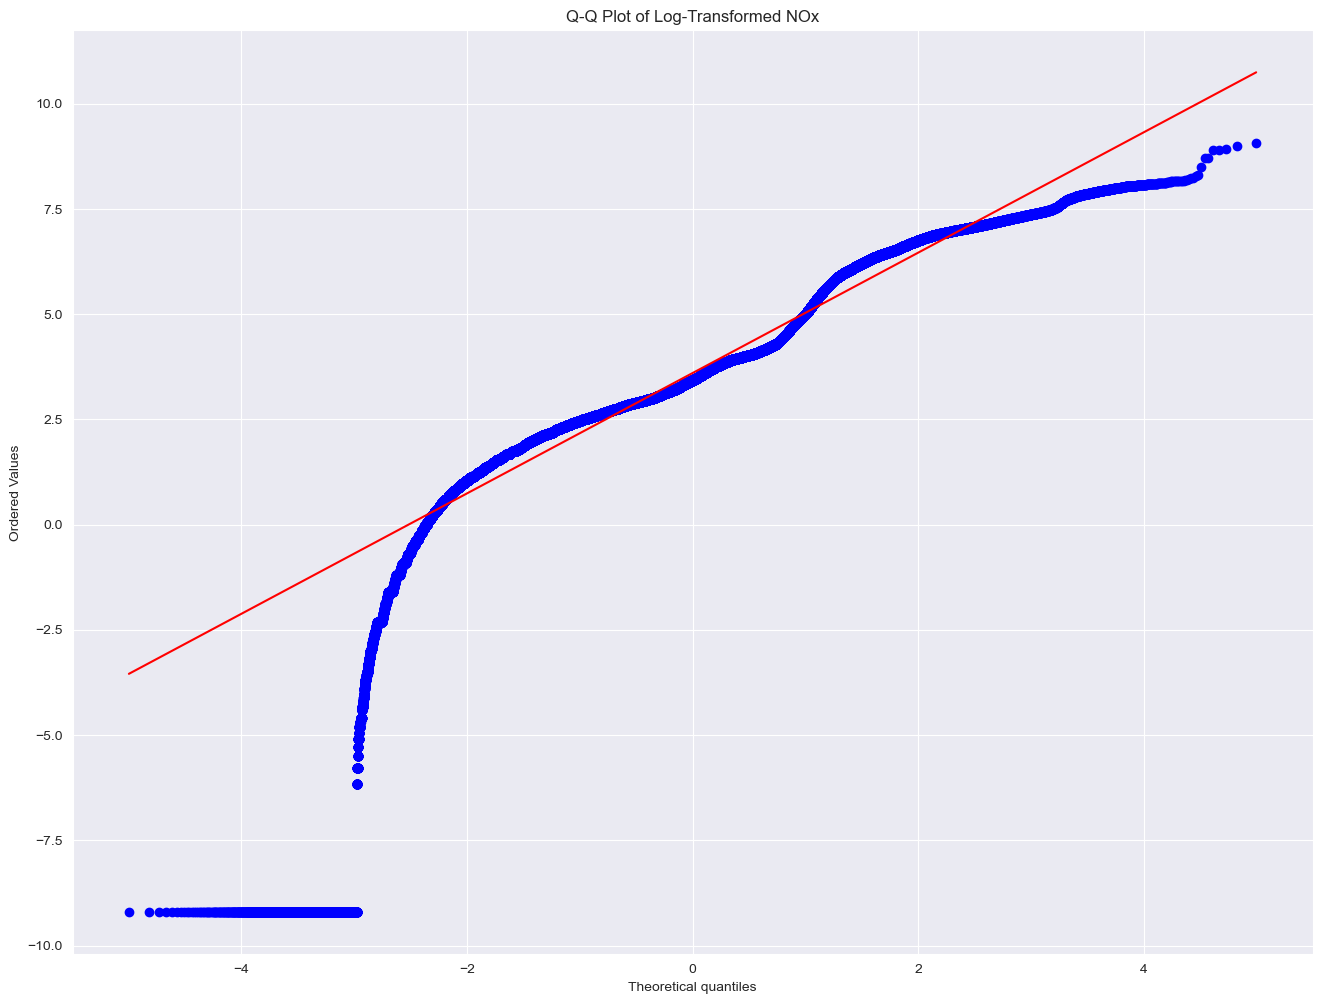

In [ ]:
stats.probplot(campd_tx['log_NOx'], dist="norm", plot=plt)
plt.title("Q-Q Plot of Log-Transformed NOx")
plt.show()

<h4>Spearman (numerical)</h4>

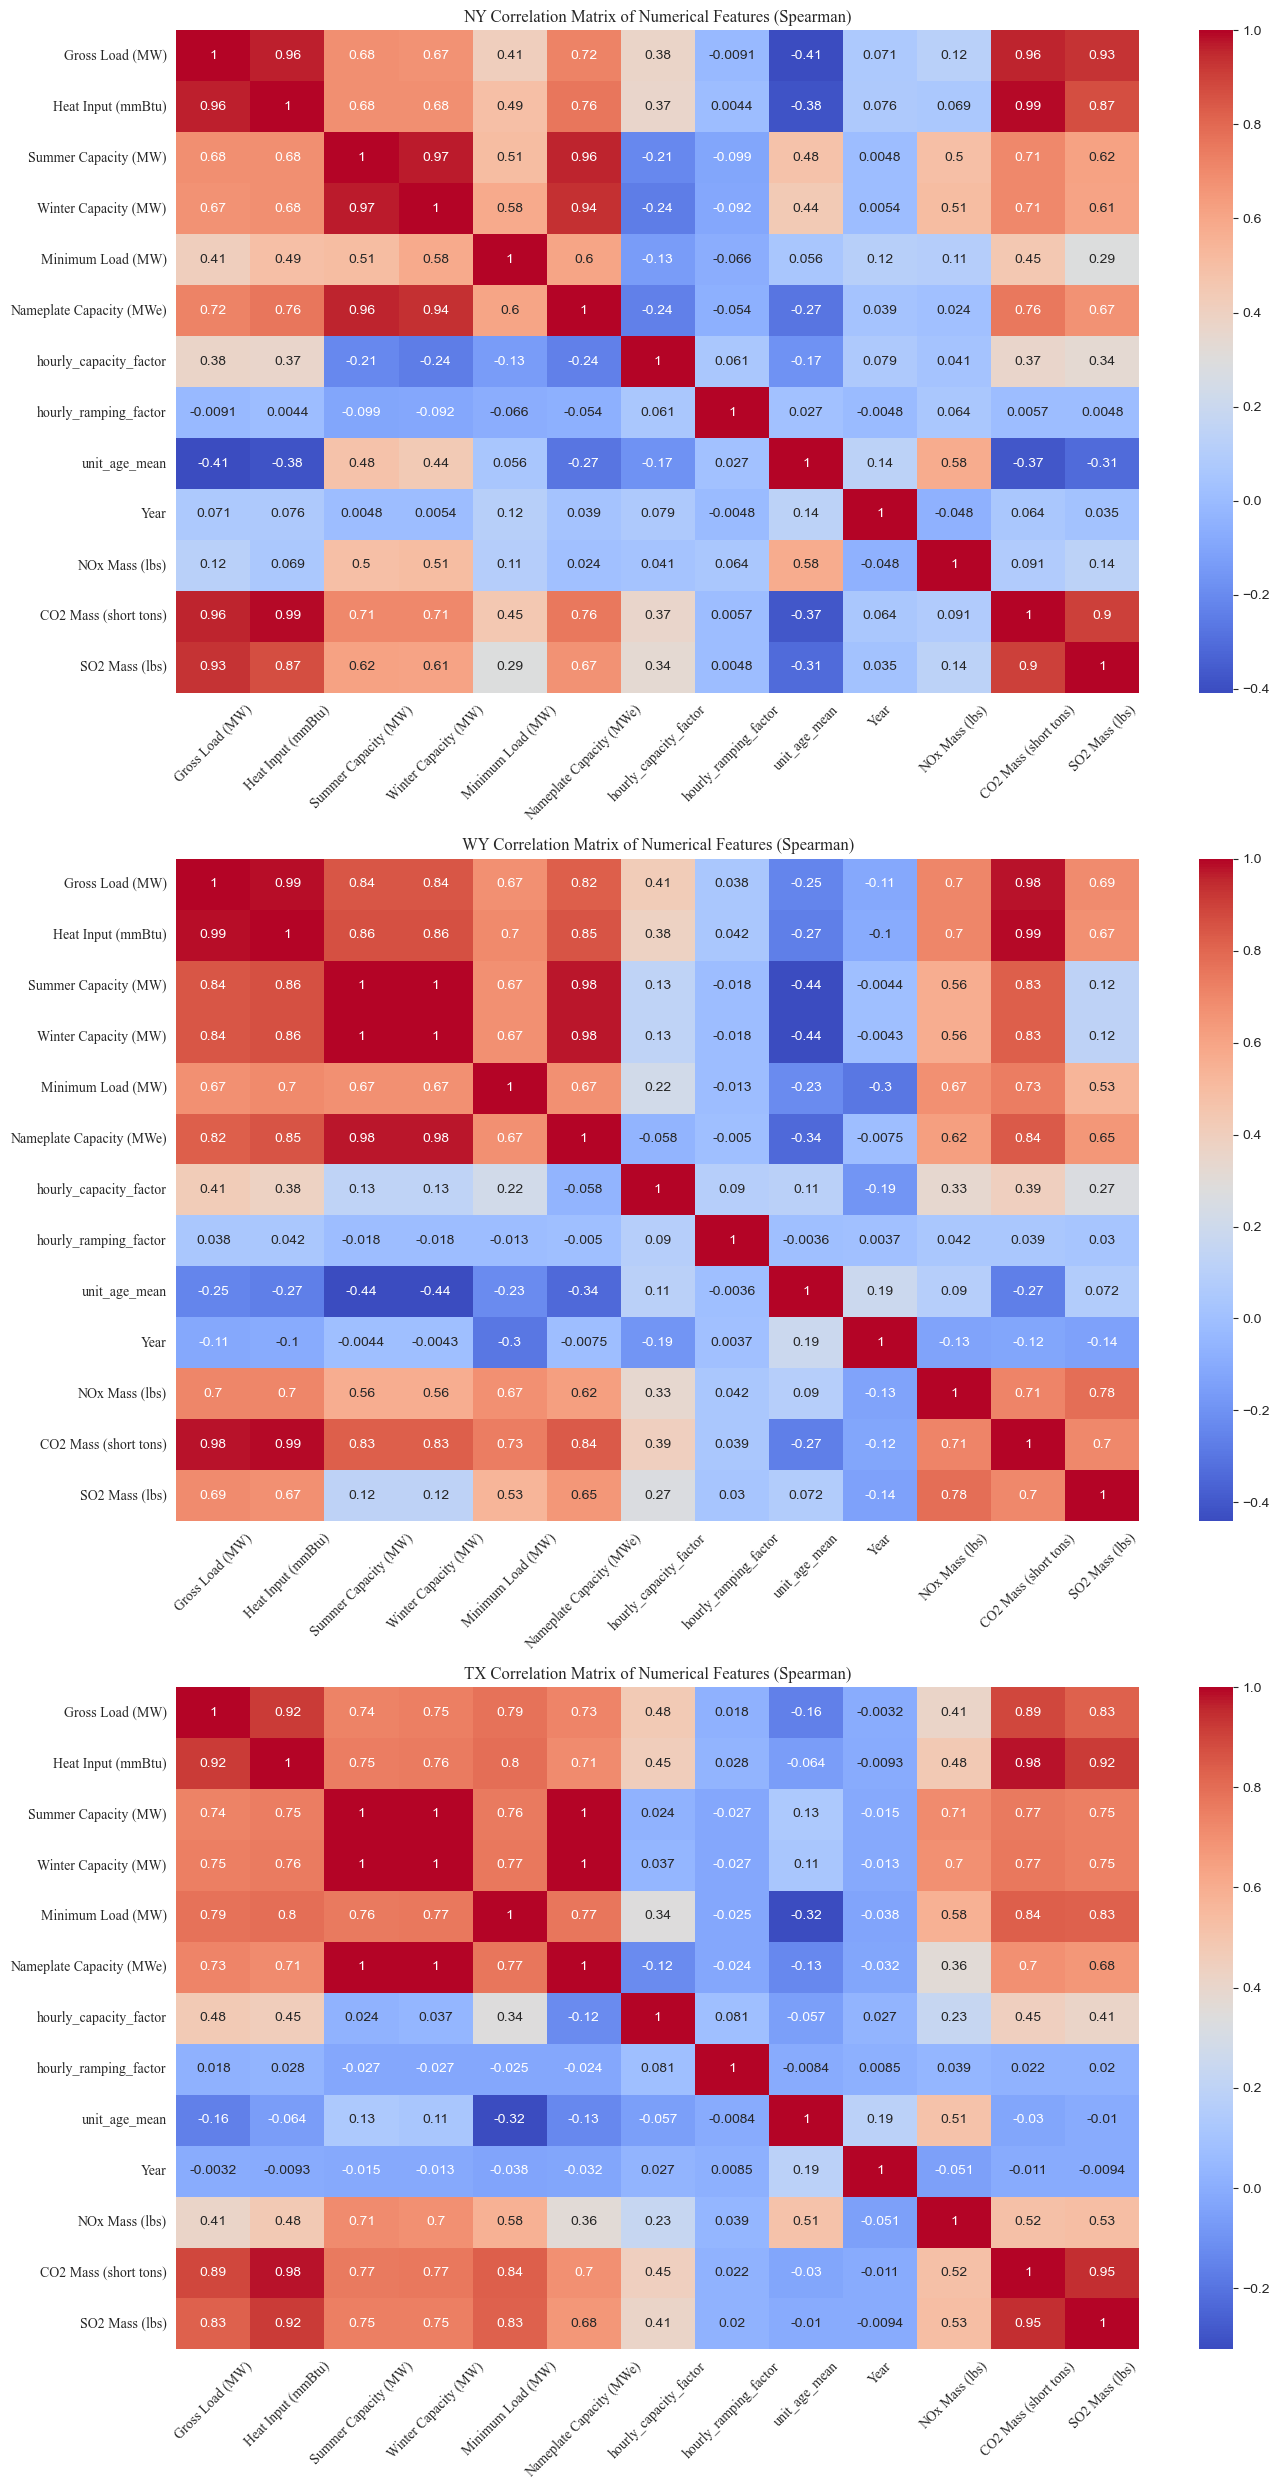

In [10]:
# Define numerical features
num_features = [
    'Gross Load (MW)', 'Heat Input (mmBtu)',
    # 'Latitude', 'Longitude', 
    "Summer Capacity (MW)", "Winter Capacity (MW)", 'Minimum Load (MW)',
    'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
    'hourly_ramping_factor', 'unit_age_mean', 'Year',
    'NOx Mass (lbs)', "CO2 Mass (short tons)", "SO2 Mass (lbs)"
]

# Compute Spearman correlation matrices
corr_matrices = {
    "NY": campd_ny[num_features].corr(method='spearman'),
    "WY": campd_wy[num_features].corr(method='spearman'),
    "TX": campd_tx[num_features].corr(method='spearman')
}

# Plot heatmaps
fig, axes = plt.subplots(3, 1, figsize=(14, 25))

for ax, (state, corr_matrix) in zip(axes, corr_matrices.items()):
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", ax=ax)
    ax.set_title(f"{state} Correlation Matrix of Numerical Features (Spearman)", fontname="Times New Roman")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, fontname="Times New Roman")
    ax.set_yticklabels(ax.get_yticklabels(), fontname="Times New Roman")

plt.tight_layout()
plt.show()

<h4>Chi-Square/Cramers V (cat to cat)</h4>

In [57]:
categorical_features = ['Source Category', 'NOx Phase', 
    'Unit Type', 'Primary Fuel Type', 'Secondary Fuel Type', 
    'NOx Controls', "Program Code", "SO2 Controls", "SO2 Phase"
]

In [65]:
contingency_table = pd.crosstab(campd_wy["Unit Type"], campd_wy["NOx Controls"])
display(contingency_table.shape)
pd.set_option('display.max_columns', None)
display(contingency_table.head())


(4, 19)

NOx Controls,Dry Low NOx Burners,"Dry Low NOx Burners,Selective Catalytic Reduction",Dry Low NOx Burners|Selective Catalytic Reduction,"Low NOx Burner Technology (Dry Bottom only),Selective Catalytic Reduction",Low NOx Burner Technology (Dry Bottom only)|Selective Catalytic Reduction,Low NOx Burner Technology w/ Closed-coupled OFA,Low NOx Burner Technology w/ Overfire Air,"Low NOx Burner Technology w/ Overfire Air,Selective Catalytic Reduction",Low NOx Burner Technology w/ Overfire Air|Selective Catalytic Reduction,Low NOx Burner Technology w/ Separated OFA,Nothing,"Overfire Air,Selective Catalytic Reduction (Began Jun 27, 2019),Low NOx Burner Technology (Dry Bottom only)","Overfire Air,Selective Catalytic Reduction,Low NOx Burner Technology (Dry Bottom only)","Overfire Air,Selective Non-catalytic Reduction,Low NOx Burner Technology (Dry Bottom only)",Overfire Air|Selective Catalytic Reduction|Low NOx Burner Technology (Dry Bottom only),Overfire Air|Selective Non-catalytic Reduction|Low NOx Burner Technology (Dry Bottom only),Selective Catalytic Reduction,"Selective Catalytic Reduction,Low NOx Burner Technology w/ Closed-coupled OFA",Selective Catalytic Reduction|Low NOx Burner Technology w/ Closed-coupled OFA
Unit Type,,,,,,,,,,,,,,,,,,,
Combined cycle,0,48948,11808,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Combustion turbine,19560,2378,548,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Dry bottom wall-fired boiler,0,0,0,41352,8025,0,141703,81858,15067,0,95841,4662,22074,75400,6147,13919,46501,0,0
Tangentially-fired,0,0,0,0,0,95816,0,0,0,164016,0,0,0,0,0,0,0,80766,17039


In [ ]:
contingency_table = pd.crosstab(campd_ny["NOx Phase"], campd_ny["NOx Controls"])
display(contingency_table.shape)
pd.set_option('display.max_columns', None)
display(contingency_table.head())

# there are no overlaps between subsets -> cramers v of 1, only a small number of rows have a NOx phase, most have nothing
# same thing is happening with SO2 Controls and NOx Controls (only a small number of rows have a specific SO2 Control and they have only one combination of NOx Controls)
# also for wy unit type and nox controls

# concern for the model: this may serve as a proxy to identify specific units

(4, 37)

NOx Controls,"Ammonia Injection,Selective Catalytic Reduction",Ammonia Injection|Selective Catalytic Reduction,Dry Low NOx Burners,"Dry Low NOx Burners,Ammonia Injection","Dry Low NOx Burners,Selective Catalytic Reduction","Dry Low NOx Burners,Water Injection,Ammonia Injection,Selective Catalytic Reduction","Dry Low NOx Burners,Water Injection,Selective Catalytic Reduction",Dry Low NOx Burners|Ammonia Injection,Dry Low NOx Burners|Selective Catalytic Reduction,Dry Low NOx Burners|Water Injection|Ammonia Injection|Selective Catalytic Reduction,Dry Low NOx Burners|Water Injection|Selective Catalytic Reduction,Low NOx Burner Technology (Dry Bottom only),Low NOx Burner Technology w/ Closed-coupled OFA,"Low NOx Burner Technology w/ Closed-coupled OFA,Selective Catalytic Reduction",Low NOx Burner Technology w/ Closed-coupled OFA|Selective Catalytic Reduction,"Low NOx Burner Technology w/ Closed-coupled/Separated OFA,Selective Catalytic Reduction",Low NOx Burner Technology w/ Separated OFA,Nothing,Other,"Other,Water Injection",Other|Water Injection,Overfire Air,"Overfire Air,Low NOx Burner Technology w/ Separated OFA",Overfire Air|Low NOx Burner Technology w/ Separated OFA,Selective Catalytic Reduction,"Selective Catalytic Reduction,Low NOx Burner Technology (Dry Bottom only)","Selective Catalytic Reduction,Steam Injection","Selective Catalytic Reduction,Water Injection",Selective Catalytic Reduction|Steam Injection,Selective Catalytic Reduction|Water Injection,Steam Injection,Water Injection,"Water Injection (Began Jul 01, 2022)","Water Injection,Ammonia Injection","Water Injection,Selective Catalytic Reduction",Water Injection|Ammonia Injection,Water Injection|Selective Catalytic Reduction
NOx Phase,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Early Election,0,0,0,0,0,0,0,0,0,0,0,1229,0,0,0,0,0,0,0,0,0,0,0,0,0,1749,0,0,0,0,0,0,0,0,0,0,0
Nothing,75358,15291,24043,34529,162257,38967,527983,7907,41293,6234,115828,0,10491,0,0,0,0,440976,6760,2372,202,58862,88150,21154,194282,0,17596,10305,2331,1229,132035,86597,64,17854,176748,4069,30103
Phase 1 Group 1,0,0,0,0,0,0,0,0,0,0,0,0,0,34572,8567,1439,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Phase 2 Group 1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1275,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


C:\Users\marce\AppData\Local\Temp\ipykernel_19920\2118698343.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cramers_v_df.fillna(1, inplace=True)


,Source Category,NOx Phase,Unit Type,Primary Fuel Type,Secondary Fuel Type,NOx Controls,Program Code,SO2 Controls,SO2 Phase
Source Category,1.000000,0.058196,0.233808,0.105615,0.185662,0.456419,0.181867,0.056654,0.254730
NOx Phase,0.058196,1.000000,0.202819,0.335230,0.568802,1.000000,0.342313,0.807525,0.406748
Unit Type,0.233808,0.202819,1.000000,0.527619,0.612560,0.596106,0.498215,0.229930,0.572751
Primary Fuel Type,0.105615,0.335230,0.527619,1.000000,0.676803,0.671878,0.354079,0.707540,0.378635
Secondary Fuel Type,0.185662,0.568802,0.612560,0.676803,1.000000,0.688390,0.435685,0.709621,0.608998
NOx Controls,0.456419,1.000000,0.596106,0.671878,0.688390,1.000000,0.499423,1.000000,0.771578
Program Code,0.181867,0.342313,0.498215,0.354079,0.435685,0.499423,1.000000,0.164784,0.750945
SO2 Controls,0.056654,0.807525,0.229930,0.707540,0.709621,1.000000,0.164784,1.000000,0.402600
SO2 Phase,0.254730,0.406748,0.572751,0.378635,0.608998,0.771578,0.750945,0.402600,1.000000


C:\Users\marce\AppData\Local\Temp\ipykernel_19920\2118698343.py:42: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cramers_v_df.fillna(1, inplace=True)


,Source Category,NOx Phase,Unit Type,Primary Fuel Type,Secondary Fuel Type,NOx Controls,Program Code,SO2 Controls,SO2 Phase
Source Category,1.000000,0.191035,0.284401,0.221587,0.455844,0.468190,0.179999,0.123400,1.000000
NOx Phase,0.191035,1.000000,0.625407,0.861836,0.587296,0.843146,0.933585,0.628472,0.024599
Unit Type,0.284401,0.625407,1.000000,0.611087,0.217992,0.337762,0.434345,0.578167,0.201814
Primary Fuel Type,0.221587,0.861836,0.611087,1.000000,0.375223,0.481845,0.500287,0.393652,0.031490
Secondary Fuel Type,0.455844,0.587296,0.217992,0.375223,1.000000,0.486494,0.367771,0.297094,0.319476
NOx Controls,0.468190,0.843146,0.337762,0.481845,0.486494,1.000000,0.652334,0.795225,0.502413
Program Code,0.179999,0.933585,0.434345,0.500287,0.367771,0.652334,1.000000,0.471004,0.032707
SO2 Controls,0.123400,0.628472,0.578167,0.393652,0.297094,0.795225,0.471004,1.000000,0.022472
SO2 Phase,1.000000,0.024599,0.201814,0.031490,0.319476,0.502413,0.032707,0.022472,1.000000


C:\Users\marce\AppData\Local\Temp\ipykernel_19920\2118698343.py:73: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cramers_v_df.fillna(1, inplace=True)


,NOx Phase,Unit Type,Primary Fuel Type,Secondary Fuel Type,NOx Controls,Program Code,SO2 Controls
NOx Phase,1.000000,0.515527,0.237981,0.721767,0.842691,0.327665,0.431787
Unit Type,0.515527,1.000000,0.585373,0.427948,0.971238,0.826571,0.582525
Primary Fuel Type,0.237981,0.585373,1.000000,0.120058,0.593247,1.000000,0.864952
Secondary Fuel Type,0.721767,0.427948,0.120058,1.000000,0.721767,0.119419,0.519258
NOx Controls,0.842691,0.971238,0.593247,0.721767,1.000000,0.835395,0.751807
Program Code,0.327665,0.826571,1.000000,0.119419,0.835395,1.000000,0.704530
SO2 Controls,0.431787,0.582525,0.864952,0.519258,0.751807,0.704530,1.000000


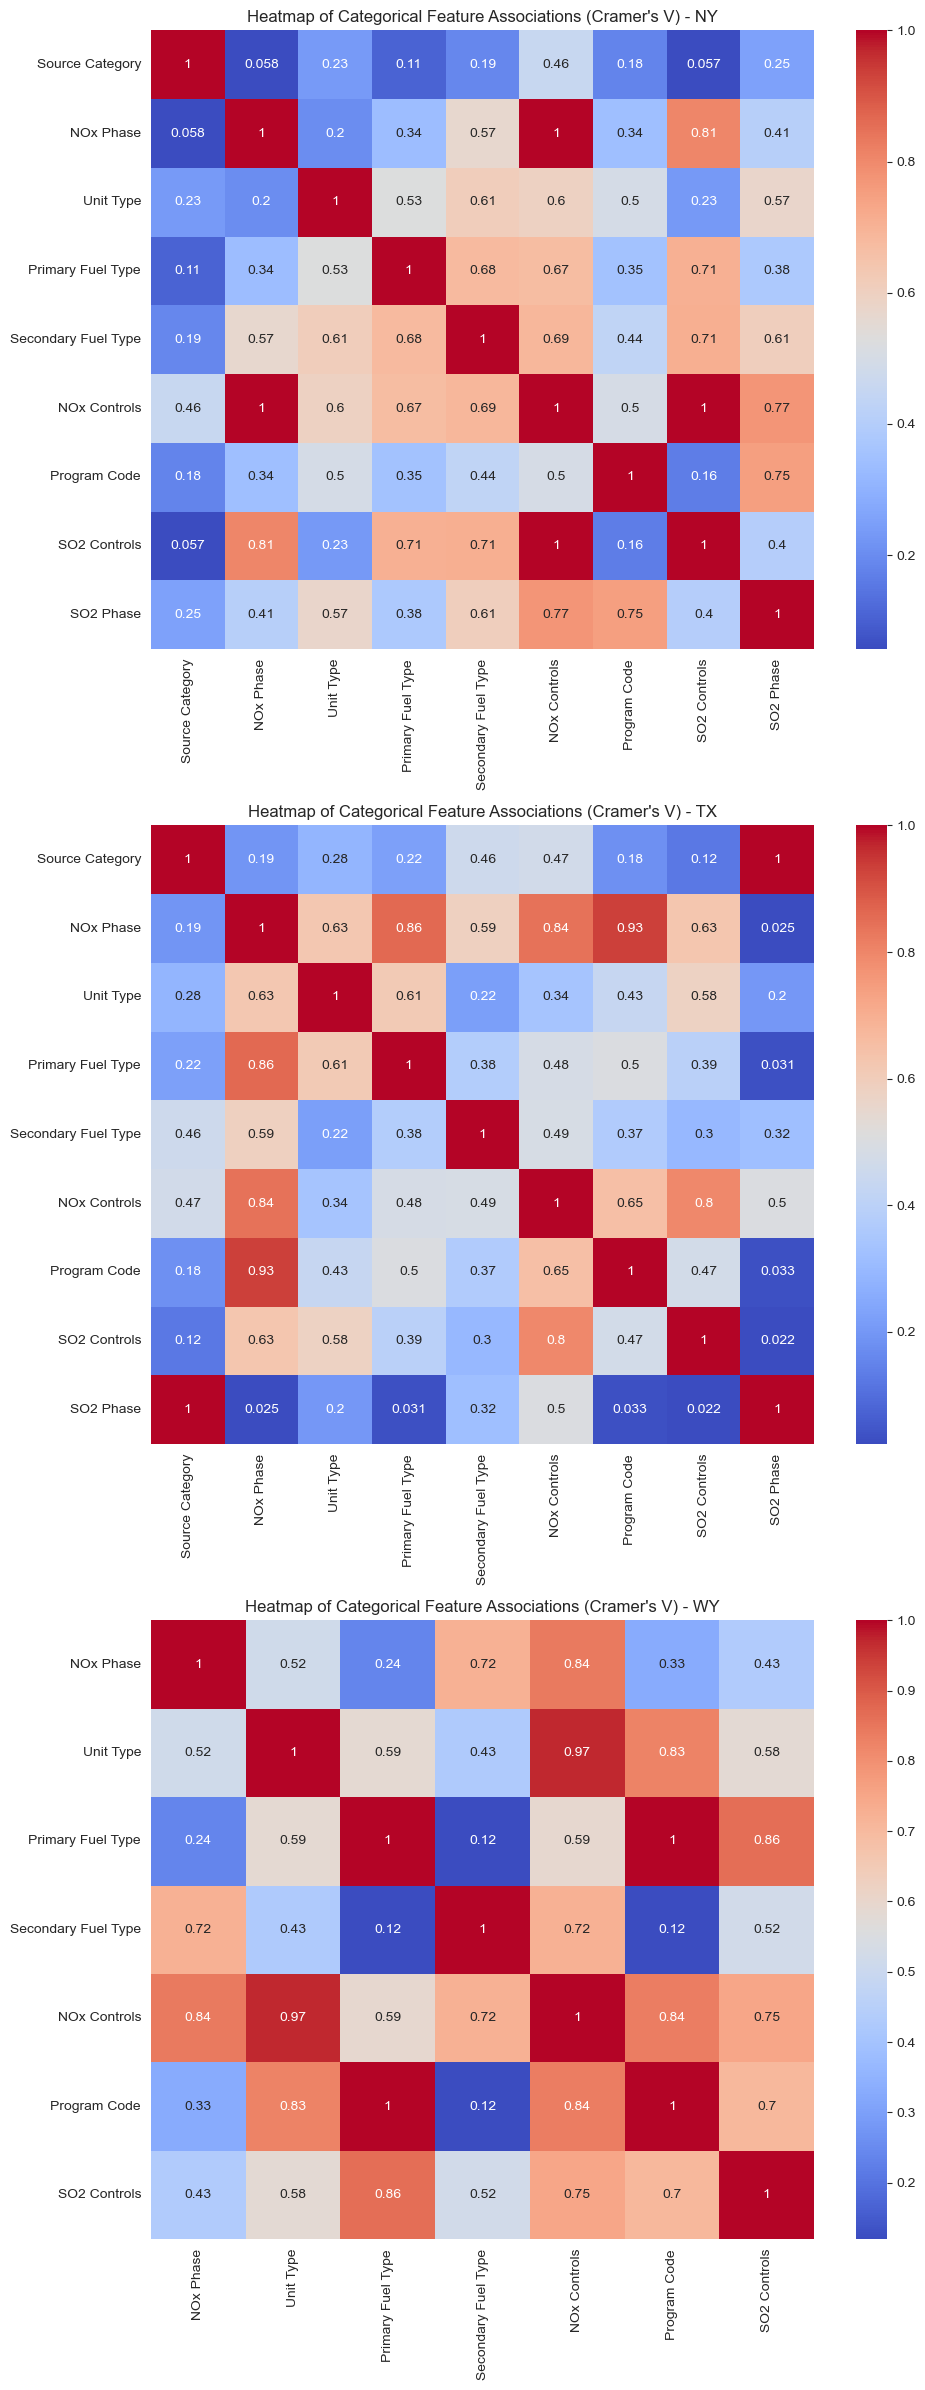

In [53]:
cramers_v_df = pd.DataFrame(index=categorical_features, columns=categorical_features)

# Calculate Cramer's V for each pair of categorical features
for i, feature1 in enumerate(categorical_features):
    for feature2 in categorical_features[i+1:]:
        # Create contingency table
        contingency_table = pd.crosstab(campd_ny[feature1], campd_ny[feature2])
        
        # Calc Cramer's V
        cramers_v = association(contingency_table.values, method='cramer')
        
        # Store result
        cramers_v_df.loc[feature1, feature2] = cramers_v
        cramers_v_df.loc[feature2, feature1] = cramers_v

# Replace NaN with zero for diagonal elements which were not calculated
cramers_v_df.fillna(1, inplace=True)

display(cramers_v_df)

fig, axs = plt.subplots(3, 1, figsize=(10, 24))

sns.heatmap(cramers_v_df, annot=True, cmap="coolwarm", mask=cramers_v_df.isnull(), ax=axs[0])
axs[0].set_title("Heatmap of Categorical Feature Associations (Cramer's V) - NY")

cramers_v_df = pd.DataFrame(index=categorical_features, columns=categorical_features)

# Calculate Cramer's V for each pair of categorical features
for i, feature1 in enumerate(categorical_features):
    for feature2 in categorical_features[i+1:]:
        # Create contingency table
        contingency_table = pd.crosstab(campd_tx[feature1], campd_tx[feature2])
        
        # Calc Cramer's V
        cramers_v = association(contingency_table.values, method='cramer')
        
        # Store result
        cramers_v_df.loc[feature1, feature2] = cramers_v
        cramers_v_df.loc[feature2, feature1] = cramers_v

# Replace NaN with zero for diagonal elements which were not calculated
cramers_v_df.fillna(1, inplace=True)

display(cramers_v_df)

sns.heatmap(cramers_v_df, annot=True, cmap="coolwarm", mask=cramers_v_df.isnull(), ax=axs[1])
axs[1].set_title("Heatmap of Categorical Feature Associations (Cramer's V) - TX")

# remove any categorical features from the list that only have a single value
categorical_features_adjusted = categorical_features.copy()

for category in categorical_features:
    if len(campd_wy[category].unique()) == 1:
        categorical_features_adjusted.remove(category)

cramers_v_df = pd.DataFrame(index=categorical_features_adjusted, columns=categorical_features_adjusted) 

# Calculate Cramer's V for each pair of categorical features
for i, feature1 in enumerate(categorical_features_adjusted):
    for feature2 in categorical_features_adjusted[i+1:]:
        # Create contingency table
        contingency_table = pd.crosstab(campd_wy[feature1], campd_wy[feature2])
        #display(contingency_table)
        
        # Calc Cramer's V
        cramers_v = association(contingency_table.values, method='cramer')
        
        # Store result
        cramers_v_df.loc[feature1, feature2] = cramers_v
        cramers_v_df.loc[feature2, feature1] = cramers_v

# Replace NaN with zero for diagonal elements which were not calculated
cramers_v_df.fillna(1, inplace=True)

display(cramers_v_df)

sns.heatmap(cramers_v_df, annot=True, cmap="coolwarm", mask=cramers_v_df.isnull(), ax=axs[2])
axs[2].set_title("Heatmap of Categorical Feature Associations (Cramer's V) - WY")

plt.tight_layout()
plt.show()


<h4>Kruskal-Wallis (cat to num)</h4>

In [ ]:
# prerequisites for ANOVA not given, NOx is neither normally distributed nor does it have equal variance among groups
# instead we use the non-parametric Kruskal-Wallis test which only requires ordinality

<h5>NOx</h5>

In [83]:
numerical_features = [
    "Gross Load (MW)", "Heat Input (mmBtu)", "Longitude", "Latitude",
    "CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Nameplate Capacity (MWe)", "Temperature (F)"
]

categorical_features = [
    'Source Category', 'NOx Phase', 
    'Unit Type', 'Primary Fuel Type', 'Secondary Fuel Type', 
    'NOx Controls', "Program Code", "SO2 Controls",
    "SO2 Phase", 
    "Random_Category"
]

target_variable = "NOx Mass (lbs)"


In [ ]:
NOx_emissions = campd_ny["NOx Mass (lbs)"]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C'] 
campd_ny['Random_Category'] = np.random.choice(categories, size=len(campd_ny))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:
    feature_names.append(feature)

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  # Track total sample size across groups
    num_groups = len(campd_ny[feature].unique())

    for i in range(n_iterations):
        groups = []
        for group in campd_ny[feature].unique():
            group_data = NOx_emissions[campd_ny[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups])  

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-Squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
5,NOx Controls,11804.509,0.000,0.664
7,SO2 Controls,834.644,0.000,0.556
6,Program Code,4674.343,0.000,0.552
4,Secondary Fuel Type,1666.061,0.000,0.475
3,Primary Fuel Type,1066.277,0.000,0.426
2,Unit Type,1217.719,0.000,0.405
8,SO2 Phase,207.193,0.000,0.137
0,Source Category,101.694,0.000,0.067
1,NOx Phase,81.943,0.000,0.040
9,Random_Category,2.851,0.322,0.001


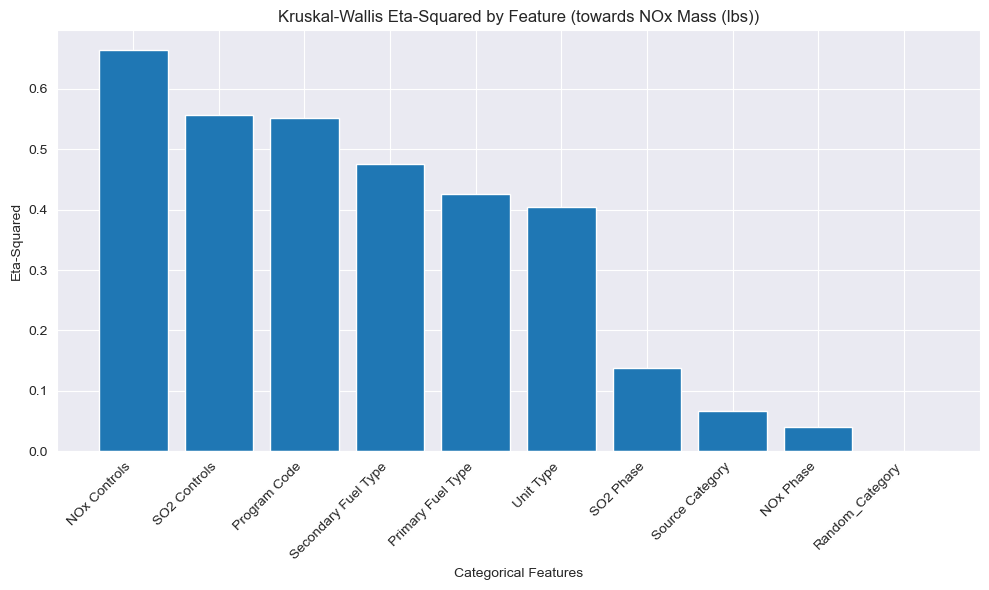

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title('Kruskal-Wallis Eta-Squared by Feature (towards NOx Mass (lbs))')
plt.tight_layout()
plt.show()

# ~66% of the variance in NOx Mass can be explained by NOx Controls

In [ ]:
NOx_emissions = campd_tx["NOx Mass (lbs)"]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']  # Define the possible categories
campd_tx['Random_Category'] = np.random.choice(categories, size=len(campd_tx))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:
    feature_names.append(feature)

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0 
    num_groups = len(campd_tx[feature].unique()) 

    for i in range(n_iterations):
        groups = []
        for group in campd_tx[feature].unique():
            group_data = NOx_emissions[campd_tx[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (Eta-Squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
3,Primary Fuel Type,1719.663,0.000,0.688
6,Program Code,1675.122,0.000,0.670
2,Unit Type,6994.167,0.000,0.668
5,NOx Controls,10948.953,0.000,0.654
1,NOx Phase,613.794,0.000,0.614
7,SO2 Controls,1415.100,0.000,0.566
4,Secondary Fuel Type,2623.165,0.000,0.476
0,Source Category,310.267,0.000,0.206
8,SO2 Phase,95.246,0.000,0.094
9,Random_Category,2.050,0.430,0.000


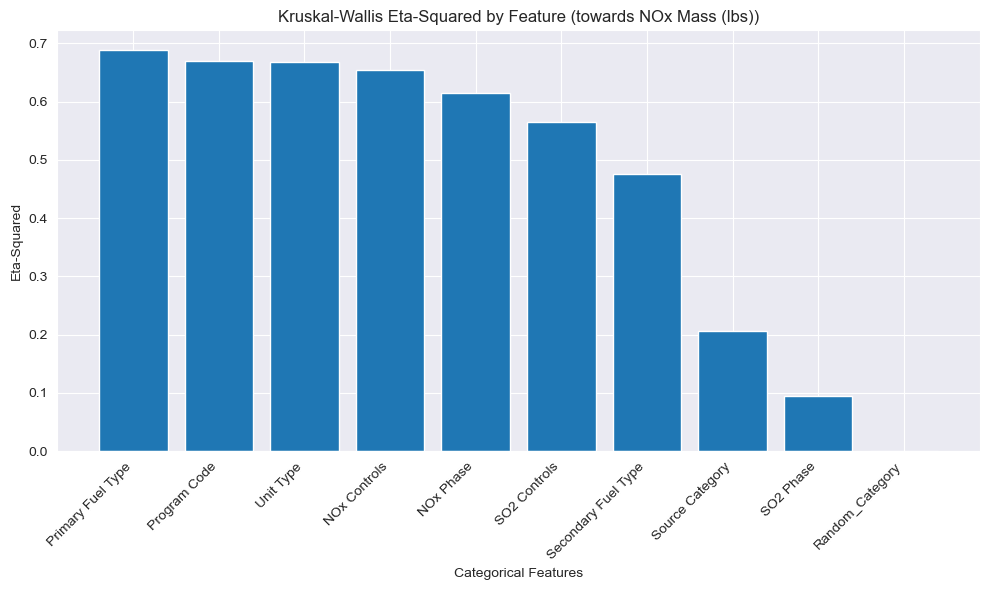

In [86]:
# eta squared scales from 0 to 1
# it measures the variance in the dependent variable explained by the independent variable (akin to R^2)

plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title('Kruskal-Wallis Eta-Squared by Feature (towards NOx Mass (lbs))')
plt.tight_layout()
plt.show()

In [ ]:
NOx_emissions = campd_wy["NOx Mass (lbs)"]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C'] 
campd_wy['Random_Category'] = np.random.choice(categories, size=len(campd_wy))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_wy[feature].unique())  
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_wy[feature].unique():
            group_data = NOx_emissions[campd_wy[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
4,NOx Controls,7575.831,0.000,0.797
1,Unit Type,1577.110,0.000,0.789
5,Program Code,502.525,0.000,0.503
0,NOx Phase,944.603,0.000,0.377
2,Primary Fuel Type,557.416,0.000,0.371
6,SO2 Controls,397.336,0.000,0.158
3,Secondary Fuel Type,51.262,0.000,0.050
7,Random_Category,1.033,0.619,-0.001


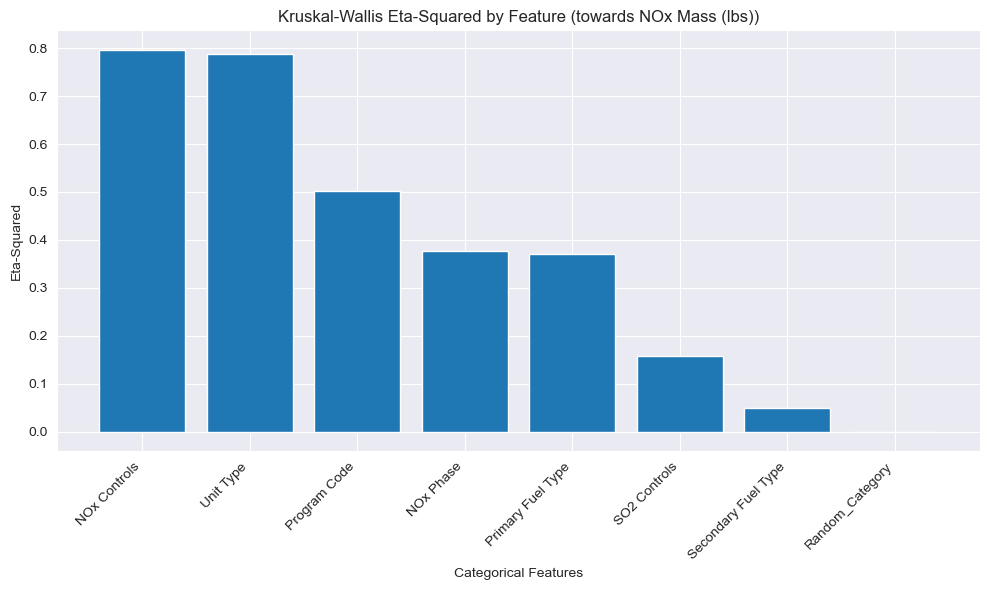

In [90]:
# eta squared scales from 0 to 1
# it measures the variance in the dependent variable explained by the independent variable (akin to R^2)

plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title('Kruskal-Wallis Eta-Squared by Feature (towards NOx Mass (lbs))')
plt.tight_layout()
plt.show()

<h5>CO2</h5>

In [91]:
numerical_features = [
    "Gross Load (MW)", "Heat Input (mmBtu)", "Longitude", "Latitude",
    "CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Nameplate Capacity (MWe)", "Temperature (F)"
]

categorical_features = [
    'Source Category', 'NOx Phase', 
    'Unit Type', 'Primary Fuel Type', 'Secondary Fuel Type', 
    'NOx Controls', "Program Code", "SO2 Controls",
    "SO2 Phase", 
    "Random_Category"
]

target_variable = "CO2 Mass (short tons)"


In [ ]:
emissions = campd_ny[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']  
campd_ny['Random_Category'] = np.random.choice(categories, size=len(campd_ny))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0
    num_groups = len(campd_ny[feature].unique()) 
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_ny[feature].unique():
            group_data = emissions[campd_ny[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups])  

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
6,Program Code,6090.321,0.000,0.720
5,NOx Controls,11681.977,0.000,0.657
2,Unit Type,1674.163,0.000,0.558
3,Primary Fuel Type,1118.115,0.000,0.447
8,SO2 Phase,579.919,0.000,0.386
7,SO2 Controls,560.485,0.000,0.373
4,Secondary Fuel Type,863.137,0.000,0.245
0,Source Category,198.076,0.000,0.131
1,NOx Phase,144.840,0.000,0.071
9,Random_Category,2.696,0.478,0.000


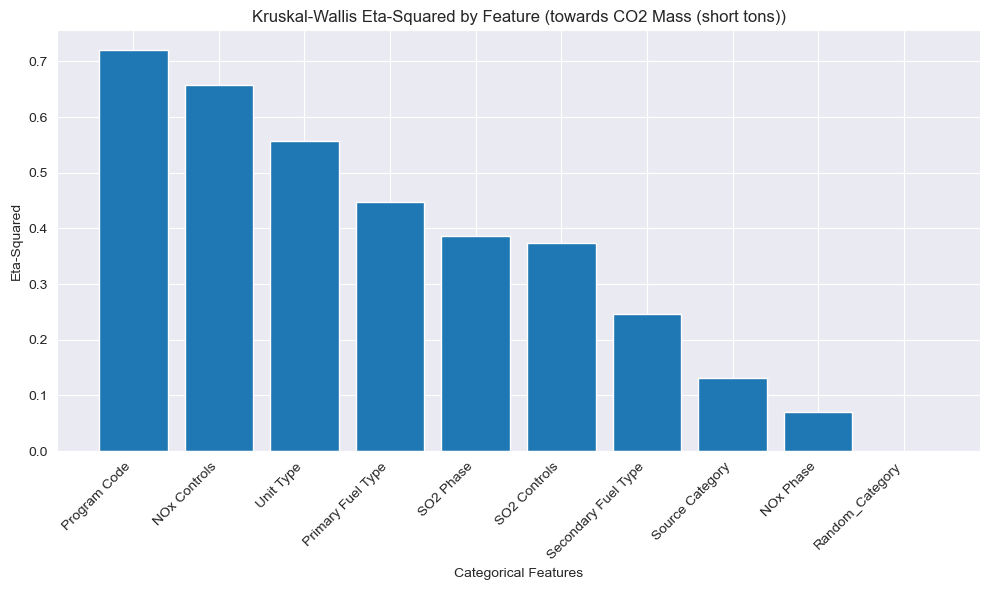

In [95]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

In [ ]:
emissions = campd_tx[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']
campd_tx['Random_Category'] = np.random.choice(categories, size=len(campd_tx))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_tx[feature].unique())  
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_tx[feature].unique():
            group_data = emissions[campd_tx[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups])  

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
7,SO2 Controls,1745.498,0.000,0.698
6,Program Code,1741.968,0.000,0.697
5,NOx Controls,10712.208,0.000,0.639
1,NOx Phase,607.512,0.000,0.608
4,Secondary Fuel Type,3080.485,0.000,0.559
2,Unit Type,5669.588,0.000,0.541
3,Primary Fuel Type,1148.608,0.000,0.459
0,Source Category,262.678,0.000,0.174
8,SO2 Phase,152.374,0.000,0.152
9,Random_Category,2.806,0.385,0.001


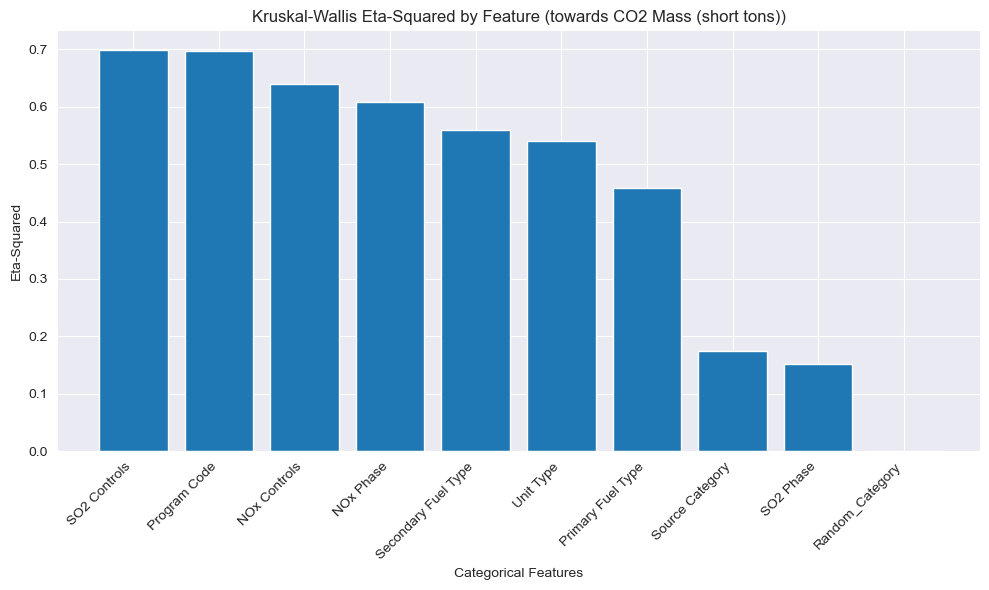

In [97]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

In [ ]:
emissions = campd_wy[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C'] 
campd_wy['Random_Category'] = np.random.choice(categories, size=len(campd_wy))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_wy[feature].unique()) 
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_wy[feature].unique():
            group_data = emissions[campd_wy[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
4,NOx Controls,7699.321,0.000,0.810
1,Unit Type,1436.046,0.000,0.718
5,Program Code,533.801,0.000,0.534
6,SO2 Controls,1273.443,0.000,0.509
2,Primary Fuel Type,568.101,0.000,0.378
0,NOx Phase,703.459,0.000,0.280
3,Secondary Fuel Type,8.142,0.008,0.007
7,Random_Category,0.645,0.743,-0.001


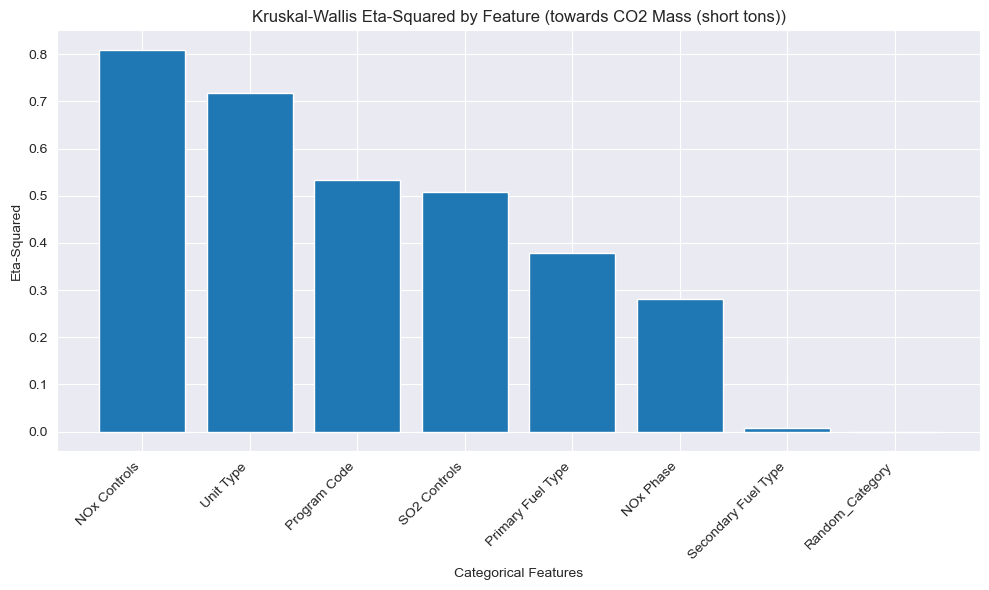

In [93]:
# eta squared scales from 0 to 1
# it measures the variance in the dependent variable explained by the independent variable (akin to R^2)

plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

<h5>SO2</h5>

In [98]:
numerical_features = [
    "Gross Load (MW)", "Heat Input (mmBtu)", "Longitude", "Latitude",
    "CO2 Mass (short tons)", "NOx Mass (lbs)", "SO2 Mass (lbs)", "Nameplate Capacity (MWe)", "Temperature (F)"
]

categorical_features = [
    'Source Category', 'NOx Phase', 
    'Unit Type', 'Primary Fuel Type', 'Secondary Fuel Type', 
    'NOx Controls', "Program Code", "SO2 Controls",
    "SO2 Phase", 
    "Random_Category"
]

target_variable = "SO2 Mass (lbs)"


In [ ]:
emissions = campd_ny[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']
campd_ny['Random_Category'] = np.random.choice(categories, size=len(campd_ny))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_ny[feature].unique())  
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_ny[feature].unique():
            group_data = emissions[campd_ny[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store the average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
5,NOx Controls,12430.316,0.000,0.699
7,SO2 Controls,994.624,0.000,0.663
6,Program Code,4910.146,0.000,0.580
3,Primary Fuel Type,1404.444,0.000,0.561
2,Unit Type,1027.088,0.000,0.341
8,SO2 Phase,294.184,0.000,0.195
4,Secondary Fuel Type,574.460,0.000,0.163
0,Source Category,234.598,0.000,0.155
1,NOx Phase,171.856,0.000,0.085
9,Random_Category,3.147,0.509,0.001


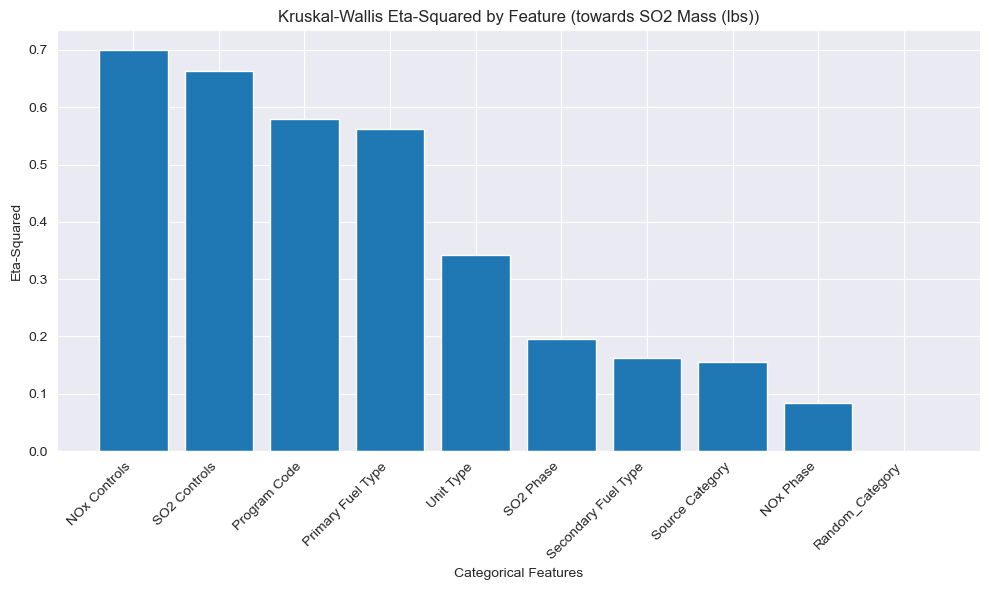

In [104]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

In [ ]:
emissions = campd_tx[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']
campd_tx['Random_Category'] = np.random.choice(categories, size=len(campd_tx))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0  
    num_groups = len(campd_tx[feature].unique()) 
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_tx[feature].unique():
            group_data = emissions[campd_tx[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups])  

        # Perform Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store the average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
6,Program Code,1901.497,0.000,0.761
1,NOx Phase,688.941,0.000,0.689
5,NOx Controls,11533.527,0.000,0.689
4,Secondary Fuel Type,3278.334,0.000,0.595
2,Unit Type,5718.638,0.000,0.545
3,Primary Fuel Type,1217.761,0.000,0.486
7,SO2 Controls,1163.095,0.000,0.465
0,Source Category,319.372,0.000,0.212
8,SO2 Phase,197.643,0.000,0.197
9,Random_Category,1.932,0.452,-0.000


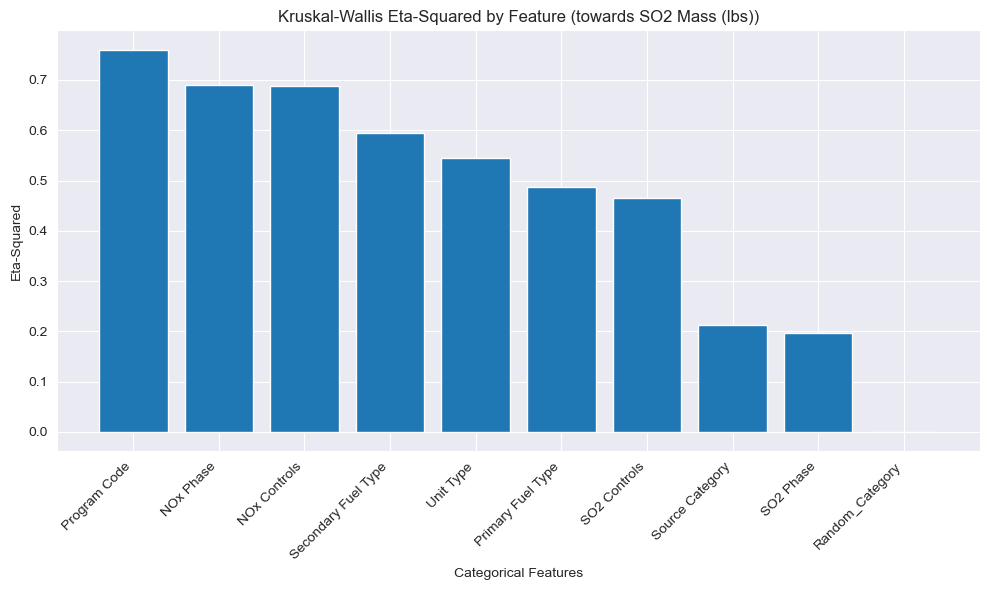

In [102]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()

In [ ]:
emissions = campd_wy[target_variable]

# Add a new column with random categories for testing
categories = ['Category_A', 'Category_B', 'Category_C']
campd_wy['Random_Category'] = np.random.choice(categories, size=len(campd_wy))

feature_names = []
h_statistics = []
p_values = []
eta_squared = []  # To store effect sizes

# Number of bootstrap iterations
n_iterations = 5
sample_size = 500  # Set the cap for each group

for feature in categorical_features:

    # Store bootstrap results for H-statistic and p-value
    bootstrap_h = []
    bootstrap_p = []
    total_sample_size = 0 
    num_groups = len(campd_wy[feature].unique()) 
    if num_groups < 2: # Need min 2 groups
        continue

    feature_names.append(feature)

    for i in range(n_iterations):
        groups = []
        for group in campd_wy[feature].unique():
            group_data = emissions[campd_wy[feature] == group]
            # Random subsample with a different seed for each iteration
            group_sample = group_data.sample(n=min(len(group_data), sample_size), random_state=i)
            groups.append(group_sample)
        total_sample_size = sum([len(group) for group in groups]) 

        # Kruskal-Wallis test
        kruskal_stat, p_value = kruskal(*groups)
        bootstrap_h.append(kruskal_stat)
        bootstrap_p.append(p_value)

    # Store average results across bootstrap iterations
    avg_h = np.mean(bootstrap_h)
    avg_p = np.mean(bootstrap_p)

    h_statistics.append(avg_h)
    p_values.append(avg_p)

    # Calculate effect size (eta-squared)
    eta = (avg_h-num_groups+1)/(total_sample_size-num_groups)
    eta_squared.append(eta)

result_df = pd.DataFrame({
    "Feature": feature_names,
    "Average H Statistic": h_statistics,
    "Average P Value": p_values,
    "Eta-Squared": eta_squared
})

result_df = result_df.sort_values(by="Eta-Squared", ascending=False)

pd.set_option('display.float_format', lambda x: '%.3f' % x)
display(result_df)

,Feature,Average H Statistic,Average P Value,Eta-Squared
4,NOx Controls,7070.167,0.000,0.744
1,Unit Type,1410.486,0.000,0.705
5,Program Code,702.895,0.000,0.703
0,NOx Phase,1423.050,0.000,0.569
2,Primary Fuel Type,522.898,0.000,0.348
6,SO2 Controls,268.036,0.000,0.106
3,Secondary Fuel Type,18.792,0.000,0.018
7,Random_Category,1.735,0.546,-0.000


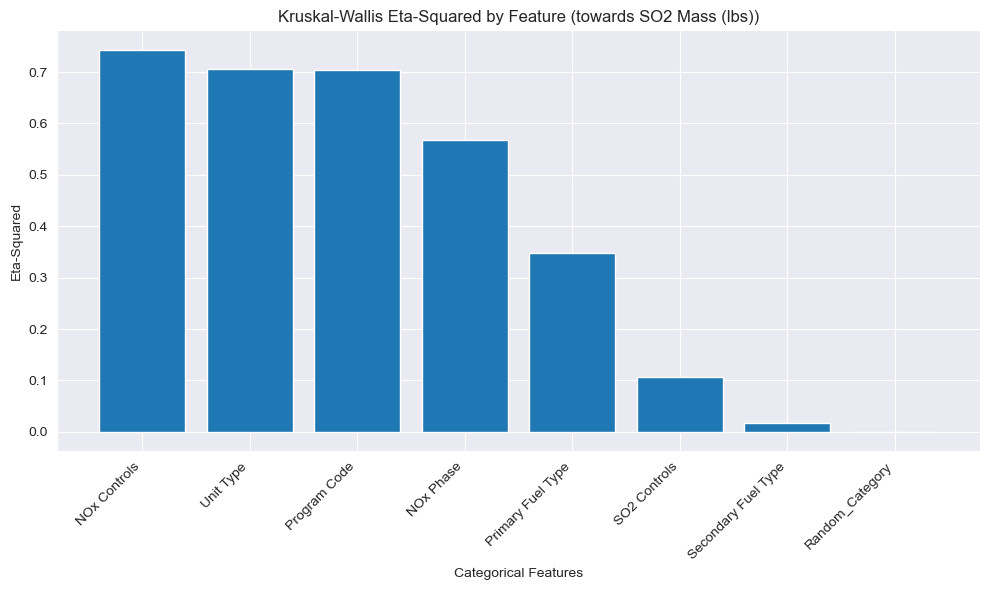

In [100]:
plt.figure(figsize=(10, 6))
plt.bar(result_df["Feature"], result_df["Eta-Squared"])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Categorical Features')
plt.ylabel('Eta-Squared')
plt.title(f'Kruskal-Wallis Eta-Squared by Feature (towards {target_variable})')
plt.tight_layout()
plt.show()